# FairWard supporting evidence

The notebook checks the results reported in *FairWard: Federated Synthetic Data Generation for Healthcare* by Md Jannatul Rakib Joy, Viet Vo and Caslon Chua, in the manuscript version compiled on 9 November 2026. Each numbered section rebuilds one table, figure or group of in-text results from the aggregate files in the archive `FairWard_data.zip` and compares the result with the values printed in the paper.

**Reading the checks.** Sections 1 to 14 each end with a check table, and each claim label starts with the location of the claim in the paper. The `paper` column shows a printed value, with number words written as digits and LaTeX notation written as plain text. When the paper prints a number as a word, the claim label ends with that word in double quotes. The `notebook` column shows the released value in the same format, and the `basis` column says whether that value was recomputed from a result file or read from an audit record. A statement row tests one comparative or descriptive sentence of the paper and reads `holds` or `does not hold`, while a withheld row names a printed number that the released files do not contain.

**Scope.** The checks cover the Abstract, Tables III to IX and Figs. 2 and 3, together with the cohort sizes and run counts in Section IV. They also cover the results of Section V and the results that Sections VI and VII restate. Method definitions and algorithm settings, such as query fractions, cut points and classifier settings, are not derived again here. Because the released files hold aggregates only, the notebook tests whether the printed values follow from the released results; it cannot refit a generator or repeat an experiment. The eICU, MIMIC-III and Texas partitions informed earlier development, so results on them are exploratory (Section IV-A).

**Contents.** A table of the released files comes first, followed by these sections.

1. Cohorts and partitions (Table III)
2. Matched reconstruction controls (Table IV)
3. Workload error of the private generators (Fig. 2)
4. Composition calibration (Table V)
5. Finite-output conditional TV on common contexts
6. Prediction on real records (Table VI, Fig. 3)
7. Matched MIMIC-III comparison with the static FairSynth adaptation (Table VII)
8. Frozen SUPPORT2 replication (Table VIII)
9. Contextual tree and the locked CRASH-2 holdout
10. Richer ordinal variant
11. Controlled heterogeneity (Table IX)
12. Computational cost
13. Privacy evidence and implementation checks
14. Abstract, limitations and conclusion
15. Summary of all checks

In [1]:
# Shared setup: paths, plotting style and the check ledger used by every section.
from zipfile import ZipFile
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter, MaxNLocator
from IPython.display import display

ARCHIVE = ZipFile("FairWard_data.zip")  # every released result file, under data/ inside the archive
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"font.family": "DejaVu Serif", "font.size": 7.5, "axes.linewidth": 0.6,
                     "savefig.facecolor": "white", "figure.dpi": 200})

# Colours and arm order used by the paper's figures.
ARMS = [("raw_TRTR", "Real", "#717171"), ("Empirical_fair_oracle", "Fair oracle", "#a5a5a5"),
        ("AIM-C_common_fair", "AIM-C", "#434a54"), ("PreFair_common_fair", "PreFair", "#c58a28"),
        ("FLAIM_common_fair", "FLAIM", "#7b6297"), ("FairWard_composition_repair", "FairWard", "#9b3f54")]
COLORS = {label: color for _, label, color in ARMS}
DATASETS = {"eicu": "eICU", "mimic": "MIMIC-III", "texas": "Texas"}


def load_csv(name, **kwargs):
    """Read one released CSV file from the data archive."""
    with ARCHIVE.open(f"data/{name}") as fh:
        return pd.read_csv(fh, **kwargs)


def load_json(name):
    """Read one released JSON file from the data archive."""
    return json.loads(ARCHIVE.read(f"data/{name}").decode("utf-8"))


def load_text(name):
    """Read one released text report from the data archive."""
    return ARCHIVE.read(f"data/{name}").decode("utf-8")


def as_printed(value, printed):
    """Format value with the decimals, separators, sign and percent style of the paper's printed number."""
    text = printed.strip().replace("−", "-")
    percent = text.endswith("%")
    core = text.rstrip("%").replace(",", "")
    decimals = len(core.split(".")[1]) if "." in core else 0
    out = f"{value:,.{decimals}f}" if "," in text else f"{value:.{decimals}f}"
    if out.startswith("-") and float(out) == 0:
        out = out[1:]
    if core.lstrip("-").startswith("."):
        out = out.replace("0.", ".", 1)
    return out + ("%" if percent else "")


# One ledger row per check. "basis" says what the check rests on:
#   table      every printed cell of a paper table, rebuilt from released result files
#   recomputed one printed number, recomputed from released result files
#   record     one printed number, read from a released audit record or report rather than recomputed
#   statement  one comparative or descriptive statement from the paper, tested on released files
#   withheld   one printed number that the released files do not contain
LEDGER = []


def _record(section, claim, paper, notebook, status, basis, numbers, note=""):
    LEDGER.append({"section": section, "claim": claim, "paper": paper, "notebook": notebook,
                   "status": status, "basis": basis, "numbers": numbers, "note": note})


def check(section, claim, paper, value, record=False):
    """Compare one number printed in the paper with the released value.

    Pass record=True when the value is read from an audit record or report instead of being recomputed.
    """
    got = value if isinstance(value, str) else as_printed(value, paper)
    _record(section, claim, paper, got, "match" if got == paper.strip() else "MISMATCH",
            "record" if record else "recomputed", 1)


def holds(section, claim, condition, note=""):
    """Test one comparative or descriptive statement from the paper on the released files."""
    ok = bool(condition)
    _record(section, claim, "stated in the paper", "holds" if ok else "does not hold",
            "match" if ok else "MISMATCH", "statement", 0, note)


def withheld(section, claim, paper, reason):
    """Record a printed number that the released files do not contain, with the reason."""
    _record(section, claim, paper, "not in data/", "withheld", "withheld", 1, reason)


def compare_table(section, name, paper_rows, rebuilt):
    """Compare every cell of a rebuilt table with the paper's printed cells and record the result."""
    rebuilt_rows = rebuilt.astype(str).values.tolist()
    assert len(rebuilt_rows) == len(paper_rows), f"{name}: {len(rebuilt_rows)} rows rebuilt, {len(paper_rows)} printed"
    cells, numbers, bad = 0, 0, []
    for i, (mine, theirs) in enumerate(zip(rebuilt_rows, paper_rows)):
        assert len(mine) == len(theirs), f"{name} row {i + 1}: column count differs"
        for j, (a, b) in enumerate(zip(mine, theirs)):
            cells += 1
            if not re.search(r"[A-Za-z]", b):  # label cells hold letters; value cells hold numbers only
                numbers += len(re.findall(r"\d[\d,]*\.?\d*|\.\d+", b))
            if a != b:
                bad.append(f"row {i + 1}, column {rebuilt.columns[j]}: paper {b}, notebook {a}")
    _record(section, f"{name}, every printed cell", f"{cells} cells, {numbers} numbers", f"{cells - len(bad)} cells identical",
            "match" if not bad else "MISMATCH", "table", numbers, "; ".join(bad))


def show(section):
    """Display the checks recorded for one section."""
    rows = pd.DataFrame([r for r in LEDGER if r["section"] == section])
    cols = ["claim", "paper", "notebook", "basis", "status"] + (["note"] if rows["note"].astype(bool).any() else [])
    display(rows[cols].set_axis(range(1, len(rows) + 1)))

## Released files

The archive `FairWard_data.zip` holds aggregate result files copied from the authors' study folders, under `data/`. Its `data/MANIFEST.csv` names the source of each file, the notebook sections that read it and any trimming. Trimming removed hashes of private files, configuration fields and real-data group shares or counts that the paper does not print. Each manifest entry states what was removed from its file, and every retained value is unchanged.

In [2]:
manifest = load_csv("MANIFEST.csv")
trimmed = manifest.treatment.str.startswith("trimmed")
print(f"{len(manifest)} released files, {trimmed.sum()} of them trimmed.")
display(manifest[["file", "treatment", "notebook_sections"]].set_axis(range(1, len(manifest) + 1)))

56 released files, 9 of them trimmed.


,file,treatment,notebook_sections
1,data/cohorts/split_metadata_checks.json,copied unchanged,1
2,data/cohorts/flaim_run_manifest_eicu.json,"trimmed: kept the site, size and privacy-accounting keys; dropped the hash of the private input, the seed and run configuration fields, the code hashes and the per-client counts","1, 3, 6"
3,data/cohorts/flaim_run_manifest_mimic.json,"trimmed: kept the site, size and privacy-accounting keys; dropped the hash of the private input, the seed and run configuration fields, the code hashes and the per-client counts","1, 3, 6"
4,data/cohorts/flaim_run_manifest_texas.json,"trimmed: kept the site, size and privacy-accounting keys; dropped the hash of the private input, the seed and run configuration fields, the code hashes and the per-client counts","1, 3, 6"
5,data/cohorts/later_icu_holdout_intervals.csv,copied unchanged,1
6,data/reconstruction/evidence_summary.csv,copied unchanged,2
7,data/reconstruction/pooled_blend_summary.csv,copied unchanged,2
8,data/reconstruction/evidence_paired_differences.csv,copied unchanged,"2, 14"
9,data/reconstruction/pooled_blend_paired_differences.csv,copied unchanged,2
10,data/reconstruction/final_mechanism_fidelity.csv,copied unchanged,3


## 1. Cohorts and partitions

Table III reports the outcome-study contributions and privacy caps of the three clinical cohorts. Sites and the cap $H$ come from the trimmed FLAIM run manifests, and the partition counts come from the split metadata audit. The table check therefore compares values copied from released records, and each manifest's row count equals the training count in that audit.

The ten MIMIC-III sites are simulated clients formed by dividing a single center. Texas has no usable patient linkage, so its units are discharge records. The Table III caption adds that the 10% and 20% partitions were previously inspected during development.

Section IV-A states that Table III reports the outcome-study counts, including six MIMIC-III training exclusions for deaths at or before the 24-hour landmark. The released split audit gives the saved MIMIC-III counts without a count before exclusion, so the number of exclusions is recorded as withheld.

Source: `data/cohorts/split_metadata_checks.json`, `data/cohorts/flaim_run_manifest_eicu.json`, `data/cohorts/flaim_run_manifest_mimic.json`, `data/cohorts/flaim_run_manifest_texas.json`.

In [3]:
S1 = "1. Cohorts and partitions"
s1_split = load_json("cohorts/split_metadata_checks.json")
s1_runs = {key: load_json(f"cohorts/flaim_run_manifest_{key}.json") for key in DATASETS}
assert all(s1_runs[key]["row_count"] == s1_split[f"{key}_primary"]["saved_split_counts"][0] for key in DATASETS)
s1_table = pd.DataFrame(
    [[label, str(s1_runs[key]["registered_clients"]), *(f"{n:,}" for n in s1_split[f"{key}_primary"]["saved_split_counts"]),
      str(s1_runs[key]["hospital_cap"])] for key, label in DATASETS.items()],
    columns=["Dataset", "Sites", "Train", "Eval10", "Eval20", "H"])
TABLE_III = [  # cells copied from the paper (tables/outcome_data.tex)
    ["eICU", "208", "71,133", "9,975", "20,422", "2"],
    ["MIMIC-III", "10", "22,886", "3,256", "6,606", "1"],
    ["Texas", "439", "646,919", "92,274", "184,561", "1"],
]
compare_table(S1, "Table III", TABLE_III, s1_table)
display(s1_table)
withheld(S1, 'Section IV-A, MIMIC-III training exclusions for deaths at or before the 24-hour landmark ("six")', "6",
         "The released split audit gives the saved MIMIC-III counts only, with no count before exclusion.")

,Dataset,Sites,Train,Eval10,Eval20,H
0,eICU,208,"71,133","9,975","20,422",2
1,MIMIC-III,10,"22,886","3,256","6,606",1
2,Texas,439,"646,919","92,274","184,561",1


### Contribution caps

Section III-B bounds each contributor before measurement, with at most one retained contribution per hospital and at most $H$ hospitals. eICU uses $H=2$ per patient, MIMIC-III retains one contribution per patient and Texas protects a discharge record because patient linkage is unavailable. Section IV-A adds that eICU keeps at most two hospitals per patient, and Section VI repeats the Texas statement.

The caps are design settings that Table III already compares, so each sentence is tested as a statement that counts no printed number. The privacy accounting file of the twenty clinical repeats records the same caps as the FLAIM run manifests. The split metadata audit records at most two retained eICU rows per patient and one Texas row per discharge identifier, and it marks Texas patient overlap as unverifiable without linkage. No per-patient count is released for MIMIC-III, so its row rests on the recorded caps alone.

Source: `data/privacy/evidence_privacy_composition.csv`, `data/cohorts/split_metadata_checks.json`, `data/cohorts/flaim_run_manifest_eicu.json`, `data/cohorts/flaim_run_manifest_mimic.json`, `data/cohorts/flaim_run_manifest_texas.json`.

In [4]:
s1_caps = pd.DataFrame({
    "privacy accounting file": load_csv("privacy/evidence_privacy_composition.csv").set_index("dataset").H,
    "FLAIM run manifest": pd.Series({key: s1_runs[key]["hospital_cap"] for key in DATASETS}),
})
s1_eicu, s1_texas = s1_split["eicu_primary"], s1_split["texas_primary"]
display(s1_caps.rename(index=DATASETS).add_prefix("H, "))
display(pd.Series({
    "eICU, largest number of retained rows per patient": s1_eicu["max_retained_rows_per_patient"],
    "Texas, one row per discharge identifier": s1_texas["unique_discharge_ids"] == s1_texas["rows"],
    "Texas, patient overlap": s1_texas["patient_overlap"],
}).to_frame("split metadata audit"))
holds(S1, "Sections III-B and IV-A, eICU uses H = 2 per patient with at most two hospitals per patient (recorded flags: cap 2 "
      "in the privacy accounting file and the FLAIM manifest, at most 2 retained rows per patient in the split audit)",
      s1_caps.loc["eicu"].eq(2).all() and s1_eicu["max_retained_rows_per_patient"] == 2)
holds(S1, "Sections III-B and IV-A, MIMIC-III retains one contribution per patient (recorded flag: cap 1 in the privacy "
      "accounting file and the FLAIM manifest; no per-patient count released)",
      s1_caps.loc["mimic"].eq(1).all())
holds(S1, "Sections III-B and VI, Texas protects a discharge record because patient linkage is unavailable (recorded flags: "
      "cap 1 in both records, one row per discharge identifier, patient overlap unverifiable without linkage)",
      s1_caps.loc["texas"].eq(1).all() and s1_texas["unique_discharge_ids"] == s1_texas["rows"]
      and "linkage unavailable" in s1_texas["patient_overlap"])

,"H, privacy accounting file","H, FLAIM run manifest"
eICU,2,2
MIMIC-III,1,1
Texas,1,1


,split metadata audit
"eICU, largest number of retained rows per patient",2
"Texas, one row per discharge identifier",True
"Texas, patient overlap",Unverifiable: patient linkage unavailable


### Later-ICU analysis

Section IV-A states that the original three fits and all earlier variants remain in the companion, including the inconclusive 253-patient later-ICU analysis of a different three-query variant. The released interval file holds that analysis's paired AUROC and AP intervals against AIM-C and PreFair, each from 1,000 retained resamples.

The paper does not define inconclusive, so the notebook's criterion requires every paired interval to contain zero. The file holds no patient count, so the cohort size of 253 is recorded as withheld.

Source: `data/cohorts/later_icu_holdout_intervals.csv`.

In [5]:
s1_later_icu = load_csv("cohorts/later_icu_holdout_intervals.csv")
assert set(s1_later_icu.comparator) == {"AIM-C", "PreFair"} and s1_later_icu.metric.nunique() == 2 and len(s1_later_icu) == 4
display(s1_later_icu)
withheld(S1, "Section IV-A, patients in the later-ICU analysis of a different three-query variant", "253",
         "The released interval file holds paired intervals only, with no patient count.")
holds(S1, "Section IV-A, the later-ICU analysis is inconclusive (notebook criterion: every paired AUROC and AP interval "
      "against AIM-C and PreFair contains zero)",
      (s1_later_icu.lower.le(0) & s1_later_icu.upper.ge(0)).all())

,metric,comparator,lower,upper,retained_resamples
0,roc_auc_score,AIM-C,-0.005574,0.009955,1000
1,roc_auc_score,PreFair,-0.010798,0.000285,1000
2,average_precision_score,AIM-C,-0.007255,0.018053,1000
3,average_precision_score,PreFair,-0.007131,0.000723,1000


### Forbidden records in Texas native outputs

Section IV-B states that historical Texas native outputs omitted the public mask and contain 1 to 22 forbidden records per 100,000. Their native/common comparison combines support enforcement and parity, and the primary comparisons use the common allowed support. The released per-fit file counts the forbidden records in the native and common-policy outputs of AIM-C, PreFair and FLAIM, with three fits per cohort.

Every output in the file holds 100,000 records, so each count is a count per 100,000. The released file also reports zero forbidden records in every eICU and MIMIC-III native output.

Source: `data/prediction/finite_sample_fairness_per_fit.csv`.

In [6]:
s1_finite = load_csv("prediction/finite_sample_fairness_per_fit.csv")
assert s1_finite.table_rows.eq(100_000).all()
s1_native = s1_finite[s1_finite.method.str.endswith("_native")]
s1_common = s1_finite[s1_finite.method.str.endswith("_common_fair")]
display(s1_native.pivot_table(index=["dataset", "method"], columns="seed", values="forbidden_sample_rows", aggfunc="sum")
        .rename(index=DATASETS, level="dataset").add_prefix("forbidden records, fit "))
s1_texas_native = s1_native[s1_native.dataset.eq("texas")].forbidden_sample_rows
assert len(s1_texas_native) == 9  # AIM-C, PreFair and FLAIM, three fits each
check(S1, "Section IV-B, fewest forbidden records per 100,000 in a historical Texas native output (AIM-C, PreFair or FLAIM, "
      "three fits each)", "1", s1_texas_native.min())
check(S1, "Section IV-B, most forbidden records per 100,000 in a historical Texas native output (AIM-C, PreFair or FLAIM, "
      "three fits each)", "22", s1_texas_native.max())
holds(S1, "Section IV-B, the primary comparisons use the common allowed support (zero forbidden records and zero forbidden "
      "law probability in every common-policy AIM-C, PreFair and FLAIM output, all three cohorts)",
      s1_common.dataset.nunique() == 3 and s1_common.forbidden_sample_rows.eq(0).all()
      and s1_common.law_forbidden_probability.eq(0).all())

seed                      forbidden records, fit 0  forbidden records, fit 1  forbidden records, fit 2
dataset   method                                                                                      
eICU      AIM-C_native                           0                         0                         0
          FLAIM_native                           0                         0                         0
          PreFair_native                         0                         0                         0
MIMIC-III AIM-C_native                           0                         0                         0
          FLAIM_native                           0                         0                         0
          PreFair_native                         0                         0                         0
Texas     AIM-C_native                           1                         2                         2
          FLAIM_native                          18                        14                        22
          PreFair_native                         6                         7                        12

### SUPPORT2 partition and fits

The frozen SUPPORT2 replication fixed its protocol before data acquisition, and adults hospitalized beyond study day three yield 6,074 training and 2,684 test patients across five simulated clients. FairWard and three private baselines each use three fits, and all 44 logistic and random-forest predictions precede scoring.

The patient counts come from the released preparation record and the number of clients from the frozen protocol, so their rows are marked as records. The fits and predictions are counted from the released workload and prediction summaries. The timing of the predictions rests on a recorded flag, the statement in the released confirmation report that all 44 predictor outputs were frozen before the one-time outcome readout. The released preparation record also reports that no patient identifier falls in both partitions.

Source: `data/support2/preparation.json`, `data/support2/design_protocol.json`, `data/support2/heldout_workload_metrics.csv`, `data/support2/prediction_summary.csv`, `data/support2/RESULTS.md`.

In [7]:
s1_s2_prep = load_json("support2/preparation.json")
s1_s2_protocol = load_json("support2/design_protocol.json")
s1_s2_work = load_csv("support2/heldout_workload_metrics.csv").query("group == 'Overall'")
s1_s2_pred = load_csv("support2/prediction_summary.csv").query("group == 'Overall' and threshold == 0.5")
assert s1_s2_prep["cross_split_id_overlap"] == 0 and s1_s2_protocol["domain"]["K"] == s1_s2_protocol["clients"]["number"]
assert "simulated clients" in s1_s2_prep["hospital_note"]
assert s1_s2_work.training_rows.eq(s1_s2_prep["train_rows"]).all() and s1_s2_work.test_rows.eq(s1_s2_prep["test_rows"]).all()
assert set(s1_s2_pred.classifier) == {"logistic", "random_forest"}
s1_s2_fits = s1_s2_work.groupby("method").seed.nunique()
display(s1_s2_fits.to_frame("fits").join(
    s1_s2_pred.pivot(index="method", columns="classifier", values="auroc_count").add_suffix(" predictions")))
check(S1, "Section IV-B, SUPPORT2 training patients (preparation record)", "6,074", s1_s2_prep["train_rows"], record=True)
check(S1, "Section IV-B, SUPPORT2 test patients (preparation record)", "2,684", s1_s2_prep["test_rows"], record=True)
check(S1, 'Section IV-B, SUPPORT2 simulated clients (frozen protocol record) ("five")', "5", s1_s2_protocol["clients"]["number"],
      record=True)
check(S1, 'Section IV-B, SUPPORT2 fits per generator (FairWard, AIM-C, PreFair and FLAIM) ("three")', "3",
      ", ".join(map(str, sorted(set(s1_s2_fits[["FairWard", "AIM-C", "PreFair", "FLAIM"]])))))
check(S1, "Section IV-B, SUPPORT2 logistic and random-forest predictions (fits summed over methods and both classifiers)",
      "44", s1_s2_pred.auroc_count.sum())
holds(S1, "Section IV-B, all 44 SUPPORT2 logistic and random-forest predictions precede scoring (recorded flag: "
      "confirmation report)",
      "All 44 predictor outputs were frozen before the one-time outcome readout" in load_text("support2/RESULTS.md"))

,fits,logistic predictions,random_forest predictions
method,,,
AIM-C,3,3,3
FLAIM,3,3,3
FairWard,3,3,3
Global-only,3,3,3
Local-only,3,3,3
Pooled-blend,3,3,3
PreFair,3,3,3
Real-only,1,1,1


### CRASH-2 partition

The contextual tree's settings were frozen before CRASH-2 was acquired, and a fixed patient hash separates 13,526 training and 5,749 test patients. Hospital identifiers are unavailable, so the CRASH-2 clients are simulated.

The patient counts come from the released readout record and match the training and test row counts of every fit in the released workload file.

Source: `data/crash2/readout.json`, `data/crash2/workload.csv`.

In [8]:
s1_c2_readout = load_json("crash2/readout.json")
s1_c2_work = load_csv("crash2/workload.csv")
assert (s1_c2_work.training_rows.eq(s1_c2_readout["train_patients"]).all()
        and s1_c2_work.test_rows.eq(s1_c2_readout["test_patients"]).all())
check(S1, "Section IV-B, CRASH-2 training patients (readout record)", "13,526", s1_c2_readout["train_patients"], record=True)
check(S1, "Section IV-B, CRASH-2 test patients (readout record)", "5,749", s1_c2_readout["test_patients"], record=True)
show(S1)

,claim,paper,notebook,basis,status,note
1,"Table III, every printed cell","18 cells, 15 numbers",18 cells identical,table,match,
2,"Section IV-A, MIMIC-III training exclusions for deaths at or before the 24-hour landmark (""six"")",6,not in data/,withheld,withheld,"The released split audit gives the saved MIMIC-III counts only, with no count before exclusion."
3,"Sections III-B and IV-A, eICU uses H = 2 per patient with at most two hospitals per patient (recorded flags: cap 2 in the privacy accounting file and the FLAIM manifest, at most 2 retained rows per patient in the split audit)",stated in the paper,holds,statement,match,
4,"Sections III-B and IV-A, MIMIC-III retains one contribution per patient (recorded flag: cap 1 in the privacy accounting file and the FLAIM manifest; no per-patient count released)",stated in the paper,holds,statement,match,
5,"Sections III-B and VI, Texas protects a discharge record because patient linkage is unavailable (recorded flags: cap 1 in both records, one row per discharge identifier, patient overlap unverifiable without linkage)",stated in the paper,holds,statement,match,
6,"Section IV-A, patients in the later-ICU analysis of a different three-query variant",253,not in data/,withheld,withheld,"The released interval file holds paired intervals only, with no patient count."
7,"Section IV-A, the later-ICU analysis is inconclusive (notebook criterion: every paired AUROC and AP interval against AIM-C and PreFair contains zero)",stated in the paper,holds,statement,match,
8,"Section IV-B, fewest forbidden records per 100,000 in a historical Texas native output (AIM-C, PreFair or FLAIM, three fits each)",1,1,recomputed,match,
9,"Section IV-B, most forbidden records per 100,000 in a historical Texas native output (AIM-C, PreFair or FLAIM, three fits each)",22,22,recomputed,match,
10,"Section IV-B, the primary comparisons use the common allowed support (zero forbidden records and zero forbidden law probability in every common-policy AIM-C, PreFair and FLAIM output, all three cohorts)",stated in the paper,holds,statement,match,


## 2. Matched reconstruction controls

Section V-A first tests whether adjustment improves clinical reconstruction, using matched controls that hold the private measurements and the privacy budget fixed. The frozen reconstruction study specifies four estimators, namely local-only, global pooled, unadjusted borrowing and FairWard. The pooled blend is a later retrospective control that makes no new private query and does not amend the original protocol.

Each Table IV cell is the mean ± sample SD of workload MAE across twenty shared rounded mechanism draws on reused 10% records. Sparse MAE equally weights cells with 1 to 49 training contributions and positive evaluation mass. MIMIC-III has no such cells, so its sparse entries are undefined rather than zero.

The clinical partitions informed earlier development, so these results are exploratory. Section IV-A adds that repeating mechanism draws does not restore independent patients. The SD describes mechanism variability conditional on these data, not patient-population uncertainty.

Source: `data/reconstruction/evidence_summary.csv`, `data/reconstruction/pooled_blend_summary.csv`.

In [9]:
RECON_SECTION = "2. Matched reconstruction controls"
recon_evidence = load_csv("reconstruction/evidence_summary.csv")
recon_blend = load_csv("reconstruction/pooled_blend_summary.csv")
# The blend file repeats the FairWard rows, so only its pooled_blend rows join the four original estimators.
recon_10 = (pd.concat([recon_evidence, recon_blend[recon_blend.method.eq("pooled_blend")]])
            .query("split == 'reused_10pct'").set_index(["dataset", "method"]))
RECON_ESTIMATORS = {"local_only": "Local-only", "global_pooled": "Global pooled", "pooled_blend": "Pooled blend",
                    "unadjusted_borrowing": "Unadjusted", "FairWard": "FairWard"}


def recon_mean_sd(row, metric):
    """Format one Table IV cell as mean ± SD, or as the paper's undefined mark when the metric has no draws."""
    mean, sd = row[f"{metric}_mean"], row[f"{metric}_std"]
    return "--" if pd.isna(mean) else f"{mean:.5f} ± {sd:.5f}"


recon_table_iv = pd.DataFrame(
    [[label if i == 0 else "", name, recon_mean_sd(recon_10.loc[(key, m)], "test_workload_mae_weighted"),
      recon_mean_sd(recon_10.loc[(key, m)], "sparse_mae")]
     for key, label in DATASETS.items() for i, (m, name) in enumerate(RECON_ESTIMATORS.items())],
    columns=["Dataset", "Estimator", "Overall", "Sparse"])
TABLE_IV = [  # cells copied from the paper (Table IV)
    ["eICU", "Local-only", "0.10287 ± 0.00091", "0.24259 ± 0.00454"],
    ["", "Global pooled", "0.11954 ± 0.00033", "0.19435 ± 0.00043"],
    ["", "Pooled blend", "0.09746 ± 0.00054", "0.19599 ± 0.00063"],
    ["", "Unadjusted", "0.15358 ± 0.00859", "0.35801 ± 0.02133"],
    ["", "FairWard", "0.09176 ± 0.00060", "0.19459 ± 0.00221"],
    ["MIMIC-III", "Local-only", "0.05527 ± 0.00078", "--"],
    ["", "Global pooled", "0.05091 ± 0.00041", "--"],
    ["", "Pooled blend", "0.05471 ± 0.00073", "--"],
    ["", "Unadjusted", "0.05747 ± 0.00112", "--"],
    ["", "FairWard", "0.05467 ± 0.00074", "--"],
    ["Texas", "Local-only", "0.01740 ± 0.00006", "0.08620 ± 0.00094"],
    ["", "Global pooled", "0.04475 ± 0.00002", "0.08959 ± 0.00017"],
    ["", "Pooled blend", "0.01862 ± 0.00005", "0.08232 ± 0.00026"],
    ["", "Unadjusted", "0.01865 ± 0.00069", "0.08979 ± 0.00804"],
    ["", "FairWard", "0.01677 ± 0.00005", "0.06304 ± 0.00033"],
]
compare_table(RECON_SECTION, "Table IV", TABLE_IV, recon_table_iv)
display(recon_table_iv)

,Dataset,Estimator,Overall,Sparse
0,eICU,Local-only,0.10287 ± 0.00091,0.24259 ± 0.00454
1,,Global pooled,0.11954 ± 0.00033,0.19435 ± 0.00043
2,,Pooled blend,0.09746 ± 0.00054,0.19599 ± 0.00063
3,,Unadjusted,0.15358 ± 0.00859,0.35801 ± 0.02133
4,,FairWard,0.09176 ± 0.00060,0.19459 ± 0.00221
5,MIMIC-III,Local-only,0.05527 ± 0.00078,--
6,,Global pooled,0.05091 ± 0.00041,--
7,,Pooled blend,0.05471 ± 0.00073,--
8,,Unadjusted,0.05747 ± 0.00112,--
9,,FairWard,0.05467 ± 0.00074,--


### Shared measurements behind Table IV

The original protocol fixes twenty paired transcripts per cohort before scoring, and all five estimators reuse them. The notebook counts the estimators in the two summary files, the mechanism draws behind each Table IV cell and the paired repeats behind each comparison.

The released evidence and pooled-blend validation records report the transcripts that each study used, and the pooled-blend record reports no additional private measurement. Both released summary files also report the FairWard rows, and identical rows are consistent with the later study replaying the same FairWard fits.

The four measurements per transcript rest on a recorded flag from the instrumented artificial-data release of the privacy audit, not on the clinical runs. The later timing of the pooled blend also rests on recorded flags, because the released evidence validation record omits its completion time.

Source: `data/reconstruction/evidence_summary.csv`, `data/reconstruction/pooled_blend_summary.csv`, `data/reconstruction/evidence_paired_differences.csv`, `data/reconstruction/pooled_blend_paired_differences.csv`, `data/verification/evidence_validation.json`, `data/verification/pooled_blend_validation.json`, `data/privacy/composition_attack_verification.json`.

In [10]:
recon_evidence = load_csv("reconstruction/evidence_summary.csv")
recon_blend = load_csv("reconstruction/pooled_blend_summary.csv")
recon_paired = pd.concat([load_csv("reconstruction/evidence_paired_differences.csv"),
                          load_csv("reconstruction/pooled_blend_paired_differences.csv")])
recon_validation = load_json("verification/evidence_validation.json")
recon_blend_validation = load_json("verification/pooled_blend_validation.json")
recon_instrumented = load_json("privacy/composition_attack_verification.json")["instrumentation"]
recon_10 = (pd.concat([recon_evidence, recon_blend[recon_blend.method.eq("pooled_blend")]])
            .query("split == 'reused_10pct'").set_index(["dataset", "method"]))

recon_draws = sorted(set(recon_10.test_workload_mae_weighted_count) | set(recon_10.sparse_mae_count[recon_10.sparse_mae_count > 0]))
recon_repeats = recon_paired.paired_repeats[recon_paired.paired_repeats > 0]
check(RECON_SECTION, "Section V-A, estimators that reuse the same measurements in all three cohorts, counted across both "
      'reconstruction summary files ("five")', "5", len(set(recon_evidence.method) | set(recon_blend.method)))
check(RECON_SECTION, "Section IV-B, estimators specified by the frozen reconstruction study, three cohorts, evidence summary file "
      '("four")', "4", recon_evidence.method.nunique())
check(RECON_SECTION, "Table IV caption, mechanism draws per cell, three cohorts and five estimators, reused 10% "
      '("twenty")', "20", ", ".join(map(str, recon_draws)))
check(RECON_SECTION, "Section V-A, paired repeats per eligible endpoint, comparator and reused partition, three "
      'cohorts, both reconstruction paired files ("twenty")', "20", ", ".join(map(str, sorted(set(recon_repeats)))))

recon_cols = [c for c in recon_blend.columns if c.endswith(("_mean", "_std", "_count"))]
recon_fw_original, recon_fw_replayed = (f[f.method.eq("FairWard")].set_index(["dataset", "split"])[recon_cols].sort_index()
                                        for f in (recon_evidence, recon_blend))
recon_transcripts = recon_evidence.dataset.nunique() * recon_draws[-1]  # cohorts x draws per cohort
holds(RECON_SECTION, "Table IV caption, all five estimators reuse the same 60 transcripts without additional private queries "
      "(recorded flags in both validation records, identical FairWard rows in both summary files)",
      recon_validation["measurement_transcripts"] == recon_blend_validation["existing_transcripts_reused"] == recon_transcripts
      and recon_validation["paired_estimators"] == recon_evidence.method.nunique()
      and recon_blend_validation["additional_private_measurements"] == 0
      and recon_blend_validation["additional_private_query_cost"] == 0
      and recon_fw_original.equals(recon_fw_replayed))
holds(RECON_SECTION, "Table IV caption, four measurements per transcript (recorded flag from the instrumented artificial-data "
      "release of the privacy audit, four measurement calls in one transcript)",
      recon_instrumented["measurement_calls"] == 4 * recon_instrumented["transcripts"])
holds(RECON_SECTION, "Table IV caption, undefined sparse entries mean no eligible sparse cells (zero sparse cells and zero sparse "
      "draws in exactly the MIMIC-III rows of both summary files)",
      (recon_10.sparse_mae_count.eq(0) == (recon_10.index.get_level_values("dataset") == "mimic")).all()
      and recon_evidence.sparse_cells.eq(0).eq(recon_evidence.dataset.eq("mimic")).all())
recon_is_blend = recon_paired.comparator.eq("pooled_blend")
holds(RECON_SECTION, "Table IV caption, pooled blend is a later retrospective control (recorded flags: the pooled-blend validation "
      "reuses the existing transcripts and leaves the original evidence unchanged; only its paired file labels intervals "
      "retrospective)",
      recon_blend_validation["existing_transcripts_reused"] == recon_transcripts
      and recon_blend_validation["original_sources_inputs_and_evidence_unchanged"]
      and recon_paired.interpretation[recon_is_blend].str.startswith("Retrospective").all()
      and not recon_paired.interpretation[~recon_is_blend].str.startswith("Retrospective").any())

### Gains over local-only estimation and unadjusted borrowing

Section V-A quotes the local-only and FairWard means from Table IV for each cohort. It then states that FairWard improves on unadjusted borrowing in every repeat, for every eligible endpoint, on both reused partitions.

The released paired file holds FairWard minus each original comparator for six endpoints, with the number of repeats in which FairWard has the lower loss. An endpoint is eligible when the summary file defines it, which excludes the two sparse endpoints of MIMIC-III. The notebook tests the reductions relative to local-only on the paired intervals rather than on the quoted means.

Source: `data/reconstruction/evidence_summary.csv`, `data/reconstruction/evidence_paired_differences.csv`.

In [11]:
recon_evidence = load_csv("reconstruction/evidence_summary.csv")
recon_pairs = load_csv("reconstruction/evidence_paired_differences.csv")
recon_means = recon_evidence[recon_evidence.split.eq("reused_10pct")].set_index(["dataset", "method"])
RECON_METRICS = {"test_workload_mae_weighted": "overall workload MAE", "sparse_mae": "sparse MAE"}
recon_quoted = [  # Section V-A, first paragraph: cohort, metric, then the local-only and FairWard means as printed
    ("eicu", "test_workload_mae_weighted", "0.10287", "0.09176"), ("mimic", "test_workload_mae_weighted", "0.05527", "0.05467"),
    ("texas", "test_workload_mae_weighted", "0.01740", "0.01677"), ("eicu", "sparse_mae", "0.24259", "0.19459"),
    ("texas", "sparse_mae", "0.08620", "0.06304")]
for recon_key, recon_metric, *recon_pair_printed in recon_quoted:
    for recon_method, recon_name, recon_value in zip(["local_only", "FairWard"], ["local-only", "FairWard"], recon_pair_printed):
        check(RECON_SECTION, f"Section V-A, local-only comparison, {DATASETS[recon_key]} {RECON_METRICS[recon_metric]}, "
              f"{recon_name}, reused 10% (Table IV mean of twenty draws)",
              recon_value, recon_means.loc[(recon_key, recon_method), f"{recon_metric}_mean"])

recon_local10 = (recon_pairs.query("comparator == 'local_only' and split == 'reused_10pct' and paired_repeats > 0 "
                                   "and metric in ['test_workload_mae_weighted', 'sparse_mae']")
                 .set_index(["dataset", "metric"]))
holds(RECON_SECTION, "Section V-A, FairWard reduces workload MAE relative to local-only estimation in all three cohorts, reused 10% "
      "(overall in all three, sparse in eICU and Texas; notebook criterion: paired interval below zero and FairWard lower "
      "in every repeat)",
      len(recon_local10) == 5 and recon_local10.ci_high.lt(0).all()
      and recon_local10.fairward_lower_count.eq(recon_local10.paired_repeats).all())
holds(RECON_SECTION, "Section V-A, sparse-cell reductions larger than overall reductions, FairWard versus local-only, eICU "
      "and Texas, reused 10% (notebook criterion: the paired sparse-MAE interval lies below the overall workload-MAE interval)",
      all(recon_local10.loc[(k, "sparse_mae"), "ci_high"] < recon_local10.loc[(k, "test_workload_mae_weighted"), "ci_low"]
          for k in ("eicu", "texas")))

recon_unadjusted = recon_pairs[recon_pairs.comparator.eq("unadjusted_borrowing") & recon_pairs.paired_repeats.gt(0)]
# An endpoint is eligible when the summary file defines it for FairWard (it has draws there).
recon_fw = recon_evidence[recon_evidence.method.eq("FairWard")].set_index(["dataset", "split"])
recon_eligible = {(d, s, m) for (d, s), row in recon_fw.iterrows() for m in recon_pairs.metric.unique() if row[f"{m}_count"] > 0}
holds(RECON_SECTION, "Section V-A, FairWard improves on unadjusted borrowing in every repeat on every eligible endpoint, three "
      "cohorts, reused 10% and 20% (32 endpoint and partition rows, eligibility from the summary file)",
      set(zip(recon_unadjusted.dataset, recon_unadjusted.split, recon_unadjusted.metric)) == recon_eligible
      and len(recon_eligible) == 32
      and recon_unadjusted.fairward_lower_count.eq(recon_unadjusted.paired_repeats).all())

### Retrospective pooled-blend comparison

The later pooled-blend comparison isolates the donor while retaining the local estimate and weight. Its released paired file gives FairWard minus pooled blend for six endpoints on both reused partitions, each with a pointwise mechanism-repeat interval.

A negative FairWard-minus-blend difference favors FairWard, because lower loss is better on every endpoint. In the released paired files, `test_workload_mae_weighted` is the overall workload MAE, `sparse_mae` is the sparse MAE and `test_nll` is the log loss. Section V-A reads these results as an endpoint-specific benefit, and the table below marks where each interval lies relative to zero.

Pointwise paired intervals describe mechanism variability conditional on these data, not patient-population uncertainty or multiplicity-adjusted evidence.

Source: `data/reconstruction/pooled_blend_paired_differences.csv`.

In [12]:
recon_blend_pairs = load_csv("reconstruction/pooled_blend_paired_differences.csv").set_index(["dataset", "split", "metric"])
recon_blend10 = recon_blend_pairs.xs(("reused_10pct", "test_workload_mae_weighted"), level=("split", "metric"))
# "Reduces overall MAE by" is the negated FairWard-minus-blend difference.
for recon_key, recon_value in [("eicu", "0.00571"), ("mimic", "0.0000445"), ("texas", "0.00186")]:
    check(RECON_SECTION, f"Section V-A, pooled-blend comparison, {DATASETS[recon_key]} overall workload MAE, reused 10%, "
          "reduction by FairWard relative to the pooled blend", recon_value,
          -recon_blend10.loc[recon_key, "fairward_minus_comparator"])
recon_mimic20 = recon_blend_pairs.loc[("mimic", "reused_20pct", "test_workload_mae_weighted")]
holds(RECON_SECTION, "Section V-A, pooled-blend comparison, MIMIC-III overall workload MAE, reused 20%, FairWard-minus-blend "
      "interval crosses zero", recon_mimic20.ci_low < 0 < recon_mimic20.ci_high)
check(RECON_SECTION, "Section V-A, pooled-blend comparison, eICU sparse MAE, reused 20%, amount by which FairWard is worse "
      "than the pooled blend (FairWard minus pooled blend)", "0.00333", recon_blend_pairs.loc[("eicu", "reused_20pct", "sparse_mae"), "fairward_minus_comparator"])
recon_log_loss = recon_blend_pairs.xs("test_nll", level="metric").loc[["eicu", "mimic"]]
holds(RECON_SECTION, "Section V-A, pooled-blend comparison, eICU and MIMIC-III log loss, reused 10% and 20%, "
      "FairWard-minus-blend intervals above zero", len(recon_log_loss) == 4 and recon_log_loss.ci_low.gt(0).all())
check(RECON_SECTION, "Section V-A, pooled-blend comparison, endpoints in the pooled-blend paired file, three cohorts, "
      'reused 10% and 20% ("six")', "6", recon_blend_pairs.index.get_level_values("metric").nunique())

recon_blend_position = pd.Series(np.select(
    [recon_blend_pairs.ci_high < 0, recon_blend_pairs.ci_low > 0, recon_blend_pairs.ci_low.notna()],
    ["below zero", "above zero", "crosses zero"], "undefined"), index=recon_blend_pairs.index)
display(recon_blend_position.unstack("metric")[recon_blend_pairs.index.unique("metric")])

metric               test_workload_mae_weighted test_workload_mae_equal_cell test_joint_tv_weighted    test_nll  sparse_mae     sparse_tv
dataset split                                                                                                                            
eicu    reused_10pct                 below zero                   below zero             below zero  above zero  below zero  crosses zero
        reused_20pct                 below zero                   below zero             below zero  above zero  above zero    above zero
mimic   reused_10pct                 below zero                   below zero             below zero  above zero   undefined     undefined
        reused_20pct               crosses zero                 crosses zero             above zero  above zero   undefined     undefined
texas   reused_10pct                 below zero                   below zero             below zero  below zero  below zero    below zero
        reused_20pct                 below zero                   below zero             below zero  below zero  below zero    below zero

### Comparison with global pooling

Section V-A then compares FairWard with global pooling on reused 10% records. It reports the MIMIC-III overall workload MAE of both estimators and two FairWard-minus-pooling differences with their pointwise intervals.

Section V-A concludes that the correction helps relative to local estimation and the specified unadjusted donor, which the gains subsection tests. It also concludes that the correction does not establish an advantage over pooling when the hospital structure adds little information. The notebook tests that conclusion with its own criterion on the eligible MIMIC-III endpoints and on eICU sparse MAE, for both reused partitions.

The released file also reports both partitions for all six endpoints, and the table below marks where each FairWard-minus-pooling interval lies relative to zero. In MIMIC-III every eligible interval lies above zero, and in Texas every interval lies below zero. In eICU, the `test_nll` and `sparse_tv` intervals lie above zero on both partitions. The `sparse_mae` interval crosses zero at 10% and lies above zero at 20%, while the three other eICU endpoints lie below zero.

Pointwise paired intervals describe mechanism variability conditional on these data, not patient-population uncertainty or multiplicity-adjusted evidence.

Source: `data/reconstruction/evidence_summary.csv`, `data/reconstruction/evidence_paired_differences.csv`.

In [13]:
recon_evidence = load_csv("reconstruction/evidence_summary.csv")
recon_pairs = load_csv("reconstruction/evidence_paired_differences.csv")
recon_means = recon_evidence[recon_evidence.split.eq("reused_10pct")].set_index(["dataset", "method"])
check(RECON_SECTION, "Section V-A, global-pooling comparison, MIMIC-III overall workload MAE, global pooled, reused 10% "
      "(Table IV mean of twenty draws)", "0.05091", recon_means.loc[("mimic", "global_pooled"), "test_workload_mae_weighted_mean"])
check(RECON_SECTION, "Section V-A, global-pooling comparison, MIMIC-III overall workload MAE, FairWard, reused 10% "
      "(Table IV mean of twenty draws)", "0.05467", recon_means.loc[("mimic", "FairWard"), "test_workload_mae_weighted_mean"])

recon_pool = recon_pairs[recon_pairs.comparator.eq("global_pooled")].set_index(["dataset", "split", "metric"])
for recon_row, recon_name, recon_triple in [
        (("mimic", "reused_10pct", "test_workload_mae_weighted"), "MIMIC-III overall workload MAE", ("0.00376", "0.00341", "0.00410")),
        (("eicu", "reused_10pct", "sparse_mae"), "eICU sparse MAE", ("0.00024", "-0.00085", "0.00133"))]:
    for recon_column, recon_part, recon_value in zip(
            ["fairward_minus_comparator", "ci_low", "ci_high"],
            ["FairWard minus global pooled", "FairWard-minus-pooling interval, lower end",
             "FairWard-minus-pooling interval, upper end"], recon_triple):
        check(RECON_SECTION, f"Section V-A, global-pooling comparison, {recon_name}, reused 10%, {recon_part}",
              recon_value, recon_pool.loc[recon_row, recon_column])

recon_pool_position = pd.Series(np.select(
    [recon_pool.ci_high < 0, recon_pool.ci_low > 0, recon_pool.ci_low.notna()],
    ["below zero", "above zero", "crosses zero"], "undefined"), index=recon_pool.index)
display(recon_pool_position.unstack("metric")[recon_pool.index.unique("metric")])
recon_no_advantage = recon_pool.query("paired_repeats > 0 and (dataset == 'mimic' or (dataset == 'eicu' and metric == 'sparse_mae'))")
holds(RECON_SECTION, "Section V-A, global-pooling comparison, no established advantage of FairWard over global pooling "
      "(notebook criterion: no FairWard-minus-pooling interval below zero for the four eligible MIMIC-III endpoints or for eICU "
      "sparse MAE, reused 10% and 20%)",
      len(recon_no_advantage) == 10 and not recon_no_advantage.ci_high.lt(0).any())
show(RECON_SECTION)

metric               test_workload_mae_weighted test_workload_mae_equal_cell test_joint_tv_weighted    test_nll    sparse_mae   sparse_tv
dataset split                                                                                                                            
eicu    reused_10pct                 below zero                   below zero             below zero  above zero  crosses zero  above zero
        reused_20pct                 below zero                   below zero             below zero  above zero    above zero  above zero
mimic   reused_10pct                 above zero                   above zero             above zero  above zero     undefined   undefined
        reused_20pct                 above zero                   above zero             above zero  above zero     undefined   undefined
texas   reused_10pct                 below zero                   below zero             below zero  below zero    below zero  below zero
        reused_20pct                 below zero                   below zero             below zero  below zero    below zero  below zero

,claim,paper,notebook,basis,status
1,"Table IV, every printed cell","60 cells, 50 numbers",60 cells identical,table,match
2,"Section V-A, estimators that reuse the same measurements in all three cohorts, counted across both reconstruction summary files (""five"")",5,5,recomputed,match
3,"Section IV-B, estimators specified by the frozen reconstruction study, three cohorts, evidence summary file (""four"")",4,4,recomputed,match
4,"Table IV caption, mechanism draws per cell, three cohorts and five estimators, reused 10% (""twenty"")",20,20,recomputed,match
5,"Section V-A, paired repeats per eligible endpoint, comparator and reused partition, three cohorts, both reconstruction paired files (""twenty"")",20,20,recomputed,match
6,"Table IV caption, all five estimators reuse the same 60 transcripts without additional private queries (recorded flags in both validation records, identical FairWard rows in both summary files)",stated in the paper,holds,statement,match
7,"Table IV caption, four measurements per transcript (recorded flag from the instrumented artificial-data release of the privacy audit, four measurement calls in one transcript)",stated in the paper,holds,statement,match
8,"Table IV caption, undefined sparse entries mean no eligible sparse cells (zero sparse cells and zero sparse draws in exactly the MIMIC-III rows of both summary files)",stated in the paper,holds,statement,match
9,"Table IV caption, pooled blend is a later retrospective control (recorded flags: the pooled-blend validation reuses the existing transcripts and leaves the original evidence unchanged; only its paired file labels intervals retrospective)",stated in the paper,holds,statement,match
10,"Section V-A, local-only comparison, eICU overall workload MAE, local-only, reused 10% (Table IV mean of twenty draws)",0.10287,0.10287,recomputed,match


## 3. Workload error of the private generators

Fig. 2 compares the rounded four-query FairWard with the common-policy AIM-C, PreFair and FLAIM baselines at $\epsilon=3$, $\delta=10^{-6}$. Panels (a) to (c) show record-weighted overall MAE for the three cohorts, and axis ranges vary by panel. Panels (d) and (e) show equally weighted sparse-cell MAE for eICU and Texas, because MIMIC-III has no eligible sparse cells.

Points are means over three fits on reused 10% records, and error bars show one sample SD across those fits rather than a confidence interval. FairWard uses the first three of the twenty Table IV transcripts, which are new relative to the original three FairWard fits retained in the companion. The baseline fits are frozen, and FLAIM assumes public cohort and client sizes.

The clinical partitions informed earlier development, so these results are exploratory. Section IV-A adds that repeating mechanism draws does not restore independent patients. Row-based AIM-C, PreFair and FLAIM use $\rho/H^2$, whereas FairWard uses the tighter hospital-resolved sensitivity where applicable. A common upper privacy cap does not isolate reconstruction from measurement strategy or public information.

The paper prints six of the twenty plotted means in Section V-A, and the next subsection checks them. The other fourteen means and all twenty SDs appear only in the figure, so the notebook redraws and lists them without a numerical comparison.

Source: `data/reconstruction/final_mechanism_fidelity.csv`.

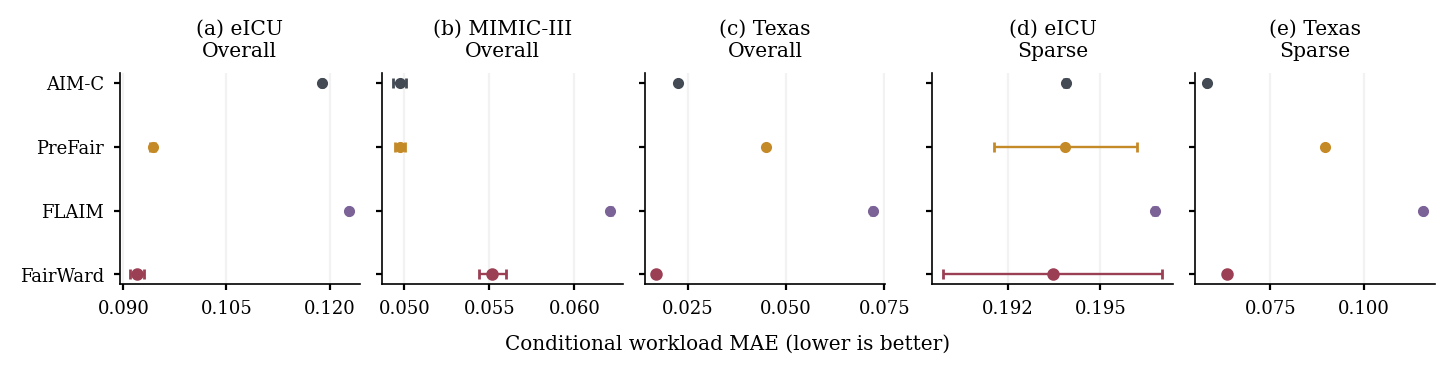

,panel,cohort,scope,method,mean,SD,fits
0,a,eICU,Overall,AIM-C,0.118893,0.000110,3
1,a,eICU,Overall,PreFair,0.094266,0.000369,3
2,a,eICU,Overall,FLAIM,0.122792,0.000044,3
3,a,eICU,Overall,FairWard,0.091990,0.000961,3
4,b,MIMIC-III,Overall,AIM-C,0.049717,0.000388,3
5,b,MIMIC-III,Overall,PreFair,0.049725,0.000306,3
6,b,MIMIC-III,Overall,FLAIM,0.062116,0.000074,3
7,b,MIMIC-III,Overall,FairWard,0.055169,0.000800,3
8,c,Texas,Overall,AIM-C,0.022474,0.000035,3
9,c,Texas,Overall,PreFair,0.044731,0.000002,3


In [14]:
GEN_SECTION = "3. Workload error of the private generators"
gen_fidelity = (load_csv("reconstruction/final_mechanism_fidelity.csv").query("split == 'reused_10pct'")
                .set_index(["dataset", "method"]))
GEN_METHODS = ["AIM-C", "PreFair", "FLAIM", "FairWard"]
GEN_PANELS = [("eicu", "overall"), ("mimic", "overall"), ("texas", "overall"), ("eicu", "sparse"), ("texas", "sparse")]
GEN_METRIC = {"overall": "test_workload_mae_weighted", "sparse": "sparse_mae"}
gen_plotted = pd.DataFrame(
    [{"panel": "abcde"[i], "cohort": DATASETS[key], "scope": scope.capitalize(), "method": m,
      "mean": gen_fidelity.loc[(key, m), f"{GEN_METRIC[scope]}_mean"], "SD": gen_fidelity.loc[(key, m), f"{GEN_METRIC[scope]}_std"],
      "fits": gen_fidelity.loc[(key, m), f"{GEN_METRIC[scope]}_count"]}
     for i, (key, scope) in enumerate(GEN_PANELS) for m in GEN_METHODS])


def gen_draw(plotted):
    """Redraw Fig. 2 with the layout and style of the paper's figure builder."""
    fig, axes = plt.subplots(1, 5, figsize=(7.16, 1.75), layout="constrained")
    for index, (ax, (panel, rows)) in enumerate(zip(axes, plotted.groupby("panel"))):
        for y, r in enumerate(rows.itertuples()):
            ax.errorbar(r.mean, y, xerr=r.SD, fmt="o", ms=3.5 if r.method == "FairWard" else 3,
                        color=COLORS[r.method], capsize=1.8, lw=0.85)
        ax.set_yticks(range(len(GEN_METHODS)), GEN_METHODS if index == 0 else [])
        ax.invert_yaxis()
        ax.set_title(f"({panel}) {rows.cohort.iloc[0]}\n{rows.scope.iloc[0]}", fontsize=7.3)
        ax.xaxis.set_major_locator(MaxNLocator(3))
        ax.xaxis.set_major_formatter(FormatStrFormatter("%.3f"))
        ax.tick_params(axis="both", labelsize=6.5, length=2)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="x", alpha=0.16)
    fig.supxlabel("Conditional workload MAE (lower is better)", fontsize=7.2)
    plt.show()


gen_draw(gen_plotted)
display(gen_plotted)
check(GEN_SECTION, "Fig. 2 caption, fits per plotted point and error bar, four private generators in five panels, "
      'reused 10% ("three")', "3", ", ".join(map(str, sorted(set(gen_plotted.fits)))))

### Values quoted in Section V-A

Section V-A quotes the FairWard mean with one comparator for eICU and Texas, under a common per-fit privacy cap. It also states which generators have lower error in the remaining panels, and it calls the eICU sparse difference between FairWard and PreFair narrow across three fits.

The paper defines neither "narrow" nor "leads", so the notebook reads them as a gap below each method's between-fit SD and as the lowest mean. Section V-A also states that no MIMIC-III cell meets the fixed sparse eligibility rule.

Source: `data/reconstruction/final_mechanism_fidelity.csv`.

In [15]:
gen_fidelity = (load_csv("reconstruction/final_mechanism_fidelity.csv").query("split == 'reused_10pct'")
                .set_index(["dataset", "method"]))
gen_overall = gen_fidelity.test_workload_mae_weighted_mean.unstack()  # rows are cohorts, columns are generators
gen_sparse = gen_fidelity.sparse_mae_mean.unstack()
check(GEN_SECTION, "Section V-A, Fig. 2 (a), eICU overall workload MAE, FairWard, reused 10% (mean of three fits)", "0.09199",
      gen_overall.loc["eicu", "FairWard"])
check(GEN_SECTION, "Section V-A, Fig. 2 (a), eICU overall workload MAE, PreFair, reused 10% (mean of three fits)", "0.09427",
      gen_overall.loc["eicu", "PreFair"])
holds(GEN_SECTION, "Section V-A, Fig. 2 (a), eICU overall workload MAE, reused 10%, FairWard has the lowest mean of the four "
      "private generators",
      gen_overall.loc["eicu"].idxmin() == "FairWard")
check(GEN_SECTION, "Section V-A, Fig. 2 (c), Texas overall workload MAE, FairWard, reused 10% (mean of three fits)", "0.01676",
      gen_overall.loc["texas", "FairWard"])
check(GEN_SECTION, "Section V-A, Fig. 2 (c), Texas overall workload MAE, AIM-C, reused 10% (mean of three fits)", "0.02247",
      gen_overall.loc["texas", "AIM-C"])
holds(GEN_SECTION, "Section V-A, Fig. 2 (c), Texas overall workload MAE, reused 10%, FairWard has the lowest mean of the four "
      "private generators",
      gen_overall.loc["texas"].idxmin() == "FairWard")
holds(GEN_SECTION, "Section V-A, Fig. 2 (b), MIMIC-III overall workload MAE, reused 10%, AIM-C and PreFair means below FairWard",
      (gen_overall.loc["mimic", ["AIM-C", "PreFair"]] < gen_overall.loc["mimic", "FairWard"]).all())

check(GEN_SECTION, "Section V-A, Fig. 2 (d), eICU sparse MAE, FairWard, reused 10% (mean of three fits)", "0.19345",
      gen_sparse.loc["eicu", "FairWard"])
check(GEN_SECTION, "Section V-A, Fig. 2 (d), eICU sparse MAE, PreFair, reused 10% (mean of three fits)", "0.19386",
      gen_sparse.loc["eicu", "PreFair"])
gen_pair = gen_fidelity.loc["eicu"].loc[["FairWard", "PreFair"]]
check(GEN_SECTION, 'Section V-A, Fig. 2 (d), eICU sparse MAE, FairWard and PreFair, fits per mean, reused 10% ("three")', "3",
      ", ".join(map(str, sorted(set(gen_pair.sparse_mae_count)))))
gen_gap = gen_pair.loc["PreFair", "sparse_mae_mean"] - gen_pair.loc["FairWard", "sparse_mae_mean"]
holds(GEN_SECTION, "Section V-A, Fig. 2 (d), eICU sparse MAE, reused 10%, narrow difference between FairWard and PreFair "
      "(notebook criterion: FairWard lower by less than the smaller between-fit SD of the two)",
      0 < gen_gap < gen_pair.sparse_mae_std.min())
holds(GEN_SECTION, "Section V-A, Fig. 2 (e), Texas sparse MAE, reused 10%, AIM-C leads "
      "(notebook criterion: lowest mean of the four private generators)",
      gen_sparse.loc["texas"].idxmin() == "AIM-C")
holds(GEN_SECTION, "Section V-A and Fig. 2 caption, MIMIC-III sparse MAE, reused 10%, no cells meet the fixed sparse eligibility rule "
      "(zero sparse cells and zero sparse fits for all four private generators)",
      gen_fidelity.loc["mimic"].sparse_cells.eq(0).all() and gen_fidelity.loc["mimic"].sparse_mae_count.eq(0).all())

### Privacy target and row-level budget

The Fig. 2 caption states one privacy target for all four generators, and Section V-A calls it a common per-fit privacy cap. The released FairWard privacy accounting file records it per fit, and the AIM-C and PreFair rows of the prediction summary carry it as a text label. The FLAIM run manifests, released for one fit per cohort, record it as a budget cap together with the row-level budget that FLAIM used.

The released files record a row-level budget only for FLAIM, and the table below sets it beside the FairWard accounting. The check tests the $\rho/H^2$ rule of Section IV-B on these manifests, where eICU has $H=2$ and MIMIC-III and Texas have $H=1$. Repeated fits compose their privacy costs, and the research summaries are not one jointly epsilon-private release.

Source: `data/privacy/evidence_privacy_composition.csv`, `data/prediction/baseline_prediction_summary.csv`, `data/cohorts/flaim_run_manifest_eicu.json`, `data/cohorts/flaim_run_manifest_mimic.json`, `data/cohorts/flaim_run_manifest_texas.json`.

In [16]:
gen_budget = load_csv("privacy/evidence_privacy_composition.csv").set_index("dataset")
gen_scope = (load_csv("prediction/baseline_prediction_summary.csv").query("regime == 'TSTR'")
             .groupby("method").privacy_scope.unique())
gen_flaim = pd.DataFrame([load_json(f"cohorts/flaim_run_manifest_{key}.json") for key in DATASETS]).set_index("dataset")
display(pd.DataFrame({"FairWard H": gen_budget.H, "FairWard rho per fit": gen_budget.rho_per_fit,
                      "FLAIM hospital cap": gen_flaim.hospital_cap, "FLAIM rho target": gen_flaim.rho_target,
                      "FLAIM rho used": gen_flaim.rho_used}))
holds(GEN_SECTION, "Fig. 2 caption and Section V-A, common per-fit privacy target epsilon = 3, delta = 10^-6 for FairWard, "
      "AIM-C, PreFair and FLAIM, three cohorts (recorded flags, with the same rho per fit in the FairWard accounting and the FLAIM manifests; "
      "effective row-level noise differs in eICU)",
      gen_budget.epsilon_per_fit.eq(3).all() and gen_budget.delta_per_fit.eq(1e-6).all()
      and all(list(gen_scope[m]) == ["epsilon3 delta1e-6 generator; audit outputs not jointly DP"]
              for m in ["AIM-C_common_fair", "PreFair_common_fair"])
      and gen_flaim.epsilon_cap.eq(3).all() and gen_flaim.delta.eq(1e-6).all() and gen_flaim.budget_cap_passed.all()
      and np.allclose(gen_flaim.rho_target, gen_budget.rho_per_fit, rtol=0, atol=1e-12))
holds(GEN_SECTION, "Section IV-B, FLAIM row-level budget rho/H^2 in the three released manifests (eICU H = 2, MIMIC-III and "
      "Texas H = 1), with H equal to the FairWard accounting",
      np.allclose(gen_flaim.rho_used, gen_flaim.rho_target / gen_flaim.hospital_cap ** 2, rtol=1e-12, atol=0)
      and gen_flaim.hospital_cap.eq(gen_budget.H).all())
show(GEN_SECTION)

,FairWard H,FairWard rho per fit,FLAIM hospital cap,FLAIM rho target,FLAIM rho used
dataset,,,,,
eicu,2,0.147264,2,0.147264,0.036816
mimic,1,0.147264,1,0.147264,0.147264
texas,1,0.147264,1,0.147264,0.147264


,claim,paper,notebook,basis,status
1,"Fig. 2 caption, fits per plotted point and error bar, four private generators in five panels, reused 10% (""three"")",3,3,recomputed,match
2,"Section V-A, Fig. 2 (a), eICU overall workload MAE, FairWard, reused 10% (mean of three fits)",0.09199,0.09199,recomputed,match
3,"Section V-A, Fig. 2 (a), eICU overall workload MAE, PreFair, reused 10% (mean of three fits)",0.09427,0.09427,recomputed,match
4,"Section V-A, Fig. 2 (a), eICU overall workload MAE, reused 10%, FairWard has the lowest mean of the four private generators",stated in the paper,holds,statement,match
5,"Section V-A, Fig. 2 (c), Texas overall workload MAE, FairWard, reused 10% (mean of three fits)",0.01676,0.01676,recomputed,match
6,"Section V-A, Fig. 2 (c), Texas overall workload MAE, AIM-C, reused 10% (mean of three fits)",0.02247,0.02247,recomputed,match
7,"Section V-A, Fig. 2 (c), Texas overall workload MAE, reused 10%, FairWard has the lowest mean of the four private generators",stated in the paper,holds,statement,match
8,"Section V-A, Fig. 2 (b), MIMIC-III overall workload MAE, reused 10%, AIM-C and PreFair means below FairWard",stated in the paper,holds,statement,match
9,"Section V-A, Fig. 2 (d), eICU sparse MAE, FairWard, reused 10% (mean of three fits)",0.19345,0.19345,recomputed,match
10,"Section V-A, Fig. 2 (d), eICU sparse MAE, PreFair, reused 10% (mean of three fits)",0.19386,0.19386,recomputed,match


## 4. Composition calibration

FairWard calibrates group composition using signed global totals from the same private measurements, while preserving the hospital/context distribution and clinical prediction inputs. The composition amendment was frozen before its outcome evaluation and assessed against training composition on all twenty transcripts per cohort.

Table V reports TV from real-training proportions before and after calibration, averaged over twenty shared transcripts. The Table V caption describes these values as fidelity measures, not conditional-parity scores. TV compares fitted proportions with real training proportions, and Section VI notes that privacy accounting excludes such exact audits. The clinical partitions informed earlier development, so these results are exploratory. Section IV-A adds that repeating mechanism draws does not restore independent patients.

Source: `data/composition/composition_training_summary.csv`.

In [17]:
S4 = "4. Composition calibration"
train_comp = load_csv("composition/composition_training_summary.csv").set_index(["setting", "method"])
table5 = pd.DataFrame(
    [[label] + [f"{train_comp.loc[(key, m), col]:.4f}" for col in ("protected_tv_mean", "composition_tv_mean")
                for m in ("original", "repaired")]
     for key, label in DATASETS.items()],
    columns=["Dataset", "A before", "A after", "K,A,C before", "K,A,C after"])
TABLE_V = [  # cells copied from the paper (tables/composition_repair.tex)
    ["eICU", "0.2298", "0.0166", "0.3243", "0.2505"],
    ["MIMIC-III", "0.0413", "0.0071", "0.0543", "0.0357"],
    ["Texas", "0.0758", "0.0023", "0.1106", "0.0889"],
]
compare_table(S4, "Table V, FairWard protected-marginal TV (A) and hospital/group/context TV (K,A,C) before and after calibration, "
                  "eICU, MIMIC-III and Texas", TABLE_V, table5)
check(S4, 'Table V caption, shared transcripts per cohort in the FairWard composition audit (eICU, MIMIC-III and Texas) ("twenty")', "20",
      train_comp.fits.unique().item())
display(table5)

,Dataset,A before,A after,"K,A,C before","K,A,C after"
0,eICU,0.2298,0.0166,0.3243,0.2505
1,MIMIC-III,0.0413,0.0071,0.0543,0.0357
2,Texas,0.0758,0.0023,0.1106,0.0889


### Paired before/after comparison and query cost

Section V-B prints protected-marginal TV to five decimals and states that full hospital/group/context TV improves on every fit. The released paired file counts, for each cohort and metric, the transcripts on which calibration lowers TV. The row built on the paired file also covers the Section III-C statement that the correction reduces one source of composition bias. Section V-B also states that calibration uses existing private measurements, with no additional query cost. The released assessment manifest records this property as a flag, so the last row tests a recorded flag rather than a count of queries.

Source: `data/composition/composition_training_summary.csv`, `data/composition/composition_training_paired.csv`, `data/verification/composition_assessment_manifest.json`.

In [18]:
train_pairs = load_csv("composition/composition_training_paired.csv")
train_pairs = train_pairs[train_pairs.metric.isin(["protected_tv", "composition_tv"])].set_index(["setting", "metric"])
display(train_pairs[["fits", "repaired_minus_original_mean", "difference_sd", "repaired_lower_count"]])

check(S4, 'Section V-B, reused transcripts per cohort in the paired before/after TV comparison (eICU, MIMIC-III and Texas) ("twenty")', "20",
      train_pairs.fits.unique().item())
for s4_cohort, s4_before, s4_after in [("eicu", "0.22984", "0.01663"), ("mimic", "0.04127", "0.00709"),
                                       ("texas", "0.07579", "0.00234")]:
    check(S4, f"Section V-B, {DATASETS[s4_cohort]} FairWard protected-marginal TV before calibration, mean of twenty transcripts",
          s4_before, train_comp.loc[(s4_cohort, "original"), "protected_tv_mean"])
    check(S4, f"Section V-B, {DATASETS[s4_cohort]} FairWard protected-marginal TV after calibration, mean of twenty transcripts",
          s4_after, train_comp.loc[(s4_cohort, "repaired"), "protected_tv_mean"])
holds(S4, "Sections III-C and V-B, calibration lowers FairWard protected-marginal TV and full hospital/group/context TV on all "
          "twenty paired transcripts in eICU, MIMIC-III and Texas (composition improves consistently across all three cohorts; "
          "full hospital/group/context TV also improves on every fit; the correction reduces one source of composition bias)",
      len(train_pairs) == 6 and train_pairs.repaired_lower_count.eq(train_pairs.fits).all())
train_manifest = load_json("verification/composition_assessment_manifest.json")
holds(S4, "Section V-B, FairWard calibration uses existing private measurements with no additional query cost "
          "(recorded flag additional_private_measurements = 0 in the composition assessment manifest)",
      train_manifest["additional_private_measurements"] == 0)

fits  repaired_minus_original_mean  difference_sd  repaired_lower_count
setting metric                                                                                 
eicu    composition_tv    20                     -0.073823       0.003185                    20
        protected_tv      20                     -0.213210       0.008116                    20
mimic   composition_tv    20                     -0.018578       0.002394                    20
        protected_tv      20                     -0.034185       0.004158                    20
texas   composition_tv    20                     -0.021663       0.000440                    20
        protected_tv      20                     -0.073448       0.000795                    20

### Rare-group mass and removed categories

Section V-B states that better composition does not guarantee rare-group representation, using eICU as the example. The released group file gives the mean fitted mass of each protected category over twenty transcripts, before and after calibration. Per-category training shares were removed from the release, because they would disclose training counts below ten.

The eICU training proportion of Other, Unknown and Missing combined is recomputed from two released means. It equals the mean Other/Unknown/Missing mass before calibration minus the mean protected-marginal TV before calibration. The identity requires that, in every pre-calibration fit, each of these three categories holds at least its training share and Female and Male hold at most theirs. Protected-marginal TV then equals the summed excess on Other, Unknown and Missing. Without that condition, the same difference is only a lower bound on the training proportion. The released paired-study file also reports group masses and protected-marginal TV for three original FairWard fits, and the table shows the same difference for them.

Section III-C states that clipping every small group cell before summing can inflate rare-group prevalence, and Section I makes the same point for small categories. For any set of groups, the mean protected-marginal TV is at least the absolute gap between mean fitted mass and training share. A training share is therefore at most its mean mass after calibration plus the mean TV after calibration. The clipping row asks whether the mean mass before calibration exceeds that ceiling for every rare group in every cohort.

The number of eICU fits that remove an observed rare category is read from a released QA record, because the per-fit file is not released. The released summary file gives the mean and SD across twenty fits of the number of removed categories. Female and Male are not removed in any calibrated eICU fit, because a zero mass in one fit would require a larger SD than the released one. Each fit therefore removes zero to three categories, and the table lists the affected-fit counts that the released mean and SD allow. Section V-B retains group absence as a failure of coverage rather than counting it as evidence of fairness.

Source: `data/composition/composition_training_groups.csv`, `data/composition/composition_training_summary.csv`, `data/composition/composition_training_paired.csv`, `data/prediction/composition_eval_composition_summary.csv`, `data/verification/evidence_arithmetic.json`.

In [19]:
train_groups = load_csv("composition/composition_training_groups.csv")
rare_groups = train_groups[train_groups.group.isin(["Other", "Unknown", "Missing"])].pivot(
    index=["setting", "group"], columns="method", values="group_mass_mean")
tv_after_cal = train_comp.xs("repaired", level="method").protected_tv_mean
display(rare_groups.assign(ceiling=rare_groups.repaired.add(tv_after_cal, level="setting")).round(5)
        .set_axis(["mass before calibration", "mass after calibration", "ceiling on training share"], axis=1))
rare_total = rare_groups.groupby(level="setting").sum()
check(S4, "Section V-B, eICU FairWard Other/Unknown/Missing mass before calibration, mean of twenty transcripts", "23.006%",
      100 * rare_total.loc["eicu", "original"])
check(S4, "Section V-B, eICU FairWard Other/Unknown/Missing mass after calibration, mean of twenty transcripts", "1.248%",
      100 * rare_total.loc["eicu", "repaired"])

# Training share = rare mass minus protected-marginal TV before calibration, from the twenty transcripts and,
# as a second derivation, from the original FairWard fits of the paired three-fit study (groups 2 to 4 are the rare ones).
paired_original = (load_csv("prediction/composition_eval_composition_summary.csv")
                   .set_index(["dataset", "method"]).loc[("eicu", "FairWard_new_original")])
share_inputs = pd.DataFrame(
    {"Other/Unknown/Missing mass": [rare_total.loc["eicu", "original"],
                                    paired_original[[f"fitted_group{i}_mass_mean" for i in (2, 3, 4)]].sum()],
     "protected-marginal TV": [train_comp.loc[("eicu", "original"), "protected_tv_mean"], paired_original.fitted_a_tv_mean]},
    index=["twenty transcripts", "paired three-fit study"])
share_inputs["difference"] = share_inputs.iloc[:, 0] - share_inputs.iloc[:, 1]
assert np.isclose(*share_inputs.difference, rtol=0, atol=1e-9)
display(share_inputs.mul(100).round(4).add_suffix(" (%)").rename_axis("eICU, before calibration"))
check(S4, "Section V-B, eICU Other/Unknown/Missing training proportion (FairWard rare mass minus protected-marginal TV "
          "before calibration, twenty transcripts)", "0.0225%", 100 * share_inputs.loc["twenty transcripts", "difference"])

# The mean TV is at least |mean fitted mass - training share| for any set of groups, so each training share is at most
# the mean mass after calibration plus the mean protected-marginal TV after calibration.
holds(S4, "Sections I and III-C, clipping small group cells before summing inflates rare-group prevalence (FairWard mean mass "
          "before calibration above the training-share ceiling for Other, Unknown and Missing in eICU, MIMIC-III and Texas; "
          "notebook criterion: ceiling = mass after calibration + protected-marginal TV after calibration)",
      len(rare_groups) == 9 and rare_groups.original.gt(rare_groups.repaired.add(tv_after_cal, level="setting")).all())

arith_record = load_json("verification/evidence_arithmetic.json")
eicu_cal = train_comp.loc[("eicu", "repaired")]
assert arith_record["eicu_mean_observed_groups_zeroed"] == eicu_cal.observed_groups_zeroed_mean
# A zero mass in one fit would make a group's SD at least its mean / sqrt(fits - 1); Female and Male stay below that bound,
# so each fit removes at most the three rare categories.
fm_cal = train_groups.query("setting == 'eicu' and method == 'repaired' and group in ['Female', 'Male']")
assert (fm_cal.group_mass_sd < fm_cal.group_mass_mean / np.sqrt(fm_cal.fits - 1)).all()
# Fits removing one, two or three categories must reproduce the sum and the sum of squares implied by the mean and SD.
cal_fits = int(eicu_cal.fits)
removed_sum = cal_fits * eicu_cal.observed_groups_zeroed_mean
removed_squares = (cal_fits - 1) * eicu_cal.observed_groups_zeroed_sd ** 2 + cal_fits * eicu_cal.observed_groups_zeroed_mean ** 2
assert np.isclose(removed_sum, round(removed_sum)) and np.isclose(removed_squares, round(removed_squares))
fits_affected = sorted({a + b + c for a in range(cal_fits + 1) for b in range(cal_fits + 1) for c in range(cal_fits + 1)
                        if a + b + c <= cal_fits and a + 2 * b + 3 * c == round(removed_sum)
                        and a + 4 * b + 9 * c == round(removed_squares)})
display(pd.Series({"fits": cal_fits, "removed categories per fit, mean": eicu_cal.observed_groups_zeroed_mean,
                   "removed categories per fit, SD": round(eicu_cal.observed_groups_zeroed_sd, 6),
                   "affected fits allowed by the mean and SD": f"{min(fits_affected)} to {max(fits_affected)}",
                   "affected fits in the QA record": arith_record["eicu_fits_with_observed_groups_zeroed"]})
        .to_frame("eICU after calibration"))
check(S4, 'Section V-B, eICU calibrated FairWard fits that remove an observed rare category (QA arithmetic record) ("eighteen of twenty")', "18 of 20",
      f"{arith_record['eicu_fits_with_observed_groups_zeroed']} of {cal_fits}", record=True)
holds(S4, "Section V-B, eICU calibrated FairWard fits that remove an observed rare category, recorded count within the range "
          "that the released mean and SD of removed categories allow (notebook criterion: zero to three categories per fit)",
      arith_record["eicu_fits_with_observed_groups_zeroed"] in fits_affected)
check(S4, "Section V-B, eICU calibrated FairWard observed rare categories removed per fit, mean of twenty transcripts", "1.6",
      eicu_cal.observed_groups_zeroed_mean)
holds(S4, "Sections III-C and V-B, eICU FairWard improves average composition yet calibrated fits still remove observed rare "
          "categories (both TVs lower on all twenty paired transcripts; better composition does not guarantee rare-group "
          "representation; noisy global totals can still remove a rare group entirely; improved average composition "
          "coexists with incomplete support)",
      train_pairs.loc["eicu"].repaired_lower_count.eq(train_pairs.loc["eicu"].fits).all()
      and eicu_cal.observed_groups_zeroed_mean > 0)
show(S4)

mass before calibration  mass after calibration  ceiling on training share
setting group                                                                              
eicu    Missing                  0.07732                 0.00469                    0.02132
        Other                    0.07636                 0.00399                    0.02062
        Unknown                  0.07638                 0.00381                    0.02044
mimic   Missing                  0.01393                 0.00248                    0.00957
        Other                    0.01382                 0.00154                    0.00863
        Unknown                  0.01352                 0.00126                    0.00834
texas   Missing                  0.02500                 0.00019                    0.00253
        Other                    0.02534                 0.00071                    0.00305
        Unknown                  0.02545                 0.00060                    0.00295

,Other/Unknown/Missing mass (%),protected-marginal TV (%),difference (%)
"eICU, before calibration",,,
twenty transcripts,23.0065,22.9840,0.0225
paired three-fit study,23.1128,23.0904,0.0225


,eICU after calibration
fits,20
"removed categories per fit, mean",1.6
"removed categories per fit, SD",0.820783
affected fits allowed by the mean and SD,16 to 20
affected fits in the QA record,18


,claim,paper,notebook,basis,status
1,"Table V, FairWard protected-marginal TV (A) and hospital/group/context TV (K,A,C) before and after calibration, eICU, MIMIC-III and Texas, every printed cell","15 cells, 12 numbers",15 cells identical,table,match
2,"Table V caption, shared transcripts per cohort in the FairWard composition audit (eICU, MIMIC-III and Texas) (""twenty"")",20,20,recomputed,match
3,"Section V-B, reused transcripts per cohort in the paired before/after TV comparison (eICU, MIMIC-III and Texas) (""twenty"")",20,20,recomputed,match
4,"Section V-B, eICU FairWard protected-marginal TV before calibration, mean of twenty transcripts",0.22984,0.22984,recomputed,match
5,"Section V-B, eICU FairWard protected-marginal TV after calibration, mean of twenty transcripts",0.01663,0.01663,recomputed,match
6,"Section V-B, MIMIC-III FairWard protected-marginal TV before calibration, mean of twenty transcripts",0.04127,0.04127,recomputed,match
7,"Section V-B, MIMIC-III FairWard protected-marginal TV after calibration, mean of twenty transcripts",0.00709,0.00709,recomputed,match
8,"Section V-B, Texas FairWard protected-marginal TV before calibration, mean of twenty transcripts",0.07579,0.07579,recomputed,match
9,"Section V-B, Texas FairWard protected-marginal TV after calibration, mean of twenty transcripts",0.00234,0.00234,recomputed,match
10,"Sections III-C and V-B, calibration lowers FairWard protected-marginal TV and full hospital/group/context TV on all twenty paired transcripts in eICU, MIMIC-III and Texas (composition improves consistently across all three cohorts; full hospital/group/context TV also improves on every fit; the correction reduces one source of composition bias)",stated in the paper,holds,statement,match


## 5. Finite-output conditional TV on common contexts

Finite-output fairness uses a fixed comparison population, as defined in Section IV-C. For each protected pair, a context is eligible only when both groups occur in real training data and in every included method and fit. Conditional TV is averaged over these same contexts with weights proportional to real-training hospital/context counts.

The primary audit requires at least one record per group, while a separate sensitivity analysis requires fifty, and both thresholds were fixed before the audit. The primary audit intersects thirty outputs per cohort, namely the original twenty-four outputs plus three paired original/amended samples. The earlier twenty-four-output audit is retained separately because its coverage differs, and the notebook compares the two coverage files. Pairwise coverage and all-five-group support accompany each gap, and unsupported categories are never assigned a zero gap.

Source: `data/prediction/composition_eval_common_support_coverage.csv`, `data/prediction/common_support_coverage.csv`, `data/prediction/composition_eval_common_support_summary.csv`.

In [20]:
S5 = "5. Finite-output conditional TV on common contexts"
cov30 = load_csv("prediction/composition_eval_common_support_coverage.csv")
cov24 = load_csv("prediction/common_support_coverage.csv")
cs_summary = load_csv("prediction/composition_eval_common_support_summary.csv")
display(cov30[cov30.threshold.eq(1) & cov30.contrast.isin(["Female/Male", "all_five_maximum"])])

# Fits per synthetic arm and cohort. The two FairWard arms hold the paired original/amended samples; every other
# synthetic arm belongs to the original twenty-four outputs.
FW_ORIGINAL, FW_AMENDED = "FairWard_new_original", "FairWard_composition_repair"
fits_per_arm = (cs_summary[cs_summary.contrast.eq("Female/Male") & cs_summary.threshold.eq(1)
                           & cs_summary.method.ne("real_train_reference")]
                .pivot(index="method", columns="dataset", values="finite_tv_count"))
earlier_outputs = fits_per_arm.drop([FW_ORIGINAL, FW_AMENDED]).sum()
paired_fits = fits_per_arm.loc[[FW_ORIGINAL, FW_AMENDED]].min()
outputs30 = earlier_outputs + 2 * paired_fits
assert outputs30.eq(cov30.groupby("dataset").synthetic_tables.max()).all()
assert earlier_outputs.eq(cov24.groupby("dataset").all_tables.max()).all()
check(S5, 'Section IV-C, outputs intersected per cohort in the primary finite-output audit (eICU, MIMIC-III and Texas) ("thirty")',
      "30", outputs30.unique().item())
check(S5, "Section IV-C, original outputs per cohort in the primary finite-output audit (eight earlier synthetic arms, "
          'three fits each) ("twenty-four")', "24", earlier_outputs.unique().item())
check(S5, 'Section IV-C, paired original/amended FairWard samples per cohort in the primary finite-output audit ("three")', "3",
      paired_fits.unique().item())

both_cov = cov24.merge(cov30, on=["dataset", "contrast", "threshold"], suffixes=(" (24 outputs)", " (30 outputs)"))
fm_cov = both_cov[both_cov.contrast.eq("Female/Male")]
display(fm_cov[["dataset", "threshold", "training_mass_coverage (24 outputs)", "training_mass_coverage (30 outputs)"]])
s5_differs = ~np.isclose(fm_cov["training_mass_coverage (24 outputs)"], fm_cov["training_mass_coverage (30 outputs)"])
s5_cells = fm_cov.dataset.map(DATASETS) + " at support floor " + fm_cov.threshold.astype(str)
holds(S5, "Section IV-C, the earlier twenty-four-output audit has different Female/Male training-mass coverage from the "
          "thirty-output audit (notebook criterion: coverage differs in at least one cohort and support floor)",
      len(fm_cov) == 6 and s5_differs.any(),
      note=f"differs in {', '.join(s5_cells[s5_differs])}; equal in {', '.join(s5_cells[~s5_differs]) or 'none'}")

GROUP_NAMES = ["Female", "Male", "Other", "Unknown", "Missing"]
expected_contrasts = {f"{a}/{b}" for i, a in enumerate(GROUP_NAMES) for b in GROUP_NAMES[i + 1:]} | {"all_five_maximum"}
holds(S5, "Section IV-C, pairwise coverage and all-five-group support accompany each gap (ten protected pairs and the all-five "
          "maximum for every cohort and threshold in the thirty-output audit; contexts and training-mass coverage on every "
          "summary row)",
      all(set(c) == expected_contrasts for _, c in cov30.groupby(["dataset", "threshold"]).contrast)
      and cs_summary[["common_contexts", "training_mass_coverage"]].notna().all().all())
unsupported = cs_summary.common_contexts.eq(0)
holds(S5, "Section IV-C, unsupported categories are never assigned a zero gap (finite-output and fitted-law conditional TV "
          "missing exactly where a pair has no common context, thirty-output summary)",
      cs_summary.loc[unsupported, ["finite_tv_mean", "fitted_law_tv_mean"]].isna().all().all()
      and cs_summary.loc[~unsupported, "finite_tv_mean"].notna().all())

,dataset,contrast,threshold,common_contexts,training_mass_coverage,synthetic_tables
0,eicu,Female/Male,1,301,0.888997,30
10,eicu,all_five_maximum,1,0,0.000000,30
22,mimic,Female/Male,1,40,1.000000,30
32,mimic,all_five_maximum,1,0,0.000000,30
44,texas,Female/Male,1,998,0.881594,30
54,texas,all_five_maximum,1,0,0.000000,30


,dataset,threshold,training_mass_coverage (24 outputs),training_mass_coverage (30 outputs)
0,eicu,1,0.915567,0.888997
11,eicu,50,0.463835,0.455724
22,mimic,1,1.000000,1.000000
33,mimic,50,1.000000,1.000000
44,texas,1,0.890875,0.881594
55,texas,50,0.084700,0.084700


### Original and amended FairWard samples

The audit requires at least one record per group and compares the same Female/Male contexts using the same training weights. In the paired three-fit amendment study, the original and amended FairWard samples are scored on these contexts together with the common-policy baselines. The table gives mean finite-output conditional TV and its sample SD across three fits on fixed records, which is not a confidence interval. The clinical partitions informed earlier development, so these results are exploratory. Section IV-A adds that repeating mechanism draws does not restore independent patients.

Source: `data/prediction/composition_eval_common_support_summary.csv`, `data/prediction/composition_eval_common_support_coverage.csv`.

In [21]:
fm_tv = cs_summary[cs_summary.contrast.eq("Female/Male") & cs_summary.threshold.eq(1)].set_index(["dataset", "method"])
CS_LABELS = {"AIM-C_common_fair": "AIM-C", "PreFair_common_fair": "PreFair", "FLAIM_common_fair": "FLAIM",
             FW_ORIGINAL: "FairWard original", FW_AMENDED: "FairWard amended"}
display(fm_tv[["finite_tv_mean", "finite_tv_std"]].unstack("dataset").loc[list(CS_LABELS)]
        .rename(index=CS_LABELS, columns={**DATASETS, "finite_tv_mean": "mean", "finite_tv_std": "SD"}).round(5))

check(S5, "Section V-B, fits per FairWard arm in the paired three-fit amendment study (original and amended samples; "
          'eICU, MIMIC-III and Texas) ("three-fit")', "3", np.unique(fits_per_arm.loc[[FW_ORIGINAL, FW_AMENDED]]).item())
for s5_cohort, s5_before, s5_after in [("eicu", "0.20255", "0.18980"), ("mimic", "0.07277", "0.07186"),
                                       ("texas", "0.12814", "0.12645")]:
    check(S5, f"Section V-B, {DATASETS[s5_cohort]} finite-output Female/Male conditional TV of the original FairWard samples "
              "(threshold 1, mean of three fits)", s5_before, fm_tv.loc[(s5_cohort, FW_ORIGINAL), "finite_tv_mean"])
    check(S5, f"Section V-B, {DATASETS[s5_cohort]} finite-output Female/Male conditional TV of the amended FairWard samples "
              "(threshold 1, mean of three fits)", s5_after, fm_tv.loc[(s5_cohort, FW_AMENDED), "finite_tv_mean"])
holds(S5, "Section V-B, finite-output Female/Male conditional TV falls after the amendment in eICU, MIMIC-III and Texas "
          "(FairWard means of three fits, threshold 1)",
      all(fm_tv.loc[(k, FW_AMENDED), "finite_tv_mean"] < fm_tv.loc[(k, FW_ORIGINAL), "finite_tv_mean"] for k in DATASETS))
coverage_fm = cov30[cov30.contrast.eq("Female/Male") & cov30.threshold.eq(1)].set_index("dataset").training_mass_coverage
for s5_cohort, s5_printed in zip(DATASETS, ["88.90%", "100%", "88.16%"]):
    check(S5, f"Section V-B, {DATASETS[s5_cohort]} training mass covered by the common Female/Male contexts (threshold 1, "
              "thirty outputs)", s5_printed, 100 * coverage_fm[s5_cohort])

mean                          SD                   
dataset               eICU MIMIC-III    Texas     eICU MIMIC-III    Texas
method                                                                   
AIM-C              0.25664   0.10190  0.17295  0.00272   0.00871  0.00422
PreFair            0.14445   0.06858  0.14969  0.00208   0.00284  0.00206
FLAIM              0.22137   0.07029  0.21479  0.00194   0.00160  0.00187
FairWard original  0.20255   0.07277  0.12814  0.00118   0.00043  0.00218
FairWard amended   0.18980   0.07186  0.12645  0.00200   0.00146  0.00308

### Common-policy baselines and fitted-law parity

Section V-B compares the FairWard samples with the three common-policy baselines on the same contexts. It states that FairWard remains worse than PreFair and FLAIM in the named cohorts, so those rows test both the original and the amended samples. The released summary file reports fitted-law conditional TV next to the sampled value, so fitted-law parity and sampled parity are checked separately. It defines fitted-law TV only for Female/Male, the one pair with common contexts, and the parity row tests those rows at both thresholds. Section V-B adds that sampled-TV differences concern finite outputs on supported pairs, not stronger population parity or an all-group guarantee.

The released summary gives the SD across fits for each arm but not the SD of paired differences. The table of compared differences lists each difference that Section V-B compares, next to the larger across-fit SD of the two arms. The fall after the amendment in MIMIC-III and Texas and the gap between the amended FairWard samples and FLAIM in MIMIC-III are smaller than that SD.

Source: `data/prediction/composition_eval_common_support_summary.csv`, `data/prediction/composition_eval_common_support_coverage.csv`.

In [22]:
fm_mean = fm_tv.finite_tv_mean
FAIRWARD_SAMPLES = [FW_ORIGINAL, FW_AMENDED]
BASELINES = ["AIM-C_common_fair", "PreFair_common_fair", "FLAIM_common_fair"]
holds(S5, "Section V-B, FairWard remains worse than PreFair in eICU and MIMIC-III (original and amended samples have higher "
          "finite-output Female/Male conditional TV, threshold 1)",
      all(fm_mean[(k, fw)] > fm_mean[(k, "PreFair_common_fair")] for k in ("eicu", "mimic") for fw in FAIRWARD_SAMPLES))
holds(S5, "Section V-B, FairWard remains worse than FLAIM in MIMIC-III (original and amended samples have higher "
          "finite-output Female/Male conditional TV, threshold 1)",
      all(fm_mean[("mimic", fw)] > fm_mean[("mimic", "FLAIM_common_fair")] for fw in FAIRWARD_SAMPLES))
holds(S5, "Section V-B, amended FairWard improves on AIM-C, PreFair and FLAIM in Texas (lower finite-output Female/Male "
          "conditional TV, threshold 1)",
      all(fm_mean[("texas", FW_AMENDED)] < fm_mean[("texas", m)] for m in BASELINES))
all_five_rows = cov30[cov30.contrast.eq("all_five_maximum")]
holds(S5, "Section V-B, no context has support for all five groups across every included output (thirty outputs, "
          "thresholds 1 and 50; eICU, MIMIC-III and Texas)",
      len(all_five_rows) == 6 and all_five_rows.common_contexts.eq(0).all())
# Fitted-law TV exists only where a pair has common contexts (Female/Male): five arms x three cohorts x two thresholds.
law_rows = cs_summary[cs_summary.method.isin(BASELINES + FAIRWARD_SAMPLES) & cs_summary.fitted_law_tv_mean.notna()]
holds(S5, "Section V-B, all common-policy fitted laws enforce the same conditional parity (AIM-C, PreFair, FLAIM and both "
          "FairWard samples, Female/Male fitted-law conditional TV on the common contexts at thresholds 1 and 50, all "
          "cohorts; notebook criterion: below 10^-12, which absorbs floating-point error)",
      len(law_rows) == 30 and law_rows.contrast.eq("Female/Male").all() and law_rows.fitted_law_tv_mean.max() < 1e-12)

# Each comparison is (label, cohort, arm with the higher mean, arm with the lower mean), as stated in Section V-B.
compared = ([("FairWard original minus amended", k, FW_ORIGINAL, FW_AMENDED) for k in DATASETS]
            + [(f"{CS_LABELS[fw]} minus PreFair", k, fw, "PreFair_common_fair") for k in ("eicu", "mimic") for fw in FAIRWARD_SAMPLES]
            + [(f"{CS_LABELS[fw]} minus FLAIM", "mimic", fw, "FLAIM_common_fair") for fw in FAIRWARD_SAMPLES]
            + [(f"{CS_LABELS[m]} minus FairWard amended", "texas", m, FW_AMENDED) for m in BASELINES])
compared_gaps = pd.DataFrame([{"comparison": label, "cohort": DATASETS[k], "difference": fm_mean[(k, hi)] - fm_mean[(k, lo)],
                               "larger across-fit SD": fm_tv.loc[[(k, hi), (k, lo)], "finite_tv_std"].max()}
                              for label, k, hi, lo in compared])
compared_gaps["difference below that SD"] = compared_gaps.difference < compared_gaps["larger across-fit SD"]
display(compared_gaps.round(5))
show(S5)

,comparison,cohort,difference,larger across-fit SD,difference below that SD
0,FairWard original minus amended,eICU,0.01275,0.00200,False
1,FairWard original minus amended,MIMIC-III,0.00091,0.00146,True
2,FairWard original minus amended,Texas,0.00168,0.00308,True
3,FairWard original minus PreFair,eICU,0.05810,0.00208,False
4,FairWard amended minus PreFair,eICU,0.04535,0.00208,False
5,FairWard original minus PreFair,MIMIC-III,0.00419,0.00284,False
6,FairWard amended minus PreFair,MIMIC-III,0.00329,0.00284,False
7,FairWard original minus FLAIM,MIMIC-III,0.00248,0.00160,False
8,FairWard amended minus FLAIM,MIMIC-III,0.00158,0.00160,True
9,AIM-C minus FairWard amended,Texas,0.04650,0.00422,False


,claim,paper,notebook,basis,status,note
1,"Section IV-C, outputs intersected per cohort in the primary finite-output audit (eICU, MIMIC-III and Texas) (""thirty"")",30,30,recomputed,match,
2,"Section IV-C, original outputs per cohort in the primary finite-output audit (eight earlier synthetic arms, three fits each) (""twenty-four"")",24,24,recomputed,match,
3,"Section IV-C, paired original/amended FairWard samples per cohort in the primary finite-output audit (""three"")",3,3,recomputed,match,
4,"Section IV-C, the earlier twenty-four-output audit has different Female/Male training-mass coverage from the thirty-output audit (notebook criterion: coverage differs in at least one cohort and support floor)",stated in the paper,holds,statement,match,"differs in eICU at support floor 1, eICU at support floor 50, Texas at support floor 1; equal in MIMIC-III at support floor 1, MIMIC-III at support floor 50, Texas at support floor 50"
5,"Section IV-C, pairwise coverage and all-five-group support accompany each gap (ten protected pairs and the all-five maximum for every cohort and threshold in the thirty-output audit; contexts and training-mass coverage on every summary row)",stated in the paper,holds,statement,match,
6,"Section IV-C, unsupported categories are never assigned a zero gap (finite-output and fitted-law conditional TV missing exactly where a pair has no common context, thirty-output summary)",stated in the paper,holds,statement,match,
7,"Section V-B, fits per FairWard arm in the paired three-fit amendment study (original and amended samples; eICU, MIMIC-III and Texas) (""three-fit"")",3,3,recomputed,match,
8,"Section V-B, eICU finite-output Female/Male conditional TV of the original FairWard samples (threshold 1, mean of three fits)",0.20255,0.20255,recomputed,match,
9,"Section V-B, eICU finite-output Female/Male conditional TV of the amended FairWard samples (threshold 1, mean of three fits)",0.18980,0.18980,recomputed,match,
10,"Section V-B, MIMIC-III finite-output Female/Male conditional TV of the original FairWard samples (threshold 1, mean of three fits)",0.07277,0.07277,recomputed,match,


## 6. Prediction on real records

Table VI reports primary logistic prediction on the reused 10% real records at threshold 0.5, the primary decision threshold. Synthetic arms report means across three fits, and the AUROC entry adds the sample SD across fits rather than a confidence interval. The released baseline summary holds one real-only fit, so the real-only row of Table VI has no SD and the redrawn Fig. 3 gives it no error bar. The clinical partitions informed earlier development, so these results are exploratory.

FairWard is the final composition-calibrated four-query generator, while the other fits are preserved baselines. Real-only and the empirical fair oracle are non-private references, and FLAIM assumes public sizes. Common TV is the Female/Male training-data conditional TV on the same contexts and training weights. It requires at least one record per group in real training data and every output. EO is the real-test equalized-odds gap and must be read alongside F1.

The FairWard rows come from the released composition evaluation summary at threshold 0.5. The released baseline summary has no threshold column, and the paper's asset builder reads its rows as the threshold-0.5 scores. For MIMIC-III, the matched-study summary reports real-only, AIM-C, PreFair and FLAIM at thresholds 0.1 and 0.5. The notebook compares accuracy, F1, balanced accuracy and selection rate in the baseline rows with both. The eICU and Texas baseline rows have no second released source, so their threshold is inherited from the paper's asset builder.

Source: `data/prediction/baseline_prediction_summary.csv`, `data/prediction/composition_eval_prediction_summary.csv`, `data/prediction/composition_eval_common_support_summary.csv`, `data/prediction/fairsynth_summary.csv`.

In [23]:
S6 = "6. Prediction on real records"
FW6 = "FairWard_composition_repair"
LABEL6 = {m: label for m, label, _ in ARMS}

baseline6 = load_csv("prediction/baseline_prediction_summary.csv")
# The baseline summary has no threshold column; the paper's builder reads these rows as the threshold-0.5 scores.
baseline6 = baseline6[baseline6.split.eq("reused_10pct") & baseline6.classifier.eq("logistic")
                      & baseline6.regime.isin(["TSTR", "TRTR"]) & baseline6.method.isin(list(LABEL6)[:-1])]
paired_pred6 = load_csv("prediction/composition_eval_prediction_summary.csv")
fairward6 = paired_pred6[paired_pred6.method.eq(FW6) & paired_pred6.classifier.eq("logistic")
                         & paired_pred6.split.eq("reused_10pct") & paired_pred6.threshold.eq(0.5)]
pred6 = pd.concat([baseline6, fairward6]).set_index(["dataset", "method"]).loc[[(d, m) for d in DATASETS for m in LABEL6]]
assert len(pred6) == 18 and pred6.index.is_unique

# Female/Male contrast at the one-record support floor; the Real row is scored on the real training data.
support6 = load_csv("prediction/composition_eval_common_support_summary.csv")
common_tv6 = (support6[support6.contrast.eq("Female/Male") & support6.threshold.eq(1)]
              .replace({"method": {"real_train_reference": "raw_TRTR"}}).set_index(["dataset", "method"]).loc[pred6.index])

table6 = pd.DataFrame({
    "Dataset": [DATASETS[d] if m == "raw_TRTR" else "" for d, m in pred6.index],
    "Training data": [LABEL6[m] for _, m in pred6.index],
    "AUROC": pred6.auroc_mean.map("{:.4f}".format) + pred6.auroc_std.map(lambda s: "" if pd.isna(s) else f" ± {s:.4f}"),
    "AP": pred6.auprc_ap_mean.map("{:.4f}".format),
    "Accuracy": pred6.accuracy_mean.map("{:.4f}".format),
    "F1": pred6.f1_mean.map("{:.4f}".format),
    "EO gap": pred6.female_male_equalized_odds_gap_mean.map("{:.4f}".format),
    "Common TV": common_tv6.finite_tv_mean.map("{:.4f}".format),
}).reset_index(drop=True)

TABLE_VI = [  # cells copied from the paper (tables/main_outcome.tex)
    ["eICU", "Real", "0.7126", "0.2344", "0.9058", "0.0000", "0.0000", "0.2149"],
    ["", "Fair oracle", "0.7118 ± 0.0007", "0.2350", "0.9060", "0.0139", "0.0008", "0.1456"],
    ["", "AIM-C", "0.7123 ± 0.0009", "0.2345", "0.9060", "0.0139", "0.0008", "0.2566"],
    ["", "PreFair", "0.6901 ± 0.0013", "0.2315", "0.9058", "0.0000", "0.0000", "0.1444"],
    ["", "FLAIM", "0.6976 ± 0.0036", "0.2308", "0.9058", "0.0000", "0.0000", "0.2214"],
    ["", "FairWard", "0.6942 ± 0.0010", "0.2238", "0.9058", "0.0434", "0.0068", "0.1898"],
    ["MIMIC-III", "Real", "0.7222", "0.2701", "0.8864", "0.0561", "0.0404", "0.1850"],
    ["", "Fair oracle", "0.7225 ± 0.0004", "0.2702", "0.8864", "0.0561", "0.0404", "0.0662"],
    ["", "AIM-C", "0.7206 ± 0.0009", "0.2701", "0.8862", "0.0187", "0.0135", "0.1019"],
    ["", "PreFair", "0.7224 ± 0.0012", "0.2699", "0.8862", "0.0187", "0.0135", "0.0686"],
    ["", "FLAIM", "0.6879 ± 0.0124", "0.2536", "0.8861", "0.0000", "0.0000", "0.0703"],
    ["", "FairWard", "0.7113 ± 0.0011", "0.2607", "0.8864", "0.0561", "0.0404", "0.0719"],
    ["Texas", "Real", "0.7050", "0.6287", "0.6487", "0.4928", "0.0753", "0.1462"],
    ["", "Fair oracle", "0.7047 ± 0.0003", "0.6286", "0.6502", "0.5020", "0.0809", "0.1135"],
    ["", "AIM-C", "0.7048 ± 0.0002", "0.6287", "0.6486", "0.4925", "0.0751", "0.1730"],
    ["", "PreFair", "0.7044 ± 0.0008", "0.6279", "0.6485", "0.4920", "0.0748", "0.1497"],
    ["", "FLAIM", "0.6871 ± 0.0020", "0.6133", "0.6449", "0.6111", "0.1932", "0.2148"],
    ["", "FairWard", "0.7025 ± 0.0001", "0.6255", "0.6484", "0.4904", "0.0724", "0.1265"],
]
compare_table(S6, "Table VI (logistic, reused 10%, threshold 0.5)", TABLE_VI, table6)
display(table6)

# MIMIC-III threshold check: the matched-study summary scores the same baseline rows at 0.1 and at 0.5.
study6 = load_csv("prediction/fairsynth_summary.csv")
study6 = study6[study6.classifier.eq("logistic") & study6.split.eq("reused_10pct") & study6.arm.ne("Real+Synthetic")]
STUDY6 = {"raw_TRTR": "Real-only", "AIM-C_common_fair": "AIM-C", "PreFair_common_fair": "PreFair", "FLAIM_common_fair": "FLAIM"}
THRESHOLD_METRICS6 = ["accuracy", "f1", "balanced_accuracy", "selection_rate"]
mimic6 = pred6.loc["mimic"].loc[list(STUDY6)].rename(index=STUDY6)
threshold_gap6 = pd.DataFrame(
    {f"threshold {t}": [(mimic6[c + "_mean"] - rows.set_index("method")[c + "_mean"]).abs().max() for c in THRESHOLD_METRICS6]
     for t, rows in study6.groupby("threshold")},
    index=THRESHOLD_METRICS6).rename_axis("largest absolute difference, MIMIC-III baseline rows")
display(threshold_gap6)
holds(S6, "Table VI caption, threshold 0.5 (notebook criterion: accuracy, F1, balanced accuracy and selection rate of the "
      "MIMIC-III logistic rows of real-only, AIM-C, PreFair and FLAIM equal the matched-study summary at 0.5 and differ "
      "from it at 0.1)",
      threshold_gap6["threshold 0.5"].max() < 1e-12 and threshold_gap6["threshold 0.1"].min() > 1e-6)

,Dataset,Training data,AUROC,AP,Accuracy,F1,EO gap,Common TV
0,eICU,Real,0.7126,0.2344,0.9058,0.0000,0.0000,0.2149
1,,Fair oracle,0.7118 ± 0.0007,0.2350,0.9060,0.0139,0.0008,0.1456
2,,AIM-C,0.7123 ± 0.0009,0.2345,0.9060,0.0139,0.0008,0.2566
3,,PreFair,0.6901 ± 0.0013,0.2315,0.9058,0.0000,0.0000,0.1444
4,,FLAIM,0.6976 ± 0.0036,0.2308,0.9058,0.0000,0.0000,0.2214
5,,FairWard,0.6942 ± 0.0010,0.2238,0.9058,0.0434,0.0068,0.1898
6,MIMIC-III,Real,0.7222,0.2701,0.8864,0.0561,0.0404,0.1850
7,,Fair oracle,0.7225 ± 0.0004,0.2702,0.8864,0.0561,0.0404,0.0662
8,,AIM-C,0.7206 ± 0.0009,0.2701,0.8862,0.0187,0.0135,0.1019
9,,PreFair,0.7224 ± 0.0012,0.2699,0.8862,0.0187,0.0135,0.0686


,threshold 0.1,threshold 0.5
"largest absolute difference, MIMIC-III baseline rows",,
accuracy,0.268735,0.0
f1,0.282259,0.0
balanced_accuracy,0.147229,0.0
selection_rate,0.421274,0.0


### Counts and privacy target in the Table VI caption

The Table VI caption states three fits per synthetic arm, 100,000 rows per fit and thirty outputs per cohort behind Common TV. The fit counts come from the run counts of the baseline summary, the fit counts of Common TV and the paired sample sets in the FairWard validation record. The rows per fit come from the per-fit finite-sample fairness file for the baselines and from the same validation record for FairWard. These counts and the privacy target below are copied fields, so the check table marks them as records.

The Table VI caption also states that private fits target $\epsilon=3$, $\delta=10^{-6}$, and Section IV-B adds that every private clinical fit uses the same contribution caps. The AIM-C and PreFair rows of the released summary record this target as text. The FairWard accounting file records it per fit, and the FLAIM run manifests record it as a budget cap. Row-based AIM-C, PreFair and FLAIM use $\rho/H^2$, whereas FairWard uses the tighter hospital-resolved sensitivity where applicable. A common upper privacy cap does not isolate reconstruction from measurement strategy or public information.

Repeated fits compose their privacy costs, and the research summaries are not one jointly epsilon-private release. Research metrics computed from real evaluation records also lie outside the single-generator guarantee. Section VI adds that accounting excludes development selection and exact audits, and that the rounded mechanism's fidelity certificate remains unestablished.

Source: `data/prediction/baseline_prediction_summary.csv`, `data/prediction/composition_eval_common_support_summary.csv`, `data/verification/composition_eval_validation.json`, `data/prediction/finite_sample_fairness_per_fit.csv`, `data/privacy/evidence_privacy_composition.csv`, `data/cohorts/flaim_run_manifest_eicu.json`, `data/cohorts/flaim_run_manifest_mimic.json`, `data/cohorts/flaim_run_manifest_texas.json`.

In [24]:
def only6(values):
    """The single value in a collection, or the sorted values as text so that the check reports a mismatch."""
    values = set(values)
    return values.pop() if len(values) == 1 else ", ".join(map(str, sorted(values)))


validation6 = load_json("verification/composition_eval_validation.json")
synthetic6 = pred6.index[pred6.index.get_level_values("method") != "raw_TRTR"]
assert pred6.loc[pred6.index.difference(synthetic6), "runs"].eq(1).all()  # real-only is a single fit
# Fits behind the prediction means: baseline run counts, and FairWard's paired sample sets over the three cohorts.
prediction_fits6 = set(pred6.loc[synthetic6, "runs"].dropna()) | {validation6["paired_sample_sets"] / len(DATASETS)}
check(S6, "Table VI caption, fits per synthetic arm and cohort (baseline run counts, Common TV fit counts, "
      'FairWard paired sample sets over three cohorts) ("three")', "3",
      only6(prediction_fits6 | set(common_tv6.loc[synthetic6, "finite_tv_count"])), record=True)

per_fit6 = load_csv("prediction/finite_sample_fairness_per_fit.csv")
per_fit6 = per_fit6[per_fit6.stage.eq("primary") & per_fit6.method.isin(synthetic6.get_level_values("method"))]
assert len(per_fit6) == 36  # four baseline arms, three cohorts, three fits
check(S6, "Table VI caption, synthetic rows per fit (baseline table_rows in the per-fit finite-sample fairness file, "
      "FairWard validation record)", "100,000",
      only6(set(per_fit6.table_rows) | {validation6["synthetic_rows_per_arm"]}), record=True)
check(S6, 'Table VI caption, outputs per cohort behind Common TV (synthetic_tables, Female/Male, one-record floor) ("thirty")', "30",
      only6(common_tv6.synthetic_tables), record=True)

# AIM-C and PreFair store the target as text such as "epsilon3 delta1e-6 generator; ...".
scope6 = pred6.loc[pred6.index.isin(["AIM-C_common_fair", "PreFair_common_fair"], level="method"), "privacy_scope"]
targets6 = {tuple(float(x) for x in re.match(r"epsilon(\S+) delta(\S+) ", s).groups()) for s in scope6}
budget6 = load_csv("privacy/evidence_privacy_composition.csv")
targets6 |= set(zip(budget6.epsilon_per_fit, budget6.delta_per_fit))
targets6 |= {(run["epsilon_cap"], run["delta"]) for run in (load_json(f"cohorts/flaim_run_manifest_{d}.json") for d in DATASETS)}
check(S6, "Table VI caption, per-fit privacy target epsilon = 3, delta = 10^-6, epsilon value (AIM-C and PreFair scope "
      "text, FairWard per-fit accounting file, FLAIM run manifests)", "3", only6(eps for eps, _ in targets6), record=True)
check(S6, "Table VI caption, per-fit privacy target epsilon = 3, delta = 10^-6, delta value (AIM-C and PreFair scope "
      "text, FairWard per-fit accounting file, FLAIM run manifests)", "10^-6", only6(f"10^{np.log10(dlt):.0f}" for _, dlt in targets6), record=True)

### Calibration at unchanged discrimination

Section V-B states that calibration improves representation at unchanged discrimination, and that the paired experiment changes protected labels while keeping the clinical rows used by the classifiers fixed. The notebook tests the representation part on protected-marginal TV and hospital/group/context (K,A,C) TV, in the fitted laws and in the samples. These TV values come from the paired three-fit study, not from the twenty transcripts of Table V.

Unchanged discrimination holds by design rather than by measurement, so the notebook does not compare the prediction metrics of the two arms. The validation record of the paired run states that the clinical samples and classifier inputs were verified identical, and that both arms share their prediction vectors by design. The prediction summary therefore repeats the same rows for the two arms, and comparing those rows cannot test the claim. The check table marks the two design statements as recorded flags, which rest on the validation record and its independent verification.

The share of changed protected labels comes from the paired samples, so the statement that protected labels change is tested on released data.

Source: `data/prediction/composition_eval_composition_summary.csv`, `data/verification/composition_eval_validation.json`, `data/verification/composition_eval_independent_verification.json`, `data/prediction/composition_eval_prediction_summary.csv`.

In [25]:
comp6 = load_csv("prediction/composition_eval_composition_summary.csv").set_index(["method", "dataset"])
before6, after6 = comp6.loc["FairWard_new_original"], comp6.loc[FW6]
TV6 = {"fitted_a_tv_mean": "fitted protected TV", "sample_a_tv_mean": "sampled protected TV",
       "fitted_kac_tv_mean": "fitted K,A,C TV", "sample_kac_tv_mean": "sampled K,A,C TV"}
display(pd.DataFrame({f"{name}, {when}": frame[col] for col, name in TV6.items()
                      for when, frame in (("before", before6), ("after", after6))}
                     | {"changed protected labels": after6.changed_group_label_fraction_mean})
        .rename(index=DATASETS).round(5))

holds(S6, "Section V-B, calibration improves representation (FairWard paired three-fit study, eICU, MIMIC-III and Texas; "
      "protected-marginal and hospital/group/context TV lower after calibration in fitted laws and samples)",
      (after6[list(TV6)] < before6[list(TV6)]).all().all())
holds(S6, "Section V-B, calibration leaves discrimination unchanged (FairWard paired run; recorded flags: clinical samples "
      "and classifier inputs verified identical, prediction vectors shared by design)",
      validation6["clinical_sample_and_input_identity_verified"]
      and validation6["prediction_vectors_shared_by_design_after_input_identity_check"])
holds(S6, "Section V-B, the paired experiment changes protected labels (FairWard paired three-fit study, eICU, MIMIC-III "
      "and Texas; mean share of changed protected labels above 0)", after6.changed_group_label_fraction_mean.gt(0).all())
independent6 = load_json("verification/composition_eval_independent_verification.json")
holds(S6, "Section V-B, the paired experiment keeps the clinical rows used by the classifiers fixed (FairWard paired run; "
      "recorded flag: independent verification passed one clinical-sample identity check per paired sample set)",
      independent6["status"] == "passed"
      and independent6["paired_clinical_sample_identity_checks"] == validation6["paired_sample_sets"])

by_arm6 = paired_pred6.set_index(["method", "dataset", "classifier", "split", "threshold"]).sort_index()
assert by_arm6.loc["FairWard_new_original"].equals(by_arm6.loc[FW6])  # one shared classifier fit, identical by design

,"fitted protected TV, before","fitted protected TV, after","sampled protected TV, before","sampled protected TV, after","fitted K,A,C TV, before","fitted K,A,C TV, after","sampled K,A,C TV, before","sampled K,A,C TV, after",changed protected labels
dataset,,,,,,,,,
eICU,0.23090,0.02253,0.23031,0.02116,0.32348,0.25079,0.32487,0.25339,0.26823
MIMIC-III,0.04164,0.00549,0.04162,0.00622,0.05508,0.03607,0.05671,0.03886,0.05049
Texas,0.07580,0.00241,0.07612,0.00263,0.11071,0.08911,0.13453,0.11754,0.10617


### FairWard against the leading private result

Among complete generators, Section V-B compares FairWard's logistic AUROC with the leading private result in each cohort. The notebook takes the leading result as the highest mean AUROC among AIM-C, PreFair and FLAIM. These are means of three fits, and Table VI gives their SDs rather than confidence intervals.

Section V-B adds that the difference is smallest for Texas length of stay, where FairWard also has the lowest sampled conditional TV among the private generators. The notebook reads that TV from the Common TV column of Table VI.

Source: `data/prediction/baseline_prediction_summary.csv`, `data/prediction/composition_eval_prediction_summary.csv`, `data/prediction/composition_eval_common_support_summary.csv`.

In [26]:
PRIVATE6 = ["AIM-C_common_fair", "PreFair_common_fair", "FLAIM_common_fair"]
fw_auc6 = pred6.xs(FW6, level="method").auroc_mean
lead_auc6 = pred6.loc[pred6.index.isin(PRIVATE6, level="method"), "auroc_mean"].groupby(level="dataset").max()
for d6, fw_printed6, lead_printed6 in [("eicu", "0.69423", "0.71235"), ("mimic", "0.71132", "0.72243"),
                                       ("texas", "0.70250", "0.70484")]:
    check(S6, f"Section V-B, FairWard logistic AUROC, {DATASETS[d6]}, reused 10%", fw_printed6, fw_auc6[d6])
    check(S6, f"Section V-B, leading private logistic AUROC, {DATASETS[d6]}, reused 10% "
          "(notebook criterion: highest mean among AIM-C, PreFair and FLAIM)", lead_printed6, lead_auc6[d6])
holds(S6, "Section V-B, FairWard logistic AUROC below the leading private result in eICU, MIMIC-III and Texas, reused 10% "
      "(notebook criterion: highest mean among AIM-C, PreFair and FLAIM)", (fw_auc6 < lead_auc6).all())
holds(S6, "Section V-B, leading-private-minus-FairWard logistic AUROC difference smallest for Texas length of stay, "
      "reused 10% (notebook criterion: highest mean among AIM-C, PreFair and FLAIM)",
      (lead_auc6 - fw_auc6).idxmin() == "texas")
holds(S6, "Section V-B, Texas, FairWard has the lowest sampled conditional TV among the private generators (Table VI "
      "Common TV of AIM-C, PreFair, FLAIM and FairWard)", common_tv6.loc["texas"].finite_tv_mean[PRIVATE6 + [FW6]].idxmin() == FW6)

### Fig. 3

Fig. 3 shows the primary train-on-synthetic/test-on-real comparison, with columns for eICU, MIMIC-III and Texas and rows for AUROC and average precision (AP). For synthetic arms, points show means and error bars one sample SD across three generator/sample fits on fixed records, not independent clinical cohorts. Real-only and the empirical fair oracle are non-private references, and the redrawn figure gives real-only no error bar because the released summary holds one real-only fit.

Fig. 3 prints no numbers, and Section V-B cites it together with Table VI for the AUROC values. The notebook redraws the figure from the Table VI rows, reads each plotted mean and error bar back from the panels and compares them with Table VI. Table VI prints no AP SD, so the AP error bars have no printed counterpart.

Source: `data/prediction/baseline_prediction_summary.csv`, `data/prediction/composition_eval_prediction_summary.csv`, `data/verification/composition_eval_validation.json`.

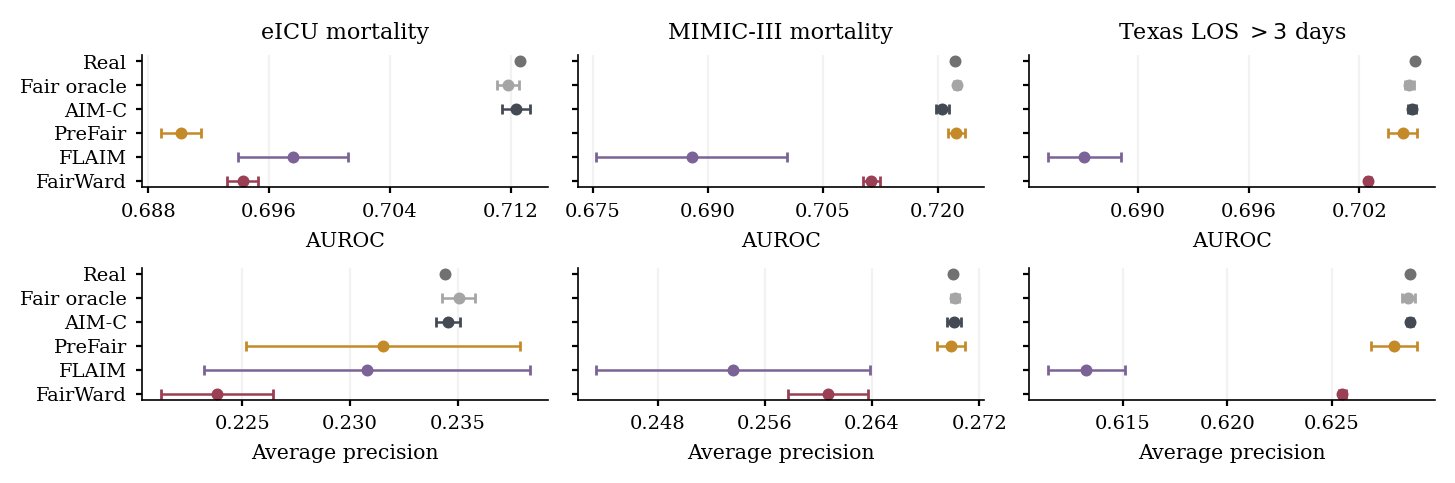

metric                     AUROC                 AP          
                            mean error bar     mean error bar
Dataset   Training data                                      
eICU      Real           0.71261       NaN  0.23440       NaN
          Fair oracle    0.71182   0.00074  0.23502   0.00075
          AIM-C          0.71235   0.00091  0.23453   0.00054
          PreFair        0.69014   0.00133  0.23154   0.00635
          FLAIM          0.69759   0.00365  0.23078   0.00754
          FairWard       0.69423   0.00102  0.22382   0.00261
MIMIC-III Real           0.72220       NaN  0.27006       NaN
          Fair oracle    0.72250   0.00038  0.27019   0.00032
          AIM-C          0.72056   0.00086  0.27009   0.00052
          PreFair        0.72243   0.00116  0.26991   0.00106
          FLAIM          0.68789   0.01242  0.25362   0.01021
          FairWard       0.71132   0.00114  0.26068   0.00298
Texas     Real           0.70502       NaN  0.62871       NaN
          Fair oracle    0.70471   0.00025  0.62865   0.00033
          AIM-C          0.70484   0.00023  0.62870   0.00014
          PreFair        0.70435   0.00077  0.62795   0.00110
          FLAIM          0.68710   0.00198  0.61326   0.00184
          FairWard       0.70250   0.00012  0.62549   0.00016

In [27]:
def draw_fig3():
    """Redraw Fig. 3 from the Table VI rows; the single-fit real-only reference has no error bar."""
    fig, axes = plt.subplots(2, 3, figsize=(7.16, 2.3), layout="constrained")
    for col, (d, dlabel) in enumerate(DATASETS.items()):
        for row, (metric, xlabel) in enumerate([("auroc", "AUROC"), ("auprc_ap", "Average precision")]):
            ax = axes[row, col]
            for y, (m, label, color) in enumerate(ARMS):
                r = pred6.loc[(d, m)]
                sd = r[metric + "_std"]
                ax.errorbar(r[metric + "_mean"], y, xerr=None if pd.isna(sd) else sd, fmt="o", ms=3.3, color=color,
                            capsize=1.8, lw=0.9)
            ax.set_yticks(range(len(ARMS)), list(LABEL6.values()) if col == 0 else [])
            ax.invert_yaxis()
            ax.set_xlabel(xlabel, fontsize=7.4)
            ax.tick_params(labelsize=7, length=2)
            if row == 0:
                ax.set_title(dlabel + (" mortality" if d != "texas" else r" LOS $>3$ days"), fontsize=8)
            ax.xaxis.set_major_locator(MaxNLocator(4))
            ax.xaxis.set_major_formatter(FormatStrFormatter("%.3f"))
            ax.spines[["right", "top"]].set_visible(False)
            ax.grid(axis="x", alpha=0.16)
    return axes


def read_fig3(axes):
    """Read every point back from the panels: column titles give the cohort, x labels the metric, first-column ticks the arm."""
    points = []
    for row in range(2):
        arms = [t.get_text() for t in axes[row, 0].get_yticklabels()]
        for col in range(3):
            for container in axes[row, col].containers:
                line, _, bars = container.lines
                points.append({"Dataset": axes[0, col].get_title().split()[0], "Training data": arms[round(line.get_ydata()[0])],
                               "metric": {"AUROC": "AUROC", "Average precision": "AP"}[axes[row, col].get_xlabel()],
                               "mean": line.get_xdata()[0],
                               "error bar": np.ptp(bars[0].get_segments()[0][:, 0]) / 2 if bars else np.nan})
    return pd.DataFrame(points).set_index(["Dataset", "Training data", "metric"]).sort_index()


fig3_points6 = read_fig3(draw_fig3())
plt.show()

printed6 = (pd.DataFrame(TABLE_VI, columns=table6.columns).replace({"Dataset": {"": np.nan}}).ffill()
            .set_index(["Dataset", "Training data"]))
display(fig3_points6.unstack("metric").swaplevel(axis=1)[["AUROC", "AP"]].reindex(printed6.index).round(5))
auroc_cells6 = printed6.AUROC.str.split(" ± ", expand=True)  # column 0 the mean, column 1 the SD (absent for Real)
printed_means6 = pd.concat({"AUROC": auroc_cells6[0], "AP": printed6.AP}, names=["metric"]).reorder_levels([1, 2, 0]).sort_index()
plotted_bars6 = fig3_points6.xs("AUROC", level="metric")["error bar"].map(lambda v: None if np.isnan(v) else f"{v:.4f}")
# Internal consistency of the redraw, not a test of the paper: the plotted means and AUROC error bars must
# round to the printed Table VI cells (real-only has no error bar).
assert (len(fig3_points6) == 36 and fig3_points6["mean"].map("{:.4f}".format).equals(printed_means6)
        and plotted_bars6.equals(auroc_cells6[1].sort_index())
        and fig3_points6.xs("Real", level="Training data")["error bar"].isna().all()), "Fig. 3 redraw differs from Table VI"
check(S6, "Fig. 3 caption, fits per synthetic-arm point and error bar (baseline run counts, FairWard paired sample "
      'sets over three cohorts) ("three")', "3", only6(prediction_fits6), record=True)

### Detection and accuracy in eICU at threshold 0.5

Section V-B states that the distinction between positive-case detection and overall accuracy also matters in eICU. At threshold 0.5, FairWard reaches 0.90576 accuracy with F1 of 0.04343, and PreFair and FLAIM predict no deaths. The check that PreFair and FLAIM predict no deaths reads the selection rate, which is zero only when a classifier predicts no positive case.

The eICU baseline rows have no second released source, so their threshold of 0.5 is inherited from the paper's asset builder. The released baseline summary also reports a selection rate of zero for real-only training in eICU. A classifier that predicts no deaths scores the share of surviving test patients as its accuracy, and that share equals FairWard's released mean accuracy to five decimals.

Source: `data/prediction/baseline_prediction_summary.csv`, `data/prediction/composition_eval_prediction_summary.csv`.

In [28]:
eicu6 = pred6.loc["eicu"].rename(index=LABEL6)[["accuracy_mean", "f1_mean", "selection_rate_mean"]]
display(eicu6.round(5))
check(S6, "Section V-B, FairWard logistic accuracy, eICU, threshold 0.5", "0.90576", eicu6.loc["FairWard", "accuracy_mean"])
check(S6, "Section V-B, FairWard logistic F1, eICU, threshold 0.5", "0.04343", eicu6.loc["FairWard", "f1_mean"])
holds(S6, "Section V-B, PreFair and FLAIM predict no deaths in eICU at threshold 0.5 (logistic selection rate exactly 0 in every fit)",
      eicu6.loc[["PreFair", "FLAIM"], "selection_rate_mean"].eq(0).all())
# Released context stated above: real-only also predicts no deaths, and its accuracy equals FairWard's mean to five decimals.
assert eicu6.loc["Real", "selection_rate_mean"] == 0
assert round(eicu6.loc["Real", "accuracy_mean"], 5) == round(eicu6.loc["FairWard", "accuracy_mean"], 5)
show(S6)

,accuracy_mean,f1_mean,selection_rate_mean
method,,,
Real,0.90576,0.00000,0.00000
Fair oracle,0.90603,0.01395,0.00107
AIM-C,0.90603,0.01395,0.00107
PreFair,0.90576,0.00000,0.00000
FLAIM,0.90576,0.00000,0.00000
FairWard,0.90576,0.04343,0.00441


,claim,paper,notebook,basis,status
1,"Table VI (logistic, reused 10%, threshold 0.5), every printed cell","144 cells, 123 numbers",144 cells identical,table,match
2,"Table VI caption, threshold 0.5 (notebook criterion: accuracy, F1, balanced accuracy and selection rate of the MIMIC-III logistic rows of real-only, AIM-C, PreFair and FLAIM equal the matched-study summary at 0.5 and differ from it at 0.1)",stated in the paper,holds,statement,match
3,"Table VI caption, fits per synthetic arm and cohort (baseline run counts, Common TV fit counts, FairWard paired sample sets over three cohorts) (""three"")",3,3,record,match
4,"Table VI caption, synthetic rows per fit (baseline table_rows in the per-fit finite-sample fairness file, FairWard validation record)","100,000","100,000",record,match
5,"Table VI caption, outputs per cohort behind Common TV (synthetic_tables, Female/Male, one-record floor) (""thirty"")",30,30,record,match
6,"Table VI caption, per-fit privacy target epsilon = 3, delta = 10^-6, epsilon value (AIM-C and PreFair scope text, FairWard per-fit accounting file, FLAIM run manifests)",3,3,record,match
7,"Table VI caption, per-fit privacy target epsilon = 3, delta = 10^-6, delta value (AIM-C and PreFair scope text, FairWard per-fit accounting file, FLAIM run manifests)",10^-6,10^-6,record,match
8,"Section V-B, calibration improves representation (FairWard paired three-fit study, eICU, MIMIC-III and Texas; protected-marginal and hospital/group/context TV lower after calibration in fitted laws and samples)",stated in the paper,holds,statement,match
9,"Section V-B, calibration leaves discrimination unchanged (FairWard paired run; recorded flags: clinical samples and classifier inputs verified identical, prediction vectors shared by design)",stated in the paper,holds,statement,match
10,"Section V-B, the paired experiment changes protected labels (FairWard paired three-fit study, eICU, MIMIC-III and Texas; mean share of changed protected labels above 0)",stated in the paper,holds,statement,match


## 7. Matched MIMIC-III comparison with the static FairSynth adaptation

Table VII compares logistic mortality prediction on the reused 10% MIMIC-III records at threshold 0.1. Section IV-B makes 0.5 the primary decision threshold and mortality at 0.1 a declared secondary comparison. FairSynth here is a non-private, centralized static adaptation evaluated on the matched MIMIC mortality task. The reported three-epoch run uses the released loss, whose group penalty is detached in the inspected code, and omits longitudinal feedback retraining. The comparison characterizes the adaptation and does not rank FairWard against a faithful reproduction of the published longitudinal system.

Private fits target $\epsilon=3$, $\delta=10^{-6}$ under the same contribution caps, and FLAIM assumes public sizes. Row-based AIM-C, PreFair and FLAIM use $\rho/H^2$, whereas FairWard uses the tighter hospital-resolved sensitivity where applicable. Real-only and the empirical fair oracle are non-private references, and Bal. denotes balanced accuracy. WTPR is the supported Female/Male worst-group sensitivity, and Table VII prints no SD. The clinical partitions informed earlier development, so these results are exploratory.

The paper's asset builder wrote `final_matched_fairsynth.csv`, whose `source` column records where each row came from. According to that column, five rows were scored from unchanged cached primary predictions, and the FairWard row from new rounded transcripts with paired clinical samples. The static FairSynth row was copied from the matched-study summary, and none of the cached predictions are released.

The notebook rebuilds every Table VII cell that an independent released summary also holds. Five rows come from the matched-study summary at threshold 0.1, and the FairWard row except WTPR comes from the composition evaluation summary. The baseline summary scores its threshold metrics at 0.5, so it supplies only the threshold-free AUROC of the empirical fair oracle.

Five cells appear only in the asset builder's file, namely the empirical fair oracle accuracy, balanced accuracy, WTPR and EO gap and the FairWard WTPR. The check table marks these five cells as records rather than recomputed values, because no second released source holds them. The cross-check reports, for every row, the largest absolute difference between the asset builder's file and the independent summary.

Source: `data/prediction/final_matched_fairsynth.csv`, `data/prediction/fairsynth_summary.csv`, `data/prediction/composition_eval_prediction_summary.csv`, `data/prediction/baseline_prediction_summary.csv`.

In [29]:
S7 = "7. Matched MIMIC-III comparison with the static FairSynth adaptation"
FS7 = "FairSynth (static, 3 epochs)"
METRICS7 = {"auroc": "AUROC", "accuracy": "Acc.", "balanced_accuracy": "Bal.", "worst_group_tpr": "WTPR",
            "equalized_odds_gap": "EO"}
TABLE_VII = [  # cells copied from the paper (tables/matched_fairsynth.tex); the paper sets the FairSynth label on two lines
    ["Real", "0.7222", "0.6391", "0.6543", "0.5860", "0.1523"],
    ["Fair oracle", "0.7225", "0.6391", "0.6543", "0.5860", "0.1523"],
    ["AIM-C", "0.7206", "0.6199", "0.6504", "0.5945", "0.1656"],
    ["PreFair", "0.7224", "0.6247", "0.6516", "0.5945", "0.1594"],
    ["FLAIM", "0.6879", "0.6173", "0.6361", "0.5605", "0.1731"],
    [FS7, "0.6957", "0.8861", "0.5000", "0.0000", "0.0000"],
    ["FairWard", "0.7113", "0.5931", "0.6451", "0.6157", "0.1678"],
]
printed7 = pd.DataFrame(TABLE_VII, columns=["Training data", *METRICS7.values()]).set_index("Training data")

builder7 = load_csv("prediction/final_matched_fairsynth.csv").set_index("label")
display(builder7[["method", "source"]])

study7 = load_csv("prediction/fairsynth_summary.csv").query(
    "classifier == 'logistic' and split == 'reused_10pct' and threshold == 0.1")
study_rows7 = study7[study7.arm.ne("Real+Synthetic")].set_index("method")
eval_row7 = load_csv("prediction/composition_eval_prediction_summary.csv").query(
    "dataset == 'mimic' and method == 'FairWard_composition_repair' and classifier == 'logistic' "
    "and split == 'reused_10pct' and threshold == 0.1")
oracle_row7 = load_csv("prediction/baseline_prediction_summary.csv").query(
    "dataset == 'mimic' and method == 'Empirical_fair_oracle' and classifier == 'logistic' "
    "and split == 'reused_10pct' and regime == 'TSTR'")
assert study_rows7.index.is_unique and len(eval_row7) == len(oracle_row7) == 1
eval_row7, oracle_row7 = eval_row7.iloc[0], oracle_row7.iloc[0]

STUDY7 = {"Real": "Real-only", "AIM-C": "AIM-C", "PreFair": "PreFair", "FLAIM": "FLAIM", FS7: "FairSynth-longer"}
SOURCE7 = {**dict.fromkeys(STUDY7, "matched-study summary"), "FairWard": "composition evaluation summary",
           "Fair oracle": "baseline summary"}
independent7 = pd.DataFrame({
    **{row: {m: study_rows7.loc[name, m + "_mean"] for m in METRICS7} for row, name in STUDY7.items()},
    "FairWard": {"auroc": eval_row7.auroc_mean, "accuracy": eval_row7.accuracy_mean,
                 "balanced_accuracy": eval_row7.balanced_accuracy_mean,
                 "equalized_odds_gap": eval_row7.female_male_equalized_odds_gap_mean},
    # The baseline summary scores threshold metrics at 0.5, so only the threshold-free AUROC is comparable.
    "Fair oracle": {"auroc": oracle_row7.auroc_mean},
}).T.reindex(index=builder7.index, columns=list(METRICS7))

cross7 = pd.DataFrame({
    "second source": pd.Series(SOURCE7),
    "cells with a second source": independent7.notna().sum(axis=1),
    "largest absolute difference from the builder's file": (builder7[list(METRICS7)] - independent7).abs().max(axis=1),
}).loc[builder7.index]
display(cross7)
assert cross7["largest absolute difference from the builder's file"].lt(1e-12).all()

builder_only7 = independent7.isna()
values7 = independent7.fillna(builder7[list(METRICS7)])
shown7 = values7.map("{:.4f}".format)
display(shown7.mask(builder_only7, shown7 + " (builder's file only)").rename(columns=METRICS7))

compare_table(S7, "Table VII, rows of real-only, AIM-C, PreFair, FLAIM and the static FairSynth adaptation "
              "(logistic, MIMIC-III, threshold 0.1, matched-study summary)",
              printed7.loc[list(STUDY7)].reset_index().values.tolist(),
              shown7.loc[list(STUDY7)].rename(columns=METRICS7).rename_axis("Training data").reset_index())
NAMES7 = {"auroc": "AUROC", "accuracy": "accuracy", "balanced_accuracy": "balanced accuracy", "worst_group_tpr": "WTPR",
          "equalized_odds_gap": "EO gap"}


def check_cells7(row, who):
    """Check one Table VII row cell by cell; a cell without a second released source is a builder record."""
    for metric, column in METRICS7.items():
        builder_only = bool(builder_only7.loc[row, metric])
        at = "" if metric == "auroc" else ", threshold 0.1"
        source = "asset builder's file only" if builder_only else SOURCE7[row]
        check(S7, f"Table VII, {who} logistic {NAMES7[metric]}, MIMIC-III{at} ({source})",
              printed7.loc[row, column], values7.loc[row, metric], record=builder_only)


check_cells7("Fair oracle", "empirical fair oracle")
check_cells7("FairWard", "FairWard")

,method,source
label,,
Real,raw_TRTR,unchanged cached primary predictions
Fair oracle,Empirical_fair_oracle,unchanged cached primary predictions
AIM-C,AIM-C_common_fair,unchanged cached primary predictions
PreFair,PreFair_common_fair,unchanged cached primary predictions
FLAIM,FLAIM_common_fair,unchanged cached primary predictions
"FairSynth (static, 3 epochs)",FairSynth-longer,"matched_fairsynth/summary.csv: FairSynth-longer, Synthetic-only, logistic, reused10, threshold0.1"
FairWard,FairWard_composition_repair,"new rounded transcripts0,1,2, paired clinical samples"


,second source,cells with a second source,largest absolute difference from the builder's file
label,,,
Real,matched-study summary,5,0.000000e+00
Fair oracle,baseline summary,1,0.000000e+00
AIM-C,matched-study summary,5,1.110223e-16
PreFair,matched-study summary,5,1.110223e-16
FLAIM,matched-study summary,5,1.110223e-16
"FairSynth (static, 3 epochs)",matched-study summary,5,0.000000e+00
FairWard,composition evaluation summary,4,0.000000e+00


,AUROC,Acc.,Bal.,WTPR,EO
label,,,,,
Real,0.7222,0.6391,0.6543,0.5860,0.1523
Fair oracle,0.7225,0.6391 (builder's file only),0.6543 (builder's file only),0.5860 (builder's file only),0.1523 (builder's file only)
AIM-C,0.7206,0.6199,0.6504,0.5945,0.1656
PreFair,0.7224,0.6247,0.6516,0.5945,0.1594
FLAIM,0.6879,0.6173,0.6361,0.5605,0.1731
"FairSynth (static, 3 epochs)",0.6957,0.8861,0.5000,0.0000,0.0000
FairWard,0.7113,0.5931,0.6451,0.6157 (builder's file only),0.1678


### Statements in Section V-B

At the common 0.1 mortality threshold, Section V-B states that FairWard has the highest worst-group sensitivity in the matched MIMIC comparison. The notebook tests that statement over the seven Table VII rows, where the WTPR of FairWard and of the empirical fair oracle comes from the asset builder's file. Section V-B also states that the static FairSynth adaptation detects no deaths at this threshold despite reporting 0.8861 accuracy. The notebook reads the adaptation's selection rate in the matched-study summary, which is zero only when no case is predicted positive.

Section V-B states that PreFair leads in AUROC with 0.7224 and has a smaller EO gap than FairWard. The empirical fair oracle, a non-private reference, prints 0.7225 in Table VII, so the notebook tests the lead among the five generators. The other text values come from the same independent summaries as the Table VII cells.

Source: `data/prediction/final_matched_fairsynth.csv`, `data/prediction/fairsynth_summary.csv`, `data/prediction/composition_eval_prediction_summary.csv`.

In [30]:
fw7, pf7, static7 = values7.loc["FairWard"], values7.loc["PreFair"], values7.loc[FS7]
check(S7, "Section V-B, FairWard logistic WTPR, matched MIMIC-III comparison, threshold 0.1 (asset builder's file only)",
      "0.6157", fw7.worst_group_tpr, record=bool(builder_only7.loc["FairWard", "worst_group_tpr"]))
holds(S7, "Section V-B, FairWard has the highest worst-group sensitivity in the matched MIMIC-III comparison (logistic, "
      "threshold 0.1, WTPR of the seven Table VII rows; FairWard and empirical fair oracle WTPR from the asset builder's file)",
      values7.worst_group_tpr.drop("FairWard").lt(fw7.worst_group_tpr).all())
holds(S7, "Section V-B, the static FairSynth adaptation detects no deaths in the matched MIMIC-III comparison (logistic, "
      "threshold 0.1, selection rate exactly 0)", study_rows7.loc["FairSynth-longer", "selection_rate_mean"] == 0)
check(S7, "Section V-B, static FairSynth adaptation logistic accuracy, matched MIMIC-III comparison, threshold 0.1",
      "0.8861", static7.accuracy)
check(S7, "Section V-B, FairWard logistic AUROC, matched MIMIC-III comparison", "0.7113", fw7.auroc)
check(S7, "Section V-B, static FairSynth adaptation logistic AUROC, matched MIMIC-III comparison", "0.6957", static7.auroc)
holds(S7, "Section V-B, FairWard improves on the static FairSynth adaptation in logistic AUROC, matched MIMIC-III comparison",
      fw7.auroc > static7.auroc)
check(S7, "Section V-B, PreFair logistic AUROC, matched MIMIC-III comparison", "0.7224", pf7.auroc)
holds(S7, "Section V-B, PreFair leads in logistic AUROC, matched MIMIC-III comparison (notebook criterion: highest among "
      "AIM-C, PreFair, FLAIM, the static FairSynth adaptation and FairWard)",
      values7.loc[["AIM-C", "FLAIM", FS7, "FairWard"], "auroc"].lt(pf7.auroc).all(),
      note=f"The non-private empirical fair oracle prints {printed7.loc['Fair oracle', 'AUROC']} in Table VII.")
check(S7, "Section V-B, PreFair logistic EO gap, matched MIMIC-III comparison, threshold 0.1", "0.1594",
      pf7.equalized_odds_gap)
check(S7, "Section V-B, FairWard logistic EO gap, matched MIMIC-III comparison, threshold 0.1", "0.1678",
      fw7.equalized_odds_gap)
holds(S7, "Section V-B, PreFair has a smaller EO gap than FairWard, matched MIMIC-III comparison (logistic, threshold 0.1)",
      pf7.equalized_odds_gap < fw7.equalized_odds_gap)

### Released context for the worst-group sensitivity statement

The released matched-study summary also holds arms that Table VII leaves out, among them augmentation arms that train on real and synthetic records together. The arms whose WTPR at threshold 0.1 exceeds FairWard's are listed below, with their balanced accuracy and share of test patients predicted positive.

The released summaries also report the share of test patients predicted positive at threshold 0.1, for every Table VII row except the empirical fair oracle. FairWard has the largest share among those six rows, and its balanced accuracy in Table VII is below that of real-only, the empirical fair oracle, AIM-C and PreFair.

Source: `data/prediction/fairsynth_summary.csv`, `data/prediction/composition_eval_prediction_summary.csv`, `data/prediction/final_matched_fairsynth.csv`.

In [31]:
outside7 = study7[~study7.method.isin(list(STUDY7.values())) | study7.arm.eq("Real+Synthetic")]
display(outside7.loc[outside7.worst_group_tpr_mean > fw7.worst_group_tpr,
                     ["method", "arm", "worst_group_tpr_mean", "balanced_accuracy_mean", "selection_rate_mean"]]
        .set_index(["method", "arm"]).round(4))

shares7 = pd.Series({row: study_rows7.loc[name, "selection_rate_mean"] for row, name in STUDY7.items()}
                    | {"FairWard": eval_row7.selection_rate_mean})
display(pd.DataFrame({"share predicted positive": shares7, "Bal.": values7.balanced_accuracy,
                      "WTPR": values7.worst_group_tpr}).reindex(builder7.index).round(4))
# Released context stated above.
assert shares7.idxmax() == "FairWard"
assert values7.loc[["Real", "Fair oracle", "AIM-C", "PreFair"], "balanced_accuracy"].gt(fw7.balanced_accuracy).all()
show(S7)

,,worst_group_tpr_mean,balanced_accuracy_mean,selection_rate_mean
method,arm,,,
OppoGAN-local-inspired,Real+Synthetic,0.6752,0.65,0.4863


,share predicted positive,Bal.,WTPR
label,,,
Real,0.4005,0.6543,0.5860
Fair oracle,NaN,0.6543,0.5860
AIM-C,0.4234,0.6504,0.5945
PreFair,0.4178,0.6516,0.5945
FLAIM,0.4192,0.6361,0.5605
"FairSynth (static, 3 epochs)",0.0000,0.5000,0.0000
FairWard,0.4554,0.6451,0.6157


,claim,paper,notebook,basis,status,note
1,"Table VII, rows of real-only, AIM-C, PreFair, FLAIM and the static FairSynth adaptation (logistic, MIMIC-III, threshold 0.1, matched-study summary), every printed cell","30 cells, 25 numbers",30 cells identical,table,match,
2,"Table VII, empirical fair oracle logistic AUROC, MIMIC-III (baseline summary)",0.7225,0.7225,recomputed,match,
3,"Table VII, empirical fair oracle logistic accuracy, MIMIC-III, threshold 0.1 (asset builder's file only)",0.6391,0.6391,record,match,
4,"Table VII, empirical fair oracle logistic balanced accuracy, MIMIC-III, threshold 0.1 (asset builder's file only)",0.6543,0.6543,record,match,
5,"Table VII, empirical fair oracle logistic WTPR, MIMIC-III, threshold 0.1 (asset builder's file only)",0.5860,0.5860,record,match,
6,"Table VII, empirical fair oracle logistic EO gap, MIMIC-III, threshold 0.1 (asset builder's file only)",0.1523,0.1523,record,match,
7,"Table VII, FairWard logistic AUROC, MIMIC-III (composition evaluation summary)",0.7113,0.7113,recomputed,match,
8,"Table VII, FairWard logistic accuracy, MIMIC-III, threshold 0.1 (composition evaluation summary)",0.5931,0.5931,recomputed,match,
9,"Table VII, FairWard logistic balanced accuracy, MIMIC-III, threshold 0.1 (composition evaluation summary)",0.6451,0.6451,recomputed,match,
10,"Table VII, FairWard logistic WTPR, MIMIC-III, threshold 0.1 (asset builder's file only)",0.6157,0.6157,record,match,


## 8. Frozen SUPPORT2 replication

Section IV-B describes the frozen SUPPORT2 replication, whose protocol was fixed before data acquisition. Section 1 of this notebook checks its training and test partition sizes.

Section VI states that the replication tests Algorithm 1 on historical third-study-day records, whose measurement availability was not verified. SUPPORT2 lacks hospital identifiers, so the training and test patients are divided across five simulated clients. Section VI also states that baseline workloads and public-information assumptions restrict the comparisons to the implementations tested.

### Held-out reconstruction

Section V-B compares workload MAE and sparse MAE on the frozen SUPPORT2 test set. Workload MAE weights each simulated client, group and context cell by its evaluation count, and Section 2 of this notebook defines sparse MAE. The Table VIII rows Local-only, Global-only and Pooled-blend are matched controls, and Section V-D states that matched controls add no query cost. The values printed for matched pooled borrowing are those of the Pooled-blend row.

The released workload file holds three fits for each private method and control and one for the non-private Real-only reference, and the table below shows their means. Section V-B compares these means without reporting an interval for their differences.

Section V-B states that the companion reports the full reconstruction comparison on 2,684 test patients, including 695 hospital deaths. The notebook reads the test count from the workload file and the death count from the logistic prediction summary. The released confirmation report states both counts, and the code uses it only as a cross-check.

Source: `data/support2/heldout_workload_metrics.csv`, `data/support2/prediction_summary.csv`, `data/support2/RESULTS.md`.

In [32]:
S8 = "8. Frozen SUPPORT2 replication"
SUP_ORDER = ["Real-only", "AIM-C", "PreFair", "FLAIM", "FairWard", "Local-only", "Global-only", "Pooled-blend"]
sup_work = load_csv("support2/heldout_workload_metrics.csv").query("group == 'Overall'")
sup_seeds = sup_work.groupby("method").seed.nunique()
assert sup_seeds.drop(index="Real-only").eq(3).all() and sup_seeds["Real-only"] == 1 and sup_work.sparse_cells.nunique() == 1
sup_mae = sup_work.groupby("method")[["test_workload_mae_weighted", "sparse_mae"]].mean().loc[SUP_ORDER]
display(sup_mae.set_axis(["Overall workload MAE", "Sparse MAE"], axis=1).round(4))

check(S8, "Section V-B, frozen SUPPORT2 test set, overall workload MAE, matched pooled borrowing (Pooled-blend)", "0.0735",
      sup_mae.loc["Pooled-blend", "test_workload_mae_weighted"])
check(S8, "Section V-B, frozen SUPPORT2 test set, overall workload MAE, FairWard", "0.0714", sup_mae.loc["FairWard", "test_workload_mae_weighted"])
check(S8, "Section V-B, frozen SUPPORT2 test set, sparse MAE, matched pooled borrowing (Pooled-blend)", "0.1490",
      sup_mae.loc["Pooled-blend", "sparse_mae"])
check(S8, "Section V-B, frozen SUPPORT2 test set, sparse MAE, FairWard", "0.1364", sup_mae.loc["FairWard", "sparse_mae"])
holds(S8, "Section V-B, frozen SUPPORT2 test set, FairWard has lower overall workload MAE and sparse MAE than matched pooled borrowing (Pooled-blend)",
      (sup_mae.loc["FairWard"] < sup_mae.loc["Pooled-blend"]).all())
check(S8, "Section V-B, frozen SUPPORT2 test set, cells in the sparse MAE comparison", "32", sup_work.sparse_cells.iloc[0])
check(S8, "Section V-B, frozen SUPPORT2 test set, sparse MAE, Local-only", "0.1608", sup_mae.loc["Local-only", "sparse_mae"])
holds(S8, "Section V-B, frozen SUPPORT2 test set, AIM-C and PreFair have lower overall workload MAE and sparse MAE than FairWard",
      (sup_mae.loc[["AIM-C", "PreFair"]] < sup_mae.loc["FairWard"]).all().all())
check(S8, "Section V-B, frozen SUPPORT2 test set, overall workload MAE, Global-only", "0.0686", sup_mae.loc["Global-only", "test_workload_mae_weighted"])
holds(S8, "Section V-B, frozen SUPPORT2 test set, Global-only has lower overall workload MAE than FairWard",
      sup_mae.loc["Global-only", "test_workload_mae_weighted"] < sup_mae.loc["FairWard", "test_workload_mae_weighted"])
check(S8, "Section V-B, frozen SUPPORT2 test set, sparse MAE, FLAIM", "0.1237", sup_mae.loc["FLAIM", "sparse_mae"])
holds(S8, "Section V-B, frozen SUPPORT2 test set, FLAIM has lower sparse MAE than FairWard",
      sup_mae.loc["FLAIM", "sparse_mae"] < sup_mae.loc["FairWard", "sparse_mae"])

,Overall workload MAE,Sparse MAE
method,,
Real-only,0.0616,0.1079
AIM-C,0.0540,0.0998
PreFair,0.0550,0.0993
FLAIM,0.0716,0.1237
FairWard,0.0714,0.1364
Local-only,0.0775,0.1608
Global-only,0.0686,0.1467
Pooled-blend,0.0735,0.1490


In [33]:
sup_overall = load_csv("support2/prediction_summary.csv").query("group == 'Overall'")
# Every fit is scored on the same test patients, so each count must take a single value.
sup_test_rows = sup_work.test_rows.unique()
sup_deaths = sup_overall.query("classifier == 'logistic'").positives_mean.unique()
assert len(sup_test_rows) == len(sup_deaths) == 1 and sup_overall.n_mean.eq(sup_test_rows[0]).all()
# Cross-check only: the confirmation report states the same counts in prose.
sup_reported = re.search(r"evaluation set had ([\d,]+) deaths and ([\d,]+) survivors", load_text("support2/RESULTS.md")).groups()
assert [int(n.replace(",", "")) for n in sup_reported] == [sup_deaths[0], sup_test_rows[0] - sup_deaths[0]]
check(S8, "Section V-B, frozen SUPPORT2 test patients in the reconstruction comparison", "2,684", sup_test_rows[0])
check(S8, "Section V-B, frozen SUPPORT2 hospital deaths among the test patients (logistic prediction summary)", "695", sup_deaths[0])

### Logistic prediction (Table VIII)

Table VIII reports logistic mortality prediction on the frozen SUPPORT2 test set as means across three generator fits with 100,000 synthetic records each. The Table VIII caption adds that Real-only is non-private, that FLAIM retains public-size assumptions and that EO and sensitivity (Sens.) use threshold 0.5. The released protocol records FLAIM's public-size assumption in its privacy scope, so the corresponding check is a recorded flag.

Table VIII uses the fixed logistic regression of Section IV-B, with C=1 and 1,000 iterations, which the released protocol names as its primary classifier. Section IV-B states that exploratory analyses on reused cohorts instead select predictor settings on ten training folds. Section 9 of this notebook checks reused SUPPORT2 results from such tuned predictors, where AIM-C reaches 0.72056 AUROC against 0.7215 in Table VIII.

The released protocol records the Table VIII privacy target as a per-fit budget, and Section V-D states that privacy accounting applies per fitted release. Repeated fits compose their privacy costs, and the research summaries are not one jointly epsilon-private release. Research metrics computed from real evaluation records also lie outside the single-generator guarantee, and Section 13 of this notebook checks the composed SUPPORT2 budget.

The released prediction summary holds the across-fit means of every metric at both fixed thresholds, 0.1 and 0.5. AUROC, AP and Brier are identical at the two thresholds, whereas EO and Sens. differ, so the notebook identifies the threshold whose means print as both columns.

Source: `data/support2/prediction_summary.csv`, `data/support2/generation_metrics.csv`, `data/support2/design_protocol.json`.

In [34]:
sup_lr = load_csv("support2/prediction_summary.csv").query("classifier == 'logistic' and group == 'Overall'")
SUP_COLS = {"auroc_mean": "AUROC", "average_precision_mean": "AP", "brier_mean": "Brier",
            "equalized_odds_gap_mean": "EO", "sensitivity_mean": "Sens."}


def table_viii(threshold):
    rows = sup_lr[sup_lr.threshold.eq(threshold)].set_index("method").loc[SUP_ORDER, list(SUP_COLS)]
    return rows.rename(columns=SUP_COLS).map(lambda v: f"{v:.4f}").rename_axis("Method").reset_index()


sup_table = table_viii(0.5)
TABLE_VIII = [  # cells as printed in the paper
    ["Real-only", "0.7213", "0.4623", "0.1684", "0.0397", "0.1899"],
    ["AIM-C", "0.7215", "0.4620", "0.1683", "0.0445", "0.1381"],
    ["PreFair", "0.7199", "0.4603", "0.1686", "0.0316", "0.1434"],
    ["FLAIM", "0.5687", "0.3445", "0.1899", "0.0000", "0.0000"],
    ["FairWard", "0.7106", "0.4332", "0.1719", "0.0173", "0.0283"],
    ["Local-only", "0.7116", "0.4377", "0.1716", "0.0241", "0.0523"],
    ["Global-only", "0.7062", "0.4300", "0.1730", "0.0128", "0.0811"],
    ["Pooled-blend", "0.7064", "0.4255", "0.1729", "0.0208", "0.0460"],
]
compare_table(S8, "Table VIII, frozen SUPPORT2 test set, logistic regression (C=1)", TABLE_VIII, sup_table)
display(sup_table)

,Method,AUROC,AP,Brier,EO,Sens.
0,Real-only,0.7213,0.4623,0.1684,0.0397,0.1899
1,AIM-C,0.7215,0.4620,0.1683,0.0445,0.1381
2,PreFair,0.7199,0.4603,0.1686,0.0316,0.1434
3,FLAIM,0.5687,0.3445,0.1899,0.0000,0.0000
4,FairWard,0.7106,0.4332,0.1719,0.0173,0.0283
5,Local-only,0.7116,0.4377,0.1716,0.0241,0.0523
6,Global-only,0.7062,0.4300,0.1730,0.0128,0.0811
7,Pooled-blend,0.7064,0.4255,0.1729,0.0208,0.0460


In [35]:
sup_protocol = load_json("support2/design_protocol.json")
sup_privacy = sup_protocol["privacy"]
assert "C1/max_iter1000" in sup_protocol["primary_classifier"]
sup_synthetic = load_csv("support2/generation_metrics.csv").query("method != 'Real-only'")
assert sup_synthetic.groupby("method").seed.nunique().eq(3).all() and sup_synthetic.synthetic_rows.nunique() == 1
# The *_count columns of the prediction summary hold the number of fits behind each mean.
sup_counts = sup_lr[sup_lr.threshold.eq(0.5)].set_index("method")[[c.replace("_mean", "_count") for c in SUP_COLS]]
sup_fit_counts = np.unique(sup_counts.drop(index="Real-only").to_numpy())
assert len(sup_fit_counts) == 1 and sup_counts.loc["Real-only"].eq(1).all()
check(S8, 'Table VIII caption, frozen SUPPORT2 fits per synthetic-arm mean (fit counts in the prediction summary) ("three")', "3",
      sup_fit_counts[0])
check(S8, "Table VIII caption, frozen SUPPORT2 synthetic records per generator fit (generation metrics file)", "100,000",
      sup_synthetic.synthetic_rows.iloc[0])
check(S8, "Table VIII caption, frozen SUPPORT2 per-fit privacy target epsilon = 3, delta = 10^-6, epsilon value (protocol record)",
      "3", sup_privacy["epsilon"], record=True)
check(S8, "Table VIII caption, frozen SUPPORT2 per-fit privacy target epsilon = 3, delta = 10^-6, delta value (protocol record)", "10^-6",
      f"10^{np.log10(sup_privacy['delta']):.0f}", record=True)
holds(S8, "Table VIII caption, FLAIM retains public-size assumptions on frozen SUPPORT2 (recorded flag)",
      "FLAIM retains public-size assumption" in sup_privacy["scope"], "protocol privacy scope text")
# Only EO and Sens. depend on the threshold, so find the fixed threshold whose means print as both columns.
assert sup_lr[sup_lr.threshold.eq(0.1)].set_index("method")[list(SUP_COLS)[:3]].equals(
    sup_lr[sup_lr.threshold.eq(0.5)].set_index("method")[list(SUP_COLS)[:3]])
sup_found = [t for t in sorted(sup_lr.threshold.unique())
             if table_viii(t)[["EO", "Sens."]].values.tolist() == [row[4:] for row in TABLE_VIII]]
check(S8, "Table VIII caption, frozen SUPPORT2 threshold for EO and Sens. (the only fixed threshold whose logistic means print as both columns)",
      "0.5", sup_found[0] if len(sup_found) == 1 else "not unique")

### Conditional-parity policy

The Table VIII caption states that all private outputs use the common conditional-parity policy. FairWard samples from a clinical distribution shared across protected groups within hospital and context (Section III). Section IV-B marginalizes each baseline's fitted joint over protected status and conditions it on hospital/context, so the resulting clinical law is shared across groups. The fitted-law conditional gap of every private method and control is therefore zero by construction.

The released workload file records the weighted and maximum fitted-law gap of every fit, so the check below is a recorded flag rather than an independent test. The same file reports nonzero gaps for Real-only, and the table below shows them beside the private rows. Section IV-C keeps fitted-law parity distinct from sampled parity and from real-test prediction fairness.

Source: `data/support2/heldout_workload_metrics.csv`.

In [36]:
SUP_GAPS = ["conditional_gap_tv_weighted", "conditional_gap_tv_max"]
sup_gaps = load_csv("support2/heldout_workload_metrics.csv").query("group == 'Overall'")
sup_private_gaps = sup_gaps.loc[sup_gaps.method.ne("Real-only"), SUP_GAPS]
display(sup_gaps.groupby("method")[SUP_GAPS].max().loc[SUP_ORDER]
        .set_axis(["Weighted gap TV, largest fit", "Maximum gap TV, largest fit"], axis=1))
holds(S8, "Table VIII caption, frozen SUPPORT2 common conditional-parity policy for every private method and control (recorded flag)",
      sup_private_gaps.eq(0).all().all(),
      f"fitted-law conditional gap TV, weighted and maximum, is 0 in all {len(sup_private_gaps)} private fits; zero by construction of the shared law")

,"Weighted gap TV, largest fit","Maximum gap TV, largest fit"
method,,
Real-only,0.28785,0.73262
AIM-C,0.00000,0.00000
PreFair,0.00000,0.00000
FLAIM,0.00000,0.00000
FairWard,0.00000,0.00000
Local-only,0.00000,0.00000
Global-only,0.00000,0.00000
Pooled-blend,0.00000,0.00000


### Discrimination against matched pooled borrowing

Section V-B compares FairWard's logistic AUROC with matched pooled borrowing and with the private baselines of Table VIII. Section IV-B states that the primary contrasts use logistic AUROC with 500 paired patient resamples.

The paired interval is conditional on fixed fits, and the released interval file describes each estimate as the mean of per-fit metric differences. The released confirmation report adds that these intervals exclude generator-fitting and hospital-population uncertainty. Section V-B reports FairWard's between-fit AUROC SD across the three fits separately from this patient interval.

Source: `data/support2/prediction_summary.csv`, `data/support2/paired_patient_intervals.csv`, `data/support2/RESULTS.md`.

In [37]:
sup_t05 = load_csv("support2/prediction_summary.csv").query(
    "classifier == 'logistic' and group == 'Overall' and threshold == 0.5").set_index("method")
sup_pairs = load_csv("support2/paired_patient_intervals.csv").query(
    "classifier == 'logistic' and metric == 'auroc' and reference == 'FairWard'").set_index("comparator")
assert sup_pairs.valid_replicates.nunique() == 1 and sup_pairs.estimand.str.startswith("mean of per-fit metric differences").all()
assert "exclude generator-fitting and hospital-population uncertainty" in load_text("support2/RESULTS.md")
display(sup_pairs[["difference", "lower", "upper", "valid_replicates"]].rename_axis("FairWard minus").round(4))
check(S8, "Section IV-B, frozen SUPPORT2 paired patient resamples behind each primary logistic AUROC contrast", "500",
      sup_pairs.valid_replicates.iloc[0])
check(S8, "Section V-B, frozen SUPPORT2 test set, logistic regression (C=1) AUROC, FairWard", "0.7106", sup_t05.loc["FairWard", "auroc_mean"])
check(S8, "Section V-B, frozen SUPPORT2 test set, logistic regression (C=1) AUROC, matched pooled borrowing (Pooled-blend)", "0.7064",
      sup_t05.loc["Pooled-blend", "auroc_mean"])
check(S8, "Section V-B, frozen SUPPORT2 paired patient interval, logistic AUROC, FairWard minus matched pooled borrowing "
      "(Pooled-blend), lower end", "0.0025",
      sup_pairs.loc["Pooled-blend", "lower"])
check(S8, "Section V-B, frozen SUPPORT2 paired patient interval, logistic AUROC, FairWard minus matched pooled borrowing "
      "(Pooled-blend), upper end", "0.0060",
      sup_pairs.loc["Pooled-blend", "upper"])
holds(S8, "Section V-B, frozen SUPPORT2 test set, AIM-C and PreFair have higher logistic regression (C=1) AUROC and lower Brier score than FairWard",
      (sup_t05.loc[["AIM-C", "PreFair"], "auroc_mean"] > sup_t05.loc["FairWard", "auroc_mean"]).all()
      and (sup_t05.loc[["AIM-C", "PreFair"], "brier_mean"] < sup_t05.loc["FairWard", "brier_mean"]).all())
check(S8, "Section V-B, frozen SUPPORT2 test set, between-fit SD of FairWard logistic regression (C=1) AUROC", "0.0091",
      sup_t05.loc["FairWard", "auroc_std"])

,difference,lower,upper,valid_replicates
FairWard minus,,,,
AIM-C,-0.0109,-0.0169,-0.0056,500
PreFair,-0.0093,-0.0167,-0.0029,500
FLAIM,0.1419,0.1177,0.1650,500
Local-only,-0.0010,-0.0030,0.0010,500
Global-only,0.0044,0.0008,0.0078,500
Pooled-blend,0.0042,0.0025,0.0060,500
Real-only,-0.0107,-0.0184,-0.0035,500


### Group coverage and sampled conditional TV

Section V-B reports group coverage and sampled conditional TV for the SUPPORT2 outputs. Section IV-C defines a context as eligible when both groups occur in real training data and in every included method and fit. The released generation file records the number of these common contexts and the share of real-training mass that they hold.

Conditional TV is averaged over the common contexts with weights proportional to real-training hospital/context counts. Each synthetic-arm value below describes generated records and is a mean across three fits.

Source: `data/support2/generation_metrics.csv`.

In [38]:
sup_gen = load_csv("support2/generation_metrics.csv")
sup_contexts = sup_gen.common_contexts.unique()
assert len(sup_contexts) == 1
check(S8, 'Section V-B, frozen SUPPORT2 observed contexts with both groups in every method and fit ("forty")', "40", sup_contexts[0])
holds(S8, "Section V-B, frozen SUPPORT2, both groups appear in all forty observed contexts for every method",
      (sup_gen.common_training_mass_fraction.eq(1) & sup_gen.method_comparable_contexts.eq(sup_gen.common_contexts)).all(),
      "in every fit, the common contexts hold all real-training mass and are all comparable for the method")
sup_tv = sup_gen.groupby("method").common_joint_predictor_outcome_tv.mean().loc[SUP_ORDER]
display(sup_tv.rename("Sampled conditional TV").round(4).to_frame())
check(S8, "Section V-B, frozen SUPPORT2 sampled conditional TV (Female/Male, predictors and outcome), FairWard", "0.0843", sup_tv["FairWard"])
check(S8, "Section V-B, frozen SUPPORT2 sampled conditional TV (Female/Male, predictors and outcome), AIM-C", "0.0623", sup_tv["AIM-C"])
check(S8, "Section V-B, frozen SUPPORT2 sampled conditional TV (Female/Male, predictors and outcome), PreFair", "0.0639", sup_tv["PreFair"])

,Sampled conditional TV
method,
Real-only,0.2843
AIM-C,0.0623
PreFair,0.0639
FLAIM,0.0712
FairWard,0.0843
Local-only,0.0740
Global-only,0.0896
Pooled-blend,0.0882


### Thresholds and sensitivity

Section IV-B states that the primary decision threshold is 0.5 and that mortality at 0.1 is a declared secondary comparison. Section IV-C states that a low EO gap with zero sensitivity is not treated as useful fair prediction.

Section V-B calls FairWard's EO gap at threshold 0.5 small and pairs it with sensitivity of 0.0283, and the notebook does not test the word "small". In Table VIII, Global-only and FLAIM have smaller EO gaps than FairWard at threshold 0.5, and FLAIM's gap of 0.0000 accompanies sensitivity of 0.0000.

Source: `data/support2/prediction_summary.csv`.

In [39]:
sup_fw = load_csv("support2/prediction_summary.csv").query(
    "classifier == 'logistic' and group == 'Overall' and method == 'FairWard'").set_index("threshold")
sup_fw = sup_fw[["equalized_odds_gap_mean", "sensitivity_mean", "specificity_mean"]]
display(sup_fw.set_axis(["EO", "Sens.", "Specificity"], axis=1).round(4))
check(S8, "Section V-B, frozen SUPPORT2 test set, logistic regression (C=1) sensitivity at primary threshold 0.5, FairWard", "0.0283",
      sup_fw.loc[0.5, "sensitivity_mean"])
check(S8, "Section V-B, frozen SUPPORT2 test set, logistic regression (C=1) sensitivity at declared secondary threshold 0.1, FairWard", "0.9602",
      sup_fw.loc[0.1, "sensitivity_mean"])
check(S8, "Section V-B, frozen SUPPORT2 test set, logistic regression (C=1) specificity at declared secondary threshold 0.1, FairWard", "0.1409",
      sup_fw.loc[0.1, "specificity_mean"])
show(S8)

,EO,Sens.,Specificity
threshold,,,
0.1,0.0177,0.9602,0.1409
0.5,0.0173,0.0283,0.9956


,claim,paper,notebook,basis,status,note
1,"Section V-B, frozen SUPPORT2 test set, overall workload MAE, matched pooled borrowing (Pooled-blend)",0.0735,0.0735,recomputed,match,
2,"Section V-B, frozen SUPPORT2 test set, overall workload MAE, FairWard",0.0714,0.0714,recomputed,match,
3,"Section V-B, frozen SUPPORT2 test set, sparse MAE, matched pooled borrowing (Pooled-blend)",0.1490,0.1490,recomputed,match,
4,"Section V-B, frozen SUPPORT2 test set, sparse MAE, FairWard",0.1364,0.1364,recomputed,match,
5,"Section V-B, frozen SUPPORT2 test set, FairWard has lower overall workload MAE and sparse MAE than matched pooled borrowing (Pooled-blend)",stated in the paper,holds,statement,match,
6,"Section V-B, frozen SUPPORT2 test set, cells in the sparse MAE comparison",32,32,recomputed,match,
7,"Section V-B, frozen SUPPORT2 test set, sparse MAE, Local-only",0.1608,0.1608,recomputed,match,
8,"Section V-B, frozen SUPPORT2 test set, AIM-C and PreFair have lower overall workload MAE and sparse MAE than FairWard",stated in the paper,holds,statement,match,
9,"Section V-B, frozen SUPPORT2 test set, overall workload MAE, Global-only",0.0686,0.0686,recomputed,match,
10,"Section V-B, frozen SUPPORT2 test set, Global-only has lower overall workload MAE than FairWard",stated in the paper,holds,statement,match,


## 9. Contextual tree and the locked CRASH-2 holdout

Section V-B first reports tree development on reused SUPPORT2 records and then a separate trauma holdout on CRASH-2. Section VI states that this later reuse of SUPPORT2 selects the tree and is exploratory. Section VI also states that privacy accounting excludes development selection and exact audits, and that repeated fits compose.

On reused SUPPORT2, the outcome-conditioned tree lowers sparse MAE from 0.1364 for FairWard to 0.1114. The released reconstruction summary gives one sparse MAE to the four FairWard variants whose file labels end in tree or star. The check therefore does not depend on which variant the paper means. Sparse MAE does not depend on the classifier, and the released file repeats it at both decision thresholds.

Source: `data/support2/dependency_reconstruction_summary.csv`.

In [40]:
SECTION_9 = "9. Contextual tree and the locked CRASH-2 holdout"
tree_dep = load_csv("support2/dependency_reconstruction_summary.csv")
assert tree_dep.groupby("method").sparse_mae.nunique().eq(1).all()  # the same value at both thresholds
tree_sparse = tree_dep.groupby("method").sparse_mae.first()
tree_variants = [m for m in tree_sparse.index if m.startswith("FairWard ")]  # the four FairWard tree and star variants
assert len(tree_variants) == 4 and np.ptp(tree_sparse[tree_variants]) < 1e-12  # equal up to floating-point rounding
display(tree_sparse[["FairWard", *tree_variants]].to_frame("sparse MAE").round(4))
check(SECTION_9, "Section V-B, reused SUPPORT2 sparse MAE, FairWard before the outcome-conditioned tree", "0.1364",
      tree_sparse["FairWard"])
check(SECTION_9, "Section V-B, reused SUPPORT2 sparse MAE, outcome-conditioned tree (one value shared by the four FairWard "
      "variants whose file labels end in tree or star)", "0.1114", tree_sparse[tree_variants[0]])

,sparse MAE
method,
FairWard,0.1364
FairWard context-marginal tree,0.1114
FairWard global outcome star,0.1114
FairWard pooled-association star,0.1114
FairWard pooled-association tree,0.1114


### Selection on reused SUPPORT2

Section IV-B states that the contextual tree's template weights were chosen on reused SUPPORT2. It also states that exploratory analyses on reused cohorts use ten training folds to select predictor settings, with the same search for each arm. The AUROCs below therefore come from the training-only tuned predictor, not from the fixed logistic regression of Table VIII. AIM-C reaches 0.72056 here and 0.7215 in Table VIII, and the table shows both values from the released files.

The contextual variant selected on reused SUPPORT2 reaches 0.72066 AUROC versus 0.72056 for AIM-C and 0.71792 for PreFair, while passing the threshold-0.1 fairness and detection gate. Section V-B reports no interval for these differences, so the notebook checks the three values and not their order. Section V-B states that this selection motivates the separate trauma holdout.

The paper does not define the gate, and the notebook uses the rule that reproduces the eligible list in the released `tree_selection.json`. A candidate needs balanced accuracy and sensitivity at least as high as AIM-C and PreFair, and an EO gap no larger than either. Section IV-B makes 0.5 the primary decision threshold and mortality at 0.1 a declared secondary comparison.

Source: `data/support2/tree_development_summary.csv`, `data/support2/tree_selection.json`, `data/support2/prediction_summary.csv`.

In [41]:
tree_dev = load_csv("support2/tree_development_summary.csv").query("threshold == 0.1").set_index("method")
tree_sel = load_json("support2/tree_selection.json")
tree_refs = tree_dev.loc[["AIM-C", "PreFair"]]


def passes_gate(rows, refs):
    """Notebook gate rule: balanced accuracy and sensitivity at least as high as both references, EO gap no larger than either."""
    return ((rows.balanced_accuracy >= refs.balanced_accuracy.max()) & (rows.sensitivity >= refs.sensitivity.max())
            & (rows.equalized_odds_gap <= refs.equalized_odds_gap.min()))


tree_gate = passes_gate(tree_dev.drop(index=tree_refs.index), tree_refs)
assert set(tree_gate.index[tree_gate]) == set(tree_sel["eligible"])  # the rule reproduces the released eligible list
tree_fixed = load_csv("support2/prediction_summary.csv").query(
    "classifier == 'logistic' and group == 'Overall' and threshold == 0.5").set_index("method").auroc_mean
display(tree_dev[["auroc", "balanced_accuracy", "sensitivity", "equalized_odds_gap"]]
        .assign(**{"passes gate": tree_gate, "Table VIII fixed logistic AUROC": tree_fixed}).round(5))

tree_pick = tree_sel["selected"]
check(SECTION_9, f"Section V-B, reused SUPPORT2 AUROC, training-only tuned predictor, selected contextual tree (file label: "
      f"{tree_pick})", "0.72066", tree_dev.loc[tree_pick, "auroc"])
check(SECTION_9, "Section V-B, reused SUPPORT2 AUROC, training-only tuned predictor, AIM-C", "0.72056", tree_dev.loc["AIM-C", "auroc"])
check(SECTION_9, "Section V-B, reused SUPPORT2 AUROC, training-only tuned predictor, PreFair", "0.71792",
      tree_dev.loc["PreFair", "auroc"])
holds(SECTION_9, "Section V-B, reused SUPPORT2 fairness and detection gate at threshold 0.1, training-only tuned predictor, "
      "selected contextual tree passes against AIM-C and PreFair (notebook gate rule)", tree_gate[tree_pick])

,auroc,balanced_accuracy,sensitivity,equalized_odds_gap,passes gate,Table VIII fixed logistic AUROC
method,,,,,,
AIM-C,0.72056,0.60176,0.88393,0.03382,NaN,0.72147
Age and disease peer tree,0.72066,0.63231,0.88873,0.01155,True,NaN
Age peer tree,0.71784,0.61394,0.90024,0.01037,True,NaN
Context peer tree,0.71886,0.62038,0.89736,0.01079,True,NaN
Disease peer tree,0.72198,0.62984,0.88345,0.02293,False,NaN
Pooled tree,0.71768,0.61196,0.89880,0.01485,True,NaN
PreFair,0.71792,0.60906,0.88010,0.03655,NaN,0.71992


### Locked CRASH-2 holdout

For independent evaluation, the tree's settings were frozen before CRASH-2 was acquired. A fixed patient hash separates training and test patients, and clients are simulated because hospital identifiers are unavailable. FairWard, AIM-C and PreFair use three fits each at $\epsilon=3$, $\delta=10^{-6}$, with matched training-only tuning. All predictions were locked before scoring, and every prediction metric below comes from the training-only tuned predictor.

Section IV-B notes that row-based AIM-C and PreFair use $\rho/H^2$, whereas FairWard uses the tighter hospital-resolved sensitivity where applicable. A common upper privacy cap does not isolate reconstruction from measurement strategy or public information. Section V-D adds that research metrics computed from real evaluation records lie outside the single-generator guarantee.

On 5,749 held-out patients, the contextual tree has the lowest mean clinical-pattern log loss (2.1653). Its AUROC is 0.7861 versus 0.7973 for AIM-C and 0.7963 for PreFair. The differences are $-0.0112$ [$-0.0161$, $-0.0067$] and $-0.0102$ [$-0.0155$, $-0.0051$], with adjusted 97.5% intervals conditional on fixed fits.

The released workload file stores the log loss of each fit as `test_nll` and the number of scored test patients as `test_rows`. The released arm with the file label `FairWard pooled-association tree` has the lower log loss in two of the three fits, while the contextual tree has the lower mean.

Source: `data/crash2/per_fit.csv`, `data/crash2/workload.csv`, `data/crash2/paired_intervals.csv`.

In [42]:
crash_fits = load_csv("crash2/per_fit.csv")
crash_at01 = crash_fits.query("threshold == 0.1").groupby("method").mean(numeric_only=True)
crash_work = load_csv("crash2/workload.csv")
crash_nll = crash_work.pivot(index="method", columns="seed", values="test_nll")
crash_nll_mean = crash_nll.mean(axis=1)
CRASH_ARMS = ["FairWard contextual tree", "FairWard pooled-association tree", "FairWard", "AIM-C", "PreFair"]
display(crash_at01.loc[CRASH_ARMS, ["auroc", "balanced_accuracy", "sensitivity", "equalized_odds_gap"]]
        .join(crash_nll.add_prefix("log loss, fit ")).assign(**{"mean log loss": crash_nll_mean}).round(4))

assert crash_work.test_rows.nunique() == 1
check(SECTION_9, "Section V-B, CRASH-2 held-out patients scored in the released workload file", "5,749", crash_work.test_rows.iloc[0],
      record=True)
crash_seeds = crash_fits.groupby("method").seed.nunique()[["FairWard", "AIM-C", "PreFair"]]
check(SECTION_9, 'Section IV-B, CRASH-2 fits for each of FairWard, AIM-C and PreFair ("three")', "3",
      crash_seeds.iloc[0] if crash_seeds.nunique() == 1 else "unequal")
check(SECTION_9, "Section V-B, CRASH-2 mean clinical-pattern log loss, contextual tree", "2.1653",
      crash_nll_mean["FairWard contextual tree"])
holds(SECTION_9, "Section V-B, CRASH-2 mean clinical-pattern log loss, contextual tree lowest of the five generated arms",
      crash_nll_mean.idxmin() == "FairWard contextual tree")
assert (crash_nll.loc["FairWard pooled-association tree"] < crash_nll.loc["FairWard contextual tree"]).sum() == 2  # stated above
for arm, paper_value in [("FairWard contextual tree", "0.7861"), ("AIM-C", "0.7973"), ("PreFair", "0.7963")]:
    check(SECTION_9, f"Section V-B, CRASH-2 AUROC, training-only tuned predictor, {arm.removeprefix('FairWard ')}", paper_value,
          crash_at01.loc[arm, "auroc"])

,auroc,balanced_accuracy,sensitivity,equalized_odds_gap,"log loss, fit 0","log loss, fit 1","log loss, fit 2",mean log loss
method,,,,,,,,
FairWard contextual tree,0.7861,0.7178,0.7541,0.0640,2.1608,2.1816,2.1536,2.1653
FairWard pooled-association tree,0.7846,0.7154,0.7507,0.0618,2.1586,2.1862,2.1535,2.1661
FairWard,0.7951,0.7239,0.7622,0.0619,2.2809,2.2732,2.2485,2.2675
AIM-C,0.7973,0.7158,0.8352,0.0648,2.2327,2.2871,2.2246,2.2481
PreFair,0.7963,0.7199,0.8285,0.0658,2.1976,2.1968,2.2008,2.1984


In [43]:
crash_auroc = load_csv("crash2/paired_intervals.csv").query("metric == 'auroc'").set_index("comparator")
# Each row is the contextual tree minus the comparator, the difference of the per-fit AUROC means.
assert np.allclose(crash_auroc.point, crash_at01.auroc["FairWard contextual tree"] - crash_at01.auroc[crash_auroc.index], atol=1e-5)
display(crash_auroc[["point", "low", "high", "interval_level"]].round(4))
for ref, printed_values in [("AIM-C", ["-0.0112", "-0.0161", "-0.0067"]), ("PreFair", ["-0.0102", "-0.0155", "-0.0051"])]:
    for col, end, paper_value in zip(["point", "low", "high"], ["point difference", "lower end", "upper end"], printed_values):
        check(SECTION_9, f"Section V-B, CRASH-2 paired AUROC difference, training-only tuned predictor, contextual tree minus "
              f"{ref}, {end}",
              paper_value, crash_auroc.loc[ref, col])
crash_level = crash_auroc.loc[["AIM-C", "PreFair"], "interval_level"].unique()
check(SECTION_9, "Section V-B, CRASH-2 level of the adjusted paired AUROC intervals, contextual tree against AIM-C and PreFair",
      "97.5%",
      100 * crash_level[0] if len(crash_level) == 1 else "unequal", record=True)

,point,low,high,interval_level
comparator,,,,
AIM-C,-0.0112,-0.0161,-0.0067,0.975
PreFair,-0.0102,-0.0155,-0.0051,0.975
FairWard pooled-association tree,0.0015,-0.0005,0.0036,0.950
FairWard,-0.0089,-0.0131,-0.0048,0.950


### Threshold-0.1 gate and original FairWard

At threshold 0.1, the tree has smaller EO point estimates (0.0640 versus 0.0648 and 0.0658), with lower sensitivity (0.7541 versus 0.8352 and 0.8285). Section V-B states that it therefore misses the prespecified fairness and detection gate. The same gate rule as on SUPPORT2 requires balanced accuracy and sensitivity at least as high as AIM-C and PreFair, and an EO gap no larger than either. The released readout records `observed_fairness_gains` as false, in agreement with that rule.

Original FairWard reaches 0.7951 AUROC, and Section V-B concludes that the tree improves joint density estimation on this cohort while losing discrimination. The notebook reads the first part as a lower mean clinical-pattern log loss than original FairWard. It reads the second part as paired AUROC intervals below zero against original FairWard, AIM-C and PreFair. The released interval against original FairWard is a 95% interval, while the two baseline intervals are adjusted 97.5% intervals.

The released workload file also reports workload MAE, conditional joint TV and sparse MAE for each fit, and the last table shows their means. On each of these three measures, AIM-C and PreFair have lower means than the contextual tree, and the tree has a lower mean than original FairWard.

Source: `data/crash2/per_fit.csv`, `data/crash2/readout.json`, `data/crash2/workload.csv`, `data/crash2/paired_intervals.csv`.

In [44]:
for arm, paper_value in [("FairWard contextual tree", "0.0640"), ("AIM-C", "0.0648"), ("PreFair", "0.0658")]:
    check(SECTION_9, f"Section V-B, CRASH-2 EO gap, threshold 0.1, training-only tuned predictor, {arm.removeprefix('FairWard ')}",
          paper_value, crash_at01.loc[arm, "equalized_odds_gap"])
for arm, paper_value in [("FairWard contextual tree", "0.7541"), ("AIM-C", "0.8352"), ("PreFair", "0.8285")]:
    check(SECTION_9, f"Section V-B, CRASH-2 sensitivity, threshold 0.1, training-only tuned predictor, "
          f"{arm.removeprefix('FairWard ')}", paper_value, crash_at01.loc[arm, "sensitivity"])
crash_gate = passes_gate(crash_at01.loc[["FairWard contextual tree"]], crash_at01.loc[["AIM-C", "PreFair"]]).iloc[0]
holds(SECTION_9, "Section V-B, CRASH-2 fairness and detection gate at threshold 0.1, training-only tuned predictor, "
      "contextual tree misses against AIM-C and PreFair (notebook gate rule)", not crash_gate)
assert crash_gate == load_json("crash2/readout.json")["observed_fairness_gains"]  # the released readout agrees with the rule
check(SECTION_9, "Section V-B, CRASH-2 AUROC, training-only tuned predictor, original FairWard", "0.7951",
      crash_at01.loc["FairWard", "auroc"])
holds(SECTION_9, "Section V-B, CRASH-2 joint density estimation, contextual tree improves on original FairWard "
      "(notebook criterion: lower mean clinical-pattern log loss)",
      crash_nll_mean["FairWard contextual tree"] < crash_nll_mean["FairWard"])
holds(SECTION_9, "Section V-B, CRASH-2 discrimination, training-only tuned predictor, contextual tree loses against original FairWard, "
      "AIM-C and PreFair (notebook criterion: every paired AUROC interval lies below zero)",
      (crash_auroc.loc[["FairWard", "AIM-C", "PreFair"], "high"] < 0).all())

CRASH_MEASURES = {"test_workload_mae_weighted": "workload MAE", "test_joint_tv_weighted": "conditional joint TV",
                  "sparse_mae": "sparse MAE"}
crash_measures = crash_work.groupby("method")[list(CRASH_MEASURES)].mean().loc[CRASH_ARMS].rename(columns=CRASH_MEASURES)
# The ordering stated in the text above.
assert (crash_measures.loc[["AIM-C", "PreFair"]].max() < crash_measures.loc["FairWard contextual tree"]).all()
assert (crash_measures.loc["FairWard contextual tree"] < crash_measures.loc["FairWard"]).all()
display(crash_measures.round(4))
show(SECTION_9)

,workload MAE,conditional joint TV,sparse MAE
method,,,
FairWard contextual tree,0.0330,0.1555,0.1368
FairWard pooled-association tree,0.0330,0.1561,0.1368
FairWard,0.0384,0.1764,0.1757
AIM-C,0.0318,0.1472,0.1230
PreFair,0.0320,0.1507,0.1221


,claim,paper,notebook,basis,status
1,"Section V-B, reused SUPPORT2 sparse MAE, FairWard before the outcome-conditioned tree",0.1364,0.1364,recomputed,match
2,"Section V-B, reused SUPPORT2 sparse MAE, outcome-conditioned tree (one value shared by the four FairWard variants whose file labels end in tree or star)",0.1114,0.1114,recomputed,match
3,"Section V-B, reused SUPPORT2 AUROC, training-only tuned predictor, selected contextual tree (file label: Age and disease peer tree)",0.72066,0.72066,recomputed,match
4,"Section V-B, reused SUPPORT2 AUROC, training-only tuned predictor, AIM-C",0.72056,0.72056,recomputed,match
5,"Section V-B, reused SUPPORT2 AUROC, training-only tuned predictor, PreFair",0.71792,0.71792,recomputed,match
6,"Section V-B, reused SUPPORT2 fairness and detection gate at threshold 0.1, training-only tuned predictor, selected contextual tree passes against AIM-C and PreFair (notebook gate rule)",stated in the paper,holds,statement,match
7,"Section V-B, CRASH-2 held-out patients scored in the released workload file","5,749","5,749",record,match
8,"Section IV-B, CRASH-2 fits for each of FairWard, AIM-C and PreFair (""three"")",3,3,recomputed,match
9,"Section V-B, CRASH-2 mean clinical-pattern log loss, contextual tree",2.1653,2.1653,recomputed,match
10,"Section V-B, CRASH-2 mean clinical-pattern log loss, contextual tree lowest of the five generated arms",stated in the paper,holds,statement,match


## 10. Richer ordinal variant

A richer extension generates twelve first-day vital summaries from fifteen private queries. Section IV-B describes the analyses of this extension on reused cohorts as exploratory. Section V-D states that the four-case attack audit covers the primary four-query output, separate from the extension. Section VI adds that dense joint domains and the extension's pair-independence assumption restrict scope.

The released summaries report three fits for each synthetic arm and one for the real-data reference `Real-rich`. The SD is the spread across fits rather than a confidence interval.

With fixed gradient boosting, the richer ordinal variant reaches 0.7586 AUROC on MIMIC development. It improves eICU transfer AUROC from 0.6822 to 0.7111, with paired difference interval [0.0159, 0.0394]. The released interval file gives this interval against the reference arm with the file label `FairWard-vitals-v2`, whose eICU AUROC rounds to 0.6822. The released files do not name the fixed gradient-boosting implementation, so the labels keep the paper's term.

Source: `data/richer_variant/mimic_development_summary.csv`, `data/richer_variant/eicu_transfer_summary.csv`, `data/richer_variant/eicu_transfer_paired_intervals.csv`.

In [45]:
SECTION_10 = "10. Richer ordinal variant"
ORDINAL, EARLIER = "Ordinal risk-shrunk FairWard", "FairWard-vitals-v2"
rich_mimic = load_csv("richer_variant/mimic_development_summary.csv")
rich_eicu = load_csv("richer_variant/eicu_transfer_summary.csv")
assert all(f.fits.eq(np.where(f.method.eq("Real-rich"), 1, 3)).all() for f in (rich_mimic, rich_eicu))
rich_mimic01 = rich_mimic.query("threshold == 0.1").set_index("method")
rich_eicu01 = rich_eicu.query("threshold == 0.1").set_index("method")
display(pd.concat({"MIMIC development": rich_mimic01[["fits", "auroc", "auroc_sd"]],
                   "eICU transfer": rich_eicu01[["fits", "auroc", "auroc_sd"]]}, axis=1).round(4)
        .astype({("MIMIC development", "fits"): "Int64", ("eICU transfer", "fits"): "Int64"}))
check(SECTION_10, "Section V-B, MIMIC development AUROC, fixed gradient boosting, ordinal variant", "0.7586",
      rich_mimic01.loc[ORDINAL, "auroc"])
check(SECTION_10, "Section V-B, eICU transfer AUROC, fixed gradient boosting, reference arm of the paired interval (file label: "
      "FairWard-vitals-v2)", "0.6822", rich_eicu01.loc[EARLIER, "auroc"])
check(SECTION_10, "Section V-B, eICU transfer AUROC, fixed gradient boosting, ordinal variant", "0.7111",
      rich_eicu01.loc[ORDINAL, "auroc"])

rich_gain = load_csv("richer_variant/eicu_transfer_paired_intervals.csv").set_index("reference")
# Each row is the ordinal variant minus the reference arm.
assert np.allclose(rich_gain.delta_auroc, rich_eicu01.auroc[ORDINAL] - rich_eicu01.auroc[rich_gain.index], atol=1e-5)
display(rich_gain.round(4))
for rich_col, rich_end, rich_printed in [("low", "lower end", "0.0159"), ("high", "upper end", "0.0394")]:
    check(SECTION_10, "Section V-B, eICU transfer paired AUROC difference interval, fixed gradient boosting, ordinal variant "
          f"minus the reference arm, {rich_end} (file label: FairWard-vitals-v2)", rich_printed, rich_gain.loc[EARLIER, rich_col])

MIMIC development                  eICU transfer                 
                                          fits   auroc auroc_sd          fits   auroc auroc_sd
method                                                                                        
FairWard-vitals-v2                           3  0.7513   0.0024             3  0.6822   0.0255
Global-only-v2                               3  0.7577   0.0024             3  0.7106   0.0289
Ordinal risk-shrunk FairWard                 3  0.7586   0.0015             3  0.7111   0.0298
Pooled-blend-v2                              3  0.7539   0.0014             3  0.6908   0.0285
PreFair-native                               3  0.6389   0.0091             3  0.5302   0.0375
Projected FairWard                           3  0.7531   0.0030          <NA>     NaN      NaN
Projected global                             3  0.7583   0.0023             3  0.7128   0.0275
Real-rich                                    1  0.7904      NaN             1  0.6979      NaN
Risk-shrunk FairWard                         3  0.7569   0.0019          <NA>     NaN      NaN

,delta_auroc,low,high
reference,,,
Projected global,-0.0017,-0.0056,0.0021
FairWard-vitals-v2,0.0289,0.0159,0.0394
Global-only-v2,0.0005,-0.0035,0.0043
Pooled-blend-v2,0.0203,0.0094,0.0296
PreFair-native,0.1809,0.1546,0.2110
Real-rich,0.0132,-0.0159,0.0407


### Ten-fold XGBoost tuning

With ten-fold XGBoost tuning, each arm receives the same predictor search within a cohort, and XGBoost stops by mean fold AUROC (Section IV-B). The ordinal variant then reaches 0.7570 on MIMIC development and 0.7038 on eICU transfer. It has the lowest Brier scores among the tested synthetic arms on both cohorts. The notebook takes the tested synthetic arms to be every tuned arm except the real-data reference `Real-rich`.

Section V-B states that the strongest pooled controls reach 0.7583 and 0.7117 with the same tuning. The paper does not list the pooled controls of the richer schema. The notebook takes them to be the released arms with the file labels `Global-only-v2`, `Projected global` and `Pooled-blend-v2`, and it reads "strongest" as highest AUROC. `Global-only-v2` supplies the MIMIC value and `Projected global` the eICU value, and without `Projected global` the eICU maximum would round to 0.7111.

Source: `data/richer_variant/xgboost_tuned_summary.csv`.

In [46]:
rich_xgb = load_csv("richer_variant/xgboost_tuned_summary.csv")
assert rich_xgb.fits.eq(np.where(rich_xgb.method.eq("Real-rich"), 1, 3)).all()
rich_xgb01 = rich_xgb.query("threshold == 0.1").set_index(["cohort", "method"])
RICH_COHORTS = ["MIMIC development", "eICU transfer"]
RICH_POOLED = ["Global-only-v2", "Projected global", "Pooled-blend-v2"]  # the notebook's pooled controls, by released arm name
display(rich_xgb01[["auroc", "auroc_sd", "brier"]].unstack("cohort").round(4))

for cohort, rich_printed in zip(RICH_COHORTS, ["0.7570", "0.7038"]):
    check(SECTION_10, f"Section V-B, {cohort} AUROC, ten-fold XGBoost tuning, ordinal variant", rich_printed,
          rich_xgb01.loc[(cohort, ORDINAL), "auroc"])
rich_synthetic = rich_xgb01.drop(index="Real-rich", level="method")
holds(SECTION_10, "Section V-B, MIMIC development and eICU transfer Brier score, ten-fold XGBoost tuning, ordinal variant lowest "
      "of the tested synthetic arms (notebook criterion: every tuned arm except the real-data reference; file label: Real-rich)",
      all(rich_synthetic.loc[c, "brier"].idxmin() == ORDINAL for c in RICH_COHORTS))
for cohort, rich_printed in zip(RICH_COHORTS, ["0.7583", "0.7117"]):
    rich_pooled = rich_xgb01.loc[cohort].loc[RICH_POOLED, "auroc"]
    check(SECTION_10, f"Section V-B, {cohort} AUROC, ten-fold XGBoost tuning, strongest pooled control (file label: "
          f"{rich_pooled.idxmax()}; notebook criterion: highest AUROC of the file labels Global-only-v2, Projected global and "
          "Pooled-blend-v2)", rich_printed, rich_pooled.max())
assert f"{rich_xgb01.loc['eICU transfer'].loc[['Global-only-v2', 'Pooled-blend-v2'], 'auroc'].max():.4f}" == "0.7111"  # stated above

auroc                        auroc_sd                           brier              
cohort                       MIMIC development eICU transfer MIMIC development eICU transfer MIMIC development eICU transfer
method                                                                                                                      
FairWard-vitals-v2                      0.7531        0.6736            0.0010        0.0198            0.0931        0.1635
Global-only-v2                          0.7583        0.7111            0.0026        0.0251            0.0923        0.1594
Ordinal risk-shrunk FairWard            0.7570        0.7038            0.0014        0.0274            0.0906        0.1419
Pooled-blend-v2                         0.7541        0.6742            0.0012        0.0241            0.0926        0.1875
PreFair-native                          0.6363        0.5413            0.0115        0.0202            0.0997        0.2494
Projected FairWard                      0.7533        0.6744            0.0031        0.0234            0.0928        0.1704
Projected global                        0.7581        0.7117            0.0009        0.0239            0.0922        0.1620
Real-rich                               0.7893        0.6946               NaN           NaN            0.0866        0.0742
Risk-shrunk FairWard                    0.7571        0.7055            0.0013        0.0292            0.0915        0.1478

### Native PreFair on the richer schema

Section V-B states that the companion reports both predictor settings, including the smaller eICU EO gap of native PreFair, the only complete generator comparator on the richer schema. The paper names no threshold for the EO statement, and the statement holds in the released files only at the secondary threshold 0.1, which the check row records. Section IV-B makes 0.5 the primary decision threshold and mortality at 0.1 a declared secondary comparison.

In the released files, native PreFair has the smaller eICU EO gap at threshold 0.1 under both predictor settings. At threshold 0.5 with fixed gradient boosting, the ordinal variant has the smaller gap. The table also shows native PreFair's eICU AUROC, 0.5302 with fixed gradient boosting and 0.5413 with tuning, beside its balanced accuracy, sensitivity and, for the tuned setting, specificity.

The released files do not record which generators were attempted on the richer schema, so the notebook cannot test completion. The notebook tests whether native PreFair is the only arm named after AIM-C, PreFair or FLAIM in both cohorts and both settings, with three fits in each.

Source: `data/richer_variant/eicu_transfer_summary.csv`, `data/richer_variant/xgboost_tuned_summary.csv`, `data/richer_variant/mimic_development_summary.csv`.

In [47]:
rich_eo = pd.concat({"fixed gradient boosting": rich_eicu, "ten-fold XGBoost tuning": rich_xgb[rich_xgb.cohort.eq("eICU transfer")]},
                    names=["setting", None]).reset_index("setting")
rich_eo = rich_eo[rich_eo.method.isin(["PreFair-native", ORDINAL])].pivot_table(
    index=["setting", "method"], columns="threshold", values=["auroc", "balanced_accuracy", "sensitivity", "specificity", "eo_gap"])
display(rich_eo.round(4))
rich_eo01 = rich_eo[("eo_gap", 0.1)].unstack("method")
holds(SECTION_10, "Section V-B, eICU transfer EO gap, native PreFair smaller than the ordinal variant under fixed gradient boosting and "
      "ten-fold XGBoost tuning (notebook criterion: secondary threshold 0.1 only)",
      (rich_eo01["PreFair-native"] < rich_eo01[ORDINAL]).all(),
      note="At the primary threshold 0.5 with fixed gradient boosting, the ordinal variant has the smaller gap.")
# The threshold-0.5 reversal and the AUROC values stated in the text above.
rich_eo05_fixed = rich_eo.loc["fixed gradient boosting", ("eo_gap", 0.5)]
assert rich_eo05_fixed[ORDINAL] < rich_eo05_fixed["PreFair-native"]
assert [f"{v:.4f}" for v in rich_eo.xs("PreFair-native", level="method")[("auroc", 0.1)]] == ["0.5302", "0.5413"]

RICH_SUMMARIES = {"MIMIC development, fixed gradient boosting": rich_mimic, "eICU transfer, fixed gradient boosting": rich_eicu,
                  **{f"{c}, ten-fold XGBoost tuning": rich_xgb[rich_xgb.cohort.eq(c)] for c in RICH_COHORTS}}
rich_baselines = pd.DataFrame({name: f[f.method.str.contains("AIM|PreFair|FLAIM")].groupby("method").fits.max()
                               for name, f in RICH_SUMMARIES.items()})
display(rich_baselines.rename_axis("fits of arms named after a private baseline"))
holds(SECTION_10, "Section V-B, MIMIC development and eICU transfer, richer schema, native PreFair the only complete generator comparator "
      "(notebook criterion: the only arm named after AIM-C, PreFair or FLAIM in both cohorts and both settings, with three fits in each)",
      rich_baselines.index.tolist() == ["PreFair-native"] and rich_baselines.eq(3).all().all())

auroc         balanced_accuracy          eo_gap         sensitivity         specificity        
threshold                                                0.1     0.5               0.1     0.5     0.1     0.5         0.1     0.5         0.1     0.5
setting                 method                                                                                                                        
fixed gradient boosting Ordinal risk-shrunk FairWard  0.7111  0.7111            0.6112  0.6145  0.0646  0.0390      0.8866  0.3915         NaN     NaN
                        PreFair-native                0.5302  0.5302            0.5244  0.5018  0.0478  0.0438      0.9231  0.5266         NaN     NaN
ten-fold XGBoost tuning Ordinal risk-shrunk FairWard  0.7038  0.7038            0.5999  0.6164  0.0606  0.0544      0.8866  0.4004      0.3133  0.8324
                        PreFair-native                0.5413  0.5413            0.5151  0.5019  0.0232  0.0210      0.9684  0.2416      0.0617  0.7621

,"MIMIC development, fixed gradient boosting","eICU transfer, fixed gradient boosting","MIMIC development, ten-fold XGBoost tuning","eICU transfer, ten-fold XGBoost tuning"
fits of arms named after a private baseline,,,,
PreFair-native,3,3,3,3


### Absent protected groups

Section VI states that extension smoothing can generate absent groups. The released quality file counts two protected groups in the real MIMIC development data (file label `Real-rich`) and five in every fit of the extension (file labels `FairWard-vitals` and `FairWard-vitals-v2`).

Source: `data/richer_variant/vitals_quality.csv`.

In [48]:
rich_groups = load_csv("richer_variant/vitals_quality.csv").set_index(["method", "seed"]).sampled_groups
rich_extension = rich_groups.loc[["FairWard-vitals", "FairWard-vitals-v2"]]
display(rich_groups.loc[["Real-rich", "FairWard-vitals", "FairWard-vitals-v2"]].to_frame())
holds(SECTION_10, "Section VI, extension smoothing can generate absent groups, MIMIC development protected groups (notebook "
      "criterion: every extension fit samples more groups than the real-data reference; file labels: FairWard-vitals, "
      "FairWard-vitals-v2 and Real-rich)",
      rich_extension.gt(rich_groups.loc["Real-rich"].max()).all())
show(SECTION_10)
assert rich_groups.loc["Real-rich"].eq(2).all() and rich_extension.eq(5).all()  # the counts stated above

sampled_groups
method             seed                
Real-rich          0                  2
FairWard-vitals    0                  5
                   1                  5
                   2                  5
FairWard-vitals-v2 0                  5
                   1                  5
                   2                  5

,claim,paper,notebook,basis,status,note
1,"Section V-B, MIMIC development AUROC, fixed gradient boosting, ordinal variant",0.7586,0.7586,recomputed,match,
2,"Section V-B, eICU transfer AUROC, fixed gradient boosting, reference arm of the paired interval (file label: FairWard-vitals-v2)",0.6822,0.6822,recomputed,match,
3,"Section V-B, eICU transfer AUROC, fixed gradient boosting, ordinal variant",0.7111,0.7111,recomputed,match,
4,"Section V-B, eICU transfer paired AUROC difference interval, fixed gradient boosting, ordinal variant minus the reference arm, lower end (file label: FairWard-vitals-v2)",0.0159,0.0159,recomputed,match,
5,"Section V-B, eICU transfer paired AUROC difference interval, fixed gradient boosting, ordinal variant minus the reference arm, upper end (file label: FairWard-vitals-v2)",0.0394,0.0394,recomputed,match,
6,"Section V-B, MIMIC development AUROC, ten-fold XGBoost tuning, ordinal variant",0.7570,0.7570,recomputed,match,
7,"Section V-B, eICU transfer AUROC, ten-fold XGBoost tuning, ordinal variant",0.7038,0.7038,recomputed,match,
8,"Section V-B, MIMIC development and eICU transfer Brier score, ten-fold XGBoost tuning, ordinal variant lowest of the tested synthetic arms (notebook criterion: every tuned arm except the real-data reference; file label: Real-rich)",stated in the paper,holds,statement,match,
9,"Section V-B, MIMIC development AUROC, ten-fold XGBoost tuning, strongest pooled control (file label: Global-only-v2; notebook criterion: highest AUROC of the file labels Global-only-v2, Projected global and Pooled-blend-v2)",0.7583,0.7583,recomputed,match,
10,"Section V-B, eICU transfer AUROC, ten-fold XGBoost tuning, strongest pooled control (file label: Projected global; notebook criterion: highest AUROC of the file labels Global-only-v2, Projected global and Pooled-blend-v2)",0.7117,0.7117,recomputed,match,


## 11. Controlled heterogeneity

Section V-C reports an additional independent-population study that tests a broader range of hospital effects (Table IX). Section IV-C calls these controlled populations, which separate patient mix from hospital variation.

Section IV-C describes 324 transcripts that vary hospital/context interactions, protected-group risk, rare prevalence and privacy budget across three independent populations. In the released files, four scenarios cross three true rare-group prevalences (0, 0.001 and 0.03) and three privacy budgets ($\epsilon$ of 1, 3 and 8). The files hold three mechanism repeats of each combination in each population and score each transcript for four estimators under two composition rules. The original twelve-setting study remains in the companion, and its results are not in `data/`.

Table IX reports conditional TV against the known group-averaged, parity-compatible law at $\epsilon=3$, averaged within and then across the three populations. Lower values are better, and the Pooled column is same-weight pooled borrowing, which retains FairWard's local weight. The Local and Global columns are the estimators named `local_only` and `global_only` in the released files. The rebuilt table gives the three true prevalences equal weight within each scenario and estimator. The two composition rules give identical conditional TV in the released files, so every conditional TV check uses the current composition.

Source: `data/stress/stress_summary.csv`, `data/stress/stress_metrics.csv`.

In [49]:
STRESS_SECTION = "11. Controlled heterogeneity"
stress_summary = load_csv("stress/stress_summary.csv", header=[0, 1], index_col=[0, 1, 2, 3, 4])
stress_means = stress_summary.xs("mean", axis=1, level=1)
stress_fits = load_csv("stress/stress_metrics.csv")
STRESS_TRANSCRIPT = ["source_seed", "case", "true_rare_prevalence", "epsilon", "repeat"]
stress_transcripts = stress_fits[STRESS_TRANSCRIPT].drop_duplicates()
assert len(stress_fits) == 4 * 2 * len(stress_transcripts)  # four estimators under two composition rules
check(STRESS_SECTION, "Section IV-C, controlled study, transcripts", "324", len(stress_transcripts))
check(STRESS_SECTION, 'Section IV-C and Table IX caption, controlled study, independent populations ("three")', "3",
      stress_fits.source_seed.nunique())
withheld(STRESS_SECTION, 'Sections IV-C and V-C, original controlled study, settings ("twelve")', "12",
         "The twelve-setting study remains in the companion, and data/ holds only the 324-transcript study.")

STRESS_SCENARIOS = {"common_clinical_law": "Common law", "hospital_main_effect": "Hospital effect",
                    "hospital_context_interaction": "Hospital/context", "interaction_and_group_risk": "Also group risk"}
STRESS_ESTIMATORS = {"FairWard": "FairWard", "same_weight_pooled": "Pooled", "local_only": "Local", "global_only": "Global"}
# The two composition rules give identical conditional TV, against both target laws, in both released files
for stress_frame in (stress_means, stress_fits.set_index(STRESS_TRANSCRIPT + ["method", "composition"])):
    stress_by_rule = stress_frame[["oracle_conditional_tv", "native_conditional_tv"]].unstack("composition")
    assert np.allclose(stress_by_rule.xs("current_signed_margin", axis=1, level=1),
                       stress_by_rule.xs("public_support_floor", axis=1, level=1))

# Conditional TV against the parity-compatible law in each setting, current composition
stress_tv = stress_means.oracle_conditional_tv.xs("current_signed_margin", level="composition").unstack("method")
# Table IX: epsilon 3, then an equal-weight mean over the three true prevalences
stress_tv3 = stress_tv.xs(3.0, level="epsilon").groupby(level="case").mean()
stress_table = pd.DataFrame([[label] + [f"{stress_tv3.loc[case, m]:.4f}".lstrip("0") for m in STRESS_ESTIMATORS]
                             for case, label in STRESS_SCENARIOS.items()],
                            columns=["Scenario", *STRESS_ESTIMATORS.values()])
TABLE_IX = [  # cells as printed in the paper
    ["Common law", ".0707", ".0676", ".0869", ".0441"],
    ["Hospital effect", ".0680", ".0811", ".0736", ".3449"],
    ["Hospital/context", ".0778", ".0875", ".0701", ".4103"],
    ["Also group risk", ".0767", ".0818", ".0730", ".3536"],
]
compare_table(STRESS_SECTION, "Table IX", TABLE_IX, stress_table)
display(stress_table)

# Caption: average the three repeats within each population, then take the mean and SD over the three populations
stress_keys = ["case", "true_rare_prevalence", "epsilon", "method", "composition"]
stress_across = (stress_fits.groupby(stress_keys + ["source_seed"]).oracle_conditional_tv.mean()
                 .groupby(level=stress_keys).agg(["mean", "std"]))
holds(STRESS_SECTION, "Table IX caption, conditional TV averaged within and then across the three populations (notebook "
      "criterion: released mean and SD equal the mean and SD of the three population means in the per-fit file)",
      np.allclose(stress_across, stress_summary.oracle_conditional_tv.reindex(stress_across.index)))

,Scenario,FairWard,Pooled,Local,Global
0,Common law,.0707,.0676,.0869,.0441
1,Hospital effect,.0680,.0811,.0736,.3449
2,Hospital/context,.0778,.0875,.0701,.4103
3,Also group risk,.0767,.0818,.0730,.3536


Section V-C compares FairWard with same-weight pooled borrowing and with local-only estimation across 36 scenario/prevalence/privacy settings. FairWard improves on same-weight pooled borrowing in 27 settings, but on local-only estimation in only 19. The notebook averages each setting over the three populations, as Table IX does. The table below counts, for each scenario, the settings among its nine in which FairWard has lower conditional TV than each of these two controls.

Section VI states that the donor need not improve estimation, and the same 36 settings test this statement. The notebook criterion is at least one setting in which FairWard has higher conditional TV than local-only estimation.

Section V-C states that at $\epsilon=3$, hospital main effects favor adjustment, whereas hospital/context interactions favor local estimation. It concludes that a hospital-wide correction cannot represent every context-specific relationship. The checks read "favor" as the lowest value in a Table IX row, which is a notebook criterion. Both scenarios with hospital/context interactions, Hospital/context and Also group risk, enter the check.

Source: `data/stress/stress_summary.csv`.

In [50]:
stress_lower = stress_tv[["same_weight_pooled", "local_only"]].gt(stress_tv.FairWard, axis=0)  # True where FairWard has lower TV
display(stress_lower.groupby(level="case").sum().loc[list(STRESS_SCENARIOS)]
        .rename(index=STRESS_SCENARIOS, columns=STRESS_ESTIMATORS).add_prefix("FairWard lower than "))
check(STRESS_SECTION, "Section V-C, controlled study, scenario/prevalence/privacy settings", "36", len(stress_tv))
check(STRESS_SECTION, "Section V-C, controlled study, settings in which FairWard improves on same-weight pooled borrowing (conditional TV)",
      "27", stress_lower.same_weight_pooled.sum())
check(STRESS_SECTION, "Section V-C, controlled study, settings in which FairWard improves on local-only estimation (conditional TV)",
      "19", stress_lower.local_only.sum())
holds(STRESS_SECTION, "Section VI, controlled study, the donor need not improve estimation (notebook criterion: FairWard "
      "has higher conditional TV than local-only estimation in at least one of the 36 settings)",
      stress_tv.FairWard.gt(stress_tv.local_only).any())

stress_best = stress_tv3.idxmin(axis=1)  # estimator with the lowest Table IX value in each scenario
holds(STRESS_SECTION, "Section V-C, Table IX at epsilon = 3, hospital main effects favor adjustment (notebook criterion: FairWard has "
      "the lowest conditional TV in the Hospital effect row)", stress_best["hospital_main_effect"] == "FairWard")
holds(STRESS_SECTION, "Section V-C, Table IX at epsilon = 3, hospital/context interactions favor local estimation (notebook criterion: "
      "Local has the lowest conditional TV in the Hospital/context and Also group risk rows)",
      stress_best[["hospital_context_interaction", "interaction_and_group_risk"]].eq("local_only").all())

method,FairWard lower than Pooled,FairWard lower than Local
case,,
Common law,0,9
Hospital effect,9,9
Hospital/context,9,0
Also group risk,9,1


The rare-group tests expose a separate trade-off in the composition step, which the four estimators share. Each transcript is fitted with the current composition and with a fixed public support floor. A fit removes the rare group when the group's estimated prevalence is exactly zero, and each fit is counted once from the FairWard rows.

At true prevalence 0.001, the current composition removes the group in 42 of 108 fits. A fixed public support floor prevents all such fitted omissions, but increases mean estimated prevalence from 0.004462 to 0.004561 and adds mass to truly absent groups. The check on truly absent groups uses the fits with true prevalence 0, in which the rare group is truly absent. Section V-C describes the floor as a representation safeguard, not a recovery guarantee.

The released file also shows that the current composition gives the truly absent group positive mass in 48 of the 108 fits at true prevalence 0. At true prevalence 0.001, both mean estimates exceed the true prevalence of 0.001.

Source: `data/stress/stress_metrics.csv`.

In [51]:
# The composition step does not depend on the estimator, so the FairWard rows hold each fit once
assert stress_fits.groupby(STRESS_TRANSCRIPT + ["composition"])[["rare_mass", "zero_rare_mass"]].nunique().eq(1).all().all()
stress_fw = stress_fits[stress_fits.method.eq("FairWard")]
stress_rare = stress_fw.groupby(["composition", "true_rare_prevalence"]).agg(
    fits=("rare_mass", "size"), zero_mass_fits=("zero_rare_mass", "sum"),
    positive_mass_fits=("rare_mass", lambda mass: mass.gt(0).sum()), mean_estimated_prevalence=("rare_mass", "mean"))
display(stress_rare)
stress_current, stress_floor = stress_rare.loc["current_signed_margin"], stress_rare.loc["public_support_floor"]
check(STRESS_SECTION, "Section V-C, controlled study, rare group, true prevalence 0.001, current composition, fits", "108",
      stress_current.loc[0.001, "fits"])
check(STRESS_SECTION, "Section V-C, controlled study, rare group, true prevalence 0.001, current composition, fits that remove the group",
      "42", stress_current.loc[0.001, "zero_mass_fits"])
holds(STRESS_SECTION, "Section V-C, controlled study, rare group, true prevalence 0.001, fixed public support floor prevents all such "
      "fitted omissions (no fit with zero estimated prevalence)", stress_floor.loc[0.001, "zero_mass_fits"] == 0)
check(STRESS_SECTION, "Section V-C, controlled study, rare group, true prevalence 0.001, current composition, mean estimated prevalence",
      "0.004462", stress_current.loc[0.001, "mean_estimated_prevalence"])
check(STRESS_SECTION, "Section V-C, controlled study, rare group, true prevalence 0.001, fixed public support floor, mean estimated prevalence",
      "0.004561", stress_floor.loc[0.001, "mean_estimated_prevalence"])
stress_absent = stress_fw[stress_fw.true_rare_prevalence.eq(0)].pivot(index=STRESS_TRANSCRIPT, columns="composition",
                                                                      values="rare_mass")
holds(STRESS_SECTION, "Section V-C, controlled study, rare group, true prevalence 0, fixed public support floor adds mass to truly absent "
      f"groups (notebook criterion: floor mass above current-composition mass in each of the {len(stress_absent)} fits)",
      stress_absent.public_support_floor.gt(stress_absent.current_signed_margin).all())

fits  zero_mass_fits  positive_mass_fits  mean_estimated_prevalence
composition           true_rare_prevalence                                                                     
current_signed_margin 0.000                  108              60                  48                   0.004143
                      0.001                  108              42                  66                   0.004462
                      0.030                  108               5                 103                   0.028968
public_support_floor  0.000                  108               0                 108                   0.004242
                      0.001                  108               0                 108                   0.004561
                      0.030                  108               0                 108                   0.029059

Section V-C adds that group-risk experiments show that the chosen parity policy can remove real clinical differences even as privacy noise decreases. The released summary gives FairWard's conditional TV against the parity-compatible law and against the known group-specific laws, labelled native in the file. It also records two properties of the known laws, not of fitted outputs, namely the TV between the two target laws and the group risk gap. Only the group-risk scenario has a positive risk gap, so the two target laws differ only there.

The check on the group-risk statement requires conditional TV against the parity-compatible law to fall as $\epsilon$ rises from 1 to 3 to 8. It also requires conditional TV against the native laws to stay at or above the TV between the two target laws at each $\epsilon$. In the released summary, FairWard's mean conditional TV at $\epsilon=8$ is 0.0595 against the parity-compatible law and 0.4049 against the native laws.

Section VI states that conditional parity preserves between-hospital disparities and can remove genuine group-specific risk relationships, and the released files measure only the second effect. The check on that effect uses every FairWard fit of the group-risk scenario. Each fit must keep conditional TV against the native laws at or above the TV between the two target laws.

Source: `data/stress/stress_summary.csv`, `data/stress/stress_metrics.csv`.

In [52]:
stress_fw_current = stress_means.xs(("FairWard", "current_signed_margin"), level=("method", "composition"))
# Properties of the known laws: constant within each population, scenario and prevalence, whatever the estimator,
# composition rule, epsilon or repeat
assert (stress_fits.groupby(["source_seed", "case", "true_rare_prevalence"])[["native_risk_gap", "parity_policy_tv"]]
        .nunique().eq(1).all().all())
display(stress_fw_current.groupby(level="case")[["native_risk_gap", "parity_policy_tv"]].mean()
        .loc[list(STRESS_SCENARIOS)].rename(index=STRESS_SCENARIOS).round(4))

stress_risk = (stress_fw_current.xs("interaction_and_group_risk", level="case").groupby(level="epsilon")
               [["oracle_conditional_tv", "native_conditional_tv", "parity_policy_tv"]].mean())
display(stress_risk.round(4))
holds(STRESS_SECTION, "Section V-C, controlled study, group-risk scenario, FairWard, the chosen parity policy can remove real clinical "
      "differences even as privacy noise decreases (notebook criterion: as epsilon rises from 1 to 3 to 8, mean conditional "
      "TV to the parity-compatible law falls while mean conditional TV to the native laws stays at or above the TV between "
      "the two laws)",
      stress_risk.oracle_conditional_tv.diff().dropna().lt(0).all()
      and stress_risk.native_conditional_tv.ge(stress_risk.parity_policy_tv).all())

stress_risk_fits = stress_fits[stress_fits.method.eq("FairWard") & stress_fits.composition.eq("current_signed_margin")
                               & stress_fits.case.eq("interaction_and_group_risk")]
holds(STRESS_SECTION, "Section VI, controlled study, conditional parity can remove genuine group-specific risk relationships "
      f"(notebook criterion: each of the {len(stress_risk_fits)} FairWard fits of the group-risk scenario has conditional TV "
      "to the native laws at or above the TV between the two laws)",
      stress_risk_fits.native_conditional_tv.ge(stress_risk_fits.parity_policy_tv).all())
show(STRESS_SECTION)

,native_risk_gap,parity_policy_tv
case,,
Common law,0.0000,0.0000
Hospital effect,0.0000,0.0000
Hospital/context,0.0000,0.0000
Also group risk,0.8731,0.3979


,oracle_conditional_tv,native_conditional_tv,parity_policy_tv
epsilon,,,
1.0,0.1297,0.4356,0.3979
3.0,0.0767,0.4137,0.3979
8.0,0.0595,0.4049,0.3979


,claim,paper,notebook,basis,status,note
1,"Section IV-C, controlled study, transcripts",324,324,recomputed,match,
2,"Section IV-C and Table IX caption, controlled study, independent populations (""three"")",3,3,recomputed,match,
3,"Sections IV-C and V-C, original controlled study, settings (""twelve"")",12,not in data/,withheld,withheld,"The twelve-setting study remains in the companion, and data/ holds only the 324-transcript study."
4,"Table IX, every printed cell","20 cells, 16 numbers",20 cells identical,table,match,
5,"Table IX caption, conditional TV averaged within and then across the three populations (notebook criterion: released mean and SD equal the mean and SD of the three population means in the per-fit file)",stated in the paper,holds,statement,match,
6,"Section V-C, controlled study, scenario/prevalence/privacy settings",36,36,recomputed,match,
7,"Section V-C, controlled study, settings in which FairWard improves on same-weight pooled borrowing (conditional TV)",27,27,recomputed,match,
8,"Section V-C, controlled study, settings in which FairWard improves on local-only estimation (conditional TV)",19,19,recomputed,match,
9,"Section VI, controlled study, the donor need not improve estimation (notebook criterion: FairWard has higher conditional TV than local-only estimation in at least one of the 36 settings)",stated in the paper,holds,statement,match,
10,"Section V-C, Table IX at epsilon = 3, hospital main effects favor adjustment (notebook criterion: FairWard has the lowest conditional TV in the Hospital effect row)",stated in the paper,holds,statement,match,


## 12. Computational cost

Section IV-C describes a separate single-thread cost study that measures eight domain sizes with three repetitions, and Section V-C reports its results. The study reports fitting/sampling time, peak memory and payload bytes for each domain size. Each row of the released summary is one domain shape, given by the numbers of hospitals $K$, groups $A_0$, contexts $C_0$ and patterns $P$ of Section III-B. The file stores these four numbers in its columns K, A, C and P. The summary gives the median, minimum and maximum fitting time and the median peak memory, but not the per-repetition times or the number of repetitions.

Section V-C reports the count upload as a calculated size and the peak memory as an instrumented measurement. Section III-D states that upload and reconciliation require $O(KA_0C_0P)$ dense storage, with an exponentially growing joint domain. Each released upload equals one 8-byte count per cell of this domain, so the checks recompute the upload from the shape.

Section V-C states that the local measurements characterize dense-domain costs, not longitudinal or deployed-network scalability, and Section III-D adds that networking, linkage and authentication remain untested.

Source: `data/systems/systems_scaling_summary.csv`.

In [53]:
COST_SECTION = "12. Computational cost"
cost_shapes = load_csv("systems/systems_scaling_summary.csv")
cost_upload = 8 * cost_shapes[["K", "A", "C", "P"]].prod(axis=1) / 2**20  # one 8-byte count per cell, in MiB
assert np.allclose(cost_upload, cost_shapes.upload_mib)
display(cost_shapes)
check(COST_SECTION, 'Section IV-C, cost study, domain sizes ("eight")', "8", len(cost_shapes))
withheld(COST_SECTION, 'Section IV-C, cost study, repetitions per domain size ("three")', "3",
         "systems_scaling_summary.csv gives the median, minimum and maximum fitting time, not the per-repetition times or their number.")

# The pattern sweep is the set of shapes that share K, A0 and C0
cost_sweep = cost_shapes[cost_shapes.duplicated(["K", "A", "C"], keep=False)].sort_values("P")
assert cost_sweep[["K", "A", "C"]].nunique().eq(1).all()
cost_fewest, cost_most = cost_sweep.index[0], cost_sweep.index[-1]
check(COST_SECTION, "Section V-C, cost study, pattern sweep, smallest pattern cardinality", "8", cost_sweep.P.min())
check(COST_SECTION, "Section V-C, cost study, pattern sweep, largest pattern cardinality", "512", cost_sweep.P.max())
check(COST_SECTION, "Section V-C, cost study, pattern sweep, hospitals", "32", cost_sweep.K.iloc[0])
check(COST_SECTION, 'Section V-C, cost study, pattern sweep, contexts ("eight")', "8", cost_sweep.C.iloc[0])
check(COST_SECTION, "Section V-C, cost study, fitting time at 8 patterns and 32 hospitals (released median), seconds", "0.80",
      cost_shapes.fit_s_median[cost_fewest])
check(COST_SECTION, "Section V-C, cost study, fitting time at 512 patterns and 32 hospitals (released median), seconds", "11.76",
      cost_shapes.fit_s_median[cost_most])
check(COST_SECTION, "Section V-C, cost study, calculated count upload at 8 patterns and 32 hospitals, MiB", "0.08", cost_upload[cost_fewest])
check(COST_SECTION, "Section V-C, cost study, calculated count upload at 512 patterns and 32 hospitals, MiB", "5.00", cost_upload[cost_most])

cost_largest = cost_shapes.K.idxmax()
check(COST_SECTION, "Section V-C, cost study, hospitals in the shape with the most hospitals", "439", cost_shapes.K[cost_largest])
check(COST_SECTION, "Section V-C, cost study, 439-hospital shape, fitting time (released median), seconds", "19.18",
      cost_shapes.fit_s_median[cost_largest])
check(COST_SECTION, "Section V-C, cost study, 439-hospital shape, instrumented peak memory (released median), MiB", "307.8",
      cost_shapes.peak_rss_mib_median[cost_largest])

,K,A,C,P,fit_s_median,fit_s_min,fit_s_max,rounded_noise_s_median,sampling_10000_s_median,baseline_rss_mib_median,peak_rss_mib_median,upload_mib,released_laws_mib
0,8,5,8,8,1.089436,0.617434,1.291398,0.050490,0.003404,83.664062,151.777344,0.019531,0.006348
1,32,5,8,8,0.799456,0.798289,1.084620,0.105956,0.003265,83.632812,152.539062,0.078125,0.025391
2,128,5,8,8,1.696704,1.643602,1.744947,0.737560,0.013843,83.878906,156.976562,0.312500,0.101562
3,32,5,8,32,1.039278,1.038977,1.572243,0.460908,0.006218,83.367188,157.027344,0.312500,0.072266
4,32,5,8,128,2.162705,2.141110,3.634918,1.553716,0.003396,83.812500,173.332031,1.250000,0.259766
5,32,5,8,512,11.760698,10.189482,13.303133,10.849266,0.008011,83.632812,236.613281,5.000000,1.009766
6,208,5,9,54,10.227557,8.515425,10.463940,9.326484,0.029787,83.667969,212.570312,3.856201,0.842651
7,439,5,24,22,19.181492,14.480481,20.043418,17.952293,0.056004,83.558594,307.835938,8.842163,2.170349


Section V-C reports that composition projection takes a median 0.579 ms on smaller artificial shapes. The released timing file holds the elapsed time of each of 360 timed projection calls on saved artificial transcripts, and the check recomputes the median from these times.

Section V-C writes shapes in the plural, while all 360 calls in the released file share one shape. That shape has more hospitals than the smallest cost-study shape, 12 against 8, but fewer cells in total, 1,152 against 2,560. The check of "smaller" therefore compares the number of cells, which is a notebook criterion.

Source: `data/systems/composition_runtime.json`, `data/systems/systems_scaling_summary.csv`.

In [54]:
cost_timing = load_json("systems/composition_runtime.json")
cost_ms = pd.Series([call["elapsed_s"] for call in cost_timing["calls"]]) * 1000
print("Scope:", cost_timing["scope"])
print("Timed shape (K, A0, C0, P):", cost_timing["shape"])
display(cost_ms.describe().to_frame("projection time (ms)").T)
check(COST_SECTION, "Section V-C, composition projection, median time over the released per-call times, ms", "0.579", cost_ms.median())
holds(COST_SECTION, "Section V-C, composition projection, timed artificial shape smaller than every cost-study shape "
      "(notebook criterion: fewer K x A0 x C0 x P cells in total)",
      np.prod(cost_timing["shape"]) < cost_shapes[["K", "A", "C", "P"]].prod(axis=1).min())
show(COST_SECTION)

Scope: 360 saved artificial rounded transcripts; only repair_anchor is timed; no new measurements
Timed shape (K, A0, C0, P): [12, 3, 4, 8]


,count,mean,std,min,25%,50%,75%,max
projection time (ms),360.0,0.591787,0.136577,0.4358,0.489,0.57875,0.6465,1.4764


,claim,paper,notebook,basis,status,note
1,"Section IV-C, cost study, domain sizes (""eight"")",8,8,recomputed,match,
2,"Section IV-C, cost study, repetitions per domain size (""three"")",3,not in data/,withheld,withheld,"systems_scaling_summary.csv gives the median, minimum and maximum fitting time, not the per-repetition times or their number."
3,"Section V-C, cost study, pattern sweep, smallest pattern cardinality",8,8,recomputed,match,
4,"Section V-C, cost study, pattern sweep, largest pattern cardinality",512,512,recomputed,match,
5,"Section V-C, cost study, pattern sweep, hospitals",32,32,recomputed,match,
6,"Section V-C, cost study, pattern sweep, contexts (""eight"")",8,8,recomputed,match,
7,"Section V-C, cost study, fitting time at 8 patterns and 32 hospitals (released median), seconds",0.80,0.80,recomputed,match,
8,"Section V-C, cost study, fitting time at 512 patterns and 32 hospitals (released median), seconds",11.76,11.76,recomputed,match,
9,"Section V-C, cost study, calculated count upload at 8 patterns and 32 hospitals, MiB",0.08,0.08,recomputed,match,
10,"Section V-C, cost study, calculated count upload at 512 patterns and 32 hospitals, MiB",5.00,5.00,recomputed,match,


## 13. Privacy evidence and implementation checks

Section V-D reports an attack audit of the primary four-query output, implementation checks of the composition generator and the privacy accounting of repeated fits. The notebook recomputes the attack-audit values from the released per-case results and the composed budgets from the released per-fit privacy targets. Counts copied from the authors' replay, validation and accounting records carry the basis `record`, and statements that only a recorded flag supports say so in their labels.

### Attack audit of the four-query output

The primary four-query output has a four-case attack audit on public artificial neighboring pairs, separate from the extension. In each case, each class supplies 128 training, 128 calibration and 256 independent test releases to a fixed linear-discriminant attacker. The attacker uses an empirical 1% calibration FPR target, and Section V-D reports the actual test FPR and the unsafe controls.

Section IV-C states that exact binomial tests assess four event/direction inequalities with tails $0.05/(4\cdot4)$. The code recomputes these exact bounds on the test TPR and FPR of every case and unsafe control from the released counts. Each inequality then implies a lower bound on epsilon, and the notebook counts a violation when the largest lower bound exceeds the target epsilon of the case. The recomputed bounds and flags reproduce the released values, and the two detection statements of the audit are tested on the recomputed flags.

The released summary also gives an interval for each attack AUROC, which the paper does not print. The intervals for $H=1$ at $\epsilon=1$ and $\epsilon=3$ exclude 0.5, one below and one above, while the exact binomial test detects no violation in either case. An AUROC interval that excludes 0.5 is therefore not by itself a declared violation.

Section IV-C states that passing the finite tests supplements the accounting argument but cannot prove zero leakage or validate a failure probability of $10^{-6}$. Section V-D adds that this finite-power result is not a leakage percentage or privacy certificate.

Source: `data/privacy/composition_attack_summary.csv`, `data/privacy/composition_attack_unsafe_controls.csv`, `data/privacy/composition_attack_verification.json`.

In [55]:
SECTION_13 = "13. Privacy evidence and implementation checks"
attack_cases = load_csv("privacy/composition_attack_summary.csv")
attack_unsafe = load_csv("privacy/composition_attack_unsafe_controls.csv")
attack_record = load_json("privacy/composition_attack_verification.json")
# Section IV-C design: four neighboring pairs, two classes of 128 training, 128 calibration and 256 test releases,
# and one-sided tails 0.05/(4*4)
assert len(attack_cases) == 4 and attack_cases.family_cases.eq(4).all() and attack_cases.test_per_class.eq(256).all()
assert attack_cases.native_fits.eq(2 * (128 + 128 + 256)).all()
assert np.allclose(pd.concat([attack_cases, attack_unsafe]).one_sided_tail, 0.05 / (4 * 4), rtol=0, atol=1e-15)


def binomial_bound(successes, trials, tail, upper):
    """One-sided exact binomial (Clopper-Pearson) bound on a rate, found by bisection on the binomial CDF."""
    from math import comb
    if successes == (trials if upper else 0):
        return float(upper)

    def at_most(k, p):  # P(X <= k) for X ~ Binomial(trials, p)
        return sum(comb(trials, i) * p**i * (1 - p) ** (trials - i) for i in range(k + 1))

    lo, hi = 0.0, 1.0
    for _ in range(60):
        mid = (lo + hi) / 2
        too_low = at_most(successes, mid) > tail if upper else 1 - at_most(successes - 1, mid) < tail
        lo, hi = (mid, hi) if too_low else (lo, mid)
    return (lo + hi) / 2


def audit_bounds(frame):
    """Exact bounds on test TPR and FPR for each row, and the largest lower bound on epsilon they imply."""
    out = []
    for row in frame.itertuples():
        n, tail, d = row.test_per_class, row.one_sided_tail, row.delta
        tpr_lo, tpr_hi = (binomial_bound(row.true_positives, n, tail, upper) for upper in (False, True))
        fpr_lo, fpr_hi = (binomial_bound(row.false_positives, n, tail, upper) for upper in (False, True))
        # The four event/direction inequalities P(event | one class) <= exp(epsilon) P(event | other class) + delta,
        # for both attacker decisions in both directions
        ratios = [(tpr_lo - d) / fpr_hi, (1 - fpr_hi - d) / (1 - tpr_lo), (fpr_lo - d) / tpr_hi, (1 - tpr_hi - d) / (1 - fpr_lo)]
        out.append([tpr_lo, tpr_hi, fpr_lo, fpr_hi, max([0.0] + [np.log(x) for x in ratios if x > 0])])
    return pd.DataFrame(out, index=frame.index, columns=["tpr_simultaneous_lower", "tpr_simultaneous_upper",
                                                       "fpr_simultaneous_lower", "fpr_simultaneous_upper", "empirical_epsilon_lower"])


case_bounds, unsafe_bounds = audit_bounds(attack_cases), audit_bounds(attack_unsafe)
# The recomputed bounds reproduce the released ones, and a lower bound above the target epsilon reproduces every released flag
assert all(np.allclose(released[recomputed.columns], recomputed, rtol=0, atol=1e-12)
           and released.dp_violation_detected.eq(recomputed.empirical_epsilon_lower > released.epsilon).all()
           for released, recomputed in [(attack_cases, case_bounds), (attack_unsafe, unsafe_bounds)])
auroc_off_half = (attack_cases.auroc_ci_lower > 0.5) | (attack_cases.auroc_ci_upper < 0.5)
assert set(zip(attack_cases.H[auroc_off_half], attack_cases.epsilon[auroc_off_half])) == {(1, 1.0), (1, 3.0)}  # named in the text

display(attack_cases.assign(calibration_fpr=100 * attack_cases.calibration_fpr, fpr=100 * attack_cases.fpr,
                            off_half=auroc_off_half, eps_lower=case_bounds.empirical_epsilon_lower)
        [["H", "epsilon", "native_fits", "auroc", "auroc_ci_lower", "auroc_ci_upper", "off_half", "calibration_fpr", "fpr",
          "eps_lower", "dp_violation_detected"]]
        .set_axis(["H", "epsilon", "challenged fits", "AUROC", "AUROC interval, lower", "AUROC interval, upper",
                   "interval excludes 0.5", "calibration FPR (%)", "test FPR (%)", "epsilon lower bound (recomputed)",
                   "violation detected (released)"], axis=1).round(4))
display(attack_unsafe.assign(eps_lower=unsafe_bounds.empirical_epsilon_lower)
        [["H", "epsilon", "method", "auroc", "tpr", "fpr", "eps_lower", "dp_violation_detected"]]
        .set_axis(["H", "epsilon", "unsafe control", "AUROC", "test TPR", "test FPR", "epsilon lower bound (recomputed)",
                   "violation detected (released)"], axis=1).round(4))

,H,epsilon,challenged fits,AUROC,"AUROC interval, lower","AUROC interval, upper",interval excludes 0.5,calibration FPR (%),test FPR (%),epsilon lower bound (recomputed),violation detected (released)
0,1,1.0,1024,0.4411,0.3913,0.4908,True,0.7812,4.2969,0.0,False
1,1,3.0,1024,0.5634,0.5135,0.6133,True,0.7812,1.5625,0.0,False
2,2,1.0,1024,0.5123,0.4622,0.5624,False,0.7812,1.9531,0.0,False
3,2,3.0,1024,0.5442,0.4943,0.5942,False,0.7812,0.0000,0.0,False


,H,epsilon,unsafe control,AUROC,test TPR,test FPR,epsilon lower bound (recomputed),violation detected (released)
0,1,1.0,UNSAFE empirical q+anchor,1.0,1.0,0.0,3.7815,True
1,1,1.0,UNSAFE identity measurement with repaired anchor,1.0,1.0,0.0,3.7815,True
2,1,3.0,UNSAFE empirical q+anchor,1.0,1.0,0.0,3.7815,True
3,1,3.0,UNSAFE identity measurement with repaired anchor,1.0,1.0,0.0,3.7815,True
4,2,1.0,UNSAFE empirical q+anchor,1.0,1.0,0.0,3.7815,True
5,2,1.0,UNSAFE identity measurement with repaired anchor,1.0,1.0,0.0,3.7815,True
6,2,3.0,UNSAFE empirical q+anchor,1.0,1.0,0.0,3.7815,True
7,2,3.0,UNSAFE identity measurement with repaired anchor,1.0,1.0,0.0,3.7815,True


In [56]:
ATTACK_LABEL = "Section V-D, attack audit (artificial neighboring pairs, FairWard four-query output)"
check(SECTION_13, f"{ATTACK_LABEL}, challenged fits over the four cases", "4,096", attack_cases.native_fits.sum())
holds(SECTION_13, f"{ATTACK_LABEL}, all 4,096 challenged fits use the rounded mechanism and expose the complete clinical law "
      "and composition (recorded flags)",
      attack_cases.method.str.startswith("Rounded q").all() and not attack_cases.unsafe_control.any()
      and attack_record["status"] == "passed" and attack_record["per_fit_source_checks"] == attack_cases.native_fits.sum()
      and attack_record["public_output"].startswith("full q and DP anchor"))
check(SECTION_13, f"{ATTACK_LABEL}, lowest attacker AUROC over the four cases", "0.4411", attack_cases.auroc.min())
check(SECTION_13, f"{ATTACK_LABEL}, highest attacker AUROC over the four cases", "0.5634", attack_cases.auroc.max())
# The printed 0 is a rate, so it is compared exactly: the string is "0" only when no test release was a false positive
check(SECTION_13, f"{ATTACK_LABEL}, lowest attacker test FPR over the four cases (exact zero)", "0", f"{attack_cases.fpr.min():g}")
check(SECTION_13, f"{ATTACK_LABEL}, highest attacker test FPR over the four cases", "4.30%", 100 * attack_cases.fpr.max())
holds(SECTION_13, f"{ATTACK_LABEL}, no declared confidence-supported bound violation in the four cases "
      "(recomputed exact binomial bounds with tails 0.05/(4*4))",
      case_bounds.empirical_epsilon_lower.le(attack_cases.epsilon).all())
check(SECTION_13, f'{ATTACK_LABEL}, unsafe controls ("eight")', "8", len(attack_unsafe))
holds(SECTION_13, f"{ATTACK_LABEL}, all eight unsafe controls are detected (recomputed exact binomial bounds)",
      unsafe_bounds.empirical_epsilon_lower.gt(attack_unsafe.epsilon).all())

### Replay, convergence and unchanged clinical draws

Section V-D states that Algorithm 1 uses the versioned composition generator documented in the companion. The released files do not include the companion, so the notebook tests a narrower criterion, namely that the attack-audit, projection-assessment and projection-timing records name one generator source hash.

Section V-D adds that independent replay verifies 240 clinical laws and 2,208 metrics and that all 420 clinical/artificial projections converge within 26 iterations. Tests check marginal constraints, nonconvergence and unchanged clinical draws, and these checks establish implementation agreement, not clinical validity.

The notebook reads these counts and flags from the replay and validation records. The largest marginal residual is compared with the tolerance of $10^{-12}$ that Section III-C requires within 10,000 iterations. The timing record of Section V-C holds an iteration count for each of 360 timed projections on saved artificial transcripts, which the code compares with the projection assessment. The draw-level check compares the clinical rows of nine paired sample sets, and an independent verification repeats these nine identity checks.

Section IV-A states that calibration preserves the clinical sampler and hospital/context distribution. The code tests this design statement with the recorded clinical-law flag and the largest K,C margin difference, using the $10^{-12}$ tolerance as a notebook criterion.

Source: `data/verification/evidence_independent_verification.json`, `data/verification/evidence_validation.json`, `data/verification/composition_assessment_manifest.json`, `data/verification/composition_eval_validation.json`, `data/verification/composition_eval_independent_verification.json`, `data/systems/composition_runtime.json`, `data/privacy/composition_attack_verification.json`.

In [57]:
replay_record = load_json("verification/evidence_independent_verification.json")
estimator_validation = load_json("verification/evidence_validation.json")
projection_record = load_json("verification/composition_assessment_manifest.json")
calibration_record = load_json("verification/composition_eval_validation.json")
calibration_replay_record = load_json("verification/composition_eval_independent_verification.json")
projection_timing = load_json("systems/composition_runtime.json")
timed_iterations = pd.Series([call["iterations"] for call in projection_timing["calls"]])
source_hashes = pd.Series({"attack audit": load_json("privacy/composition_attack_verification.json")["amended_source_sha256"],
                           "projection assessment": projection_record["prototype_sha256"],
                           "projection timing": projection_timing["prototype_sha256"]}, name="generator source hash")
display(source_hashes.to_frame())
display(pd.Series({
    "measurement transcripts x paired estimators": f'{estimator_validation["measurement_transcripts"]} x {estimator_validation["paired_estimators"]}',
    "exact paired-estimator replays": replay_record["exact_paired_estimator_replays"],
    "independent metric comparisons": replay_record["independent_metric_comparisons"],
    "largest absolute metric difference": f'{replay_record["max_absolute_metric_difference"]:.3g}',
    "clinical + artificial projections": f'{projection_record["clinical_fits"]} + {projection_record["artificial_fits"]}',
    "all projections converged": projection_record["all_fit_projections_converged"],
    "largest iteration count": projection_record["max_ipf_iterations"],
    "largest marginal residual": f'{projection_record["max_margin_residual"]:.3g}',
    "timed artificial projections": len(timed_iterations),
    "largest iteration count among timed projections": timed_iterations.max(),
    "clinical law changed by calibration": projection_record["clinical_q_changed"],
    "largest K,C margin difference": f'{calibration_record["max_KC_margin_difference"]:.3g}',
    "paired sample sets checked for identical clinical rows": calibration_record["paired_sample_sets"],
    "identity checks repeated by the independent verification": calibration_replay_record["paired_clinical_sample_identity_checks"],
}, name="released record").to_frame())

,generator source hash
attack audit,185f1736a7adef5e5bbcec18ebd9124714779d6084288f1ee2acfebb3b605844
projection assessment,185f1736a7adef5e5bbcec18ebd9124714779d6084288f1ee2acfebb3b605844
projection timing,185f1736a7adef5e5bbcec18ebd9124714779d6084288f1ee2acfebb3b605844


,released record
measurement transcripts x paired estimators,60 x 4
exact paired-estimator replays,240
independent metric comparisons,2208
largest absolute metric difference,1.11e-16
clinical + artificial projections,60 + 360
all projections converged,True
largest iteration count,26
largest marginal residual,9.87e-13
timed artificial projections,360
largest iteration count among timed projections,17


In [58]:
# Sixty transcripts (twenty repeats in each of three cohorts) each carry four paired estimators
assert replay_record["exact_paired_estimator_replays"] == estimator_validation["measurement_transcripts"] * estimator_validation["paired_estimators"]
holds(SECTION_13, "Section V-D, Algorithm 1 uses the versioned composition generator (notebook criterion: the attack-audit, "
      "projection-assessment and projection-timing records name one source hash)", source_hashes.nunique() == 1)
check(SECTION_13, "Section V-D, independent replay (eICU, MIMIC-III and Texas transcripts, four paired estimators), clinical "
      "laws verified", "240", replay_record["exact_paired_estimator_replays"], record=True)
check(SECTION_13, "Section V-D, independent replay (eICU, MIMIC-III and Texas transcripts, four paired estimators), metrics "
      "verified", "2,208", replay_record["independent_metric_comparisons"], record=True)
check(SECTION_13, "Section V-D, composition projections (eICU, MIMIC-III and Texas transcripts and artificial transcripts), "
      "clinical plus artificial fits", "420", projection_record["clinical_fits"] + projection_record["artificial_fits"], record=True)
check(SECTION_13, "Section V-D, composition projections (eICU, MIMIC-III and Texas transcripts and artificial transcripts), "
      "largest IPF iteration count", "26", projection_record["max_ipf_iterations"], record=True)
# Section III-C requires a maximum marginal error of at most 1e-12 within 10,000 iterations
holds(SECTION_13, "Section V-D, composition projections, all 420 converge (recorded flag, largest marginal residual at most 10^-12, "
      "every timed artificial projection within the recorded maximum of 26 iterations)",
      projection_record["all_fit_projections_converged"] and projection_record["max_margin_residual"] <= 1e-12
      and len(timed_iterations) == projection_record["artificial_fits"]
      and timed_iterations.max() <= projection_record["max_ipf_iterations"])
holds(SECTION_13, "Section V-D, composition projection tests check marginal constraints, nonconvergence and unchanged clinical draws "
      "(recorded test names and pass flags, draw-level identity of the paired clinical samples)",
      projection_record["self_check"]["passed"]
      and {"exact zero margins", "explicit nonconvergence", "unchanged KC and clinical marginal"} <= set(projection_record["self_check"]["checks"])
      and calibration_record["self_checks"]["clinical_sample_identity"]
      and calibration_replay_record["paired_clinical_sample_identity_checks"] == calibration_record["paired_sample_sets"])
holds(SECTION_13, "Section IV-A, FairWard composition calibration preserves the clinical sampler and hospital/context distribution "
      "(recorded clinical-law flag; notebook criterion: largest K,C margin difference at most 10^-12)",
      projection_record["clinical_q_changed"] is False and calibration_record["max_KC_margin_difference"] <= 1e-12)

### Privacy accounting

Privacy accounting applies per fitted release, and each private clinical fit targets $\epsilon=3$, $\delta=10^{-6}$ under the same contribution caps. Row-based AIM-C, PreFair and FLAIM use $\rho/H^2$, whereas FairWard uses the tighter hospital-resolved sensitivity where applicable, and FLAIM additionally assumes public cohort/client sizes.

Section III-B converts the per-fit cap to the zCDP cost $\rho=\left(\epsilon/(\sqrt{L+\epsilon}+\sqrt{L})\right)^2$ with $L=\log(1/\delta)$. Independent remeasurements add their $\rho$ costs, and the conversion $\epsilon=\rho+2\sqrt{\rho\log(1/\delta)}$ gives the composed budget. Section III-B derives this accounting for the ideal Gaussian design and states that the continuous-Gaussian fidelity certificate remains unvalidated for the rounded implementation.

Twenty clinical repeats compose to approximately $\epsilon=15.7031$ at $\delta=10^{-6}$ for each fixed cohort, in addition to previous development releases. For Texas, the protected unit is a discharge record because patient linkage is unavailable. The code recomputes the composed value from the per-fit targets and repeat counts in the released accounting record and asserts agreement with the record's own value.

The twelve SUPPORT2 generator fits compose to a nominal $\epsilon\approx11.65$ at the same $\delta$, conditional on the stated assumptions, and matched controls add no query cost. The code counts the generator fits in the released per-fit file of the frozen SUPPORT2 replication, leaving out the matched controls and the non-private real-only reference. The released SUPPORT2 report states the same nominal accounting, and the code asserts that its value agrees with the recomputed one.

The released protocol's privacy scope records that the matched controls (Local-only, Global-only and Pooled-blend in Table VIII) postprocess the FairWard transcript of each fit. The notebook tests that recorded flag, and the released per-fit file gives each control fit the composition TV and protected-marginal TV of the same-seed FairWard fit.

Section V-D closes with statements of scope that the released files cannot test. It states that repeated measurement differs from postprocessing one release and that research metrics computed from real evaluation records lie outside the single-generator guarantee. It also states that the source package separates these experiments from the guarded historical API and documents the remaining linkage, authentication and cumulative-accounting obligations.

Section VI adds that privacy assumes a trusted coordinator receiving exact bounded counts, and that the simulation establishes neither secure aggregation nor deployment performance. Linkage, contribution enforcement and authentication remain operational requirements, and accounting excludes development selection and exact audits. Section VI concludes that protection therefore excludes the whole research archive.

Source: `data/privacy/evidence_privacy_composition.csv`, `data/support2/design_protocol.json`, `data/support2/RESULTS.md`, `data/support2/generation_metrics.csv`.

In [59]:
def zcdp_epsilon(fits, epsilon, delta):
    """Composed epsilon of independent fits, each converted to zCDP with the rho equation of Section III-B."""
    L = np.log(1 / delta)
    rho = fits * (epsilon / (np.sqrt(L + epsilon) + np.sqrt(L))) ** 2  # zCDP costs add over independent fits
    return rho + 2 * np.sqrt(rho * L)


cohort_budgets = load_csv("privacy/evidence_privacy_composition.csv").set_index("dataset").rename(index=DATASETS)
composed_cohort = zcdp_epsilon(cohort_budgets.repeats, cohort_budgets.epsilon_per_fit, cohort_budgets.delta_per_fit)
# The released record uses the same accounting: additive rho over the repeats and the same composed epsilon
assert np.allclose(cohort_budgets.rho_new_repeats, cohort_budgets.repeats * cohort_budgets.rho_per_fit, rtol=0, atol=1e-12)
assert np.allclose(cohort_budgets.epsilon_new_repeats_at_delta_1e6, composed_cohort, rtol=0, atol=1e-9)

support2_privacy = load_json("support2/design_protocol.json")["privacy"]
support2_generation = load_csv("support2/generation_metrics.csv")
# Matched controls postprocess the FairWard transcript (protocol privacy scope); real-only is the non-private reference
SUPPORT2_CONTROLS = ["Local-only", "Global-only", "Pooled-blend"]
support2_generator_fits = support2_generation[~support2_generation.method.isin(SUPPORT2_CONTROLS + ["Real-only"])]
assert set(support2_generator_fits.method) == {"FairWard", "AIM-C", "PreFair", "FLAIM"}
assert support2_generator_fits.groupby("method").size().eq(support2_privacy["fits"]).all()
composed_support2 = zcdp_epsilon(len(support2_generator_fits), support2_privacy["epsilon"], support2_privacy["delta"])
support2_report_fits, support2_report_epsilon = re.search(
    r"all (\d+) acquisitions across four methods give epsilon ([0-9.]+)", load_text("support2/RESULTS.md")).groups()
assert int(support2_report_fits) == len(support2_generator_fits)
assert np.isclose(float(support2_report_epsilon), composed_support2, rtol=0, atol=5e-7)

support2_composition = support2_generation.set_index(["method", "seed"])[["composition_joint_kac_tv", "protected_marginal_tv"]]
support2_methods = support2_generation.groupby("method", sort=False).size().rename("fits").to_frame()
support2_methods["counted as generator fits"] = support2_methods.index.isin(support2_generator_fits.method)
support2_methods["composition TV and protected-marginal TV equal to FairWard's in every fit"] = [
    support2_composition.loc[m].equals(support2_composition.loc["FairWard"]) for m in support2_methods.index]
assert support2_methods.loc[SUPPORT2_CONTROLS].iloc[:, -1].all()  # stated in the text above
display(support2_methods)
display(pd.DataFrame({
    "fits composed": [*cohort_budgets.repeats, len(support2_generator_fits)],
    "epsilon per fit": [*cohort_budgets.epsilon_per_fit, support2_privacy["epsilon"]],
    "delta per fit": [*cohort_budgets.delta_per_fit, support2_privacy["delta"]],
    "composed epsilon (recomputed)": [*composed_cohort, composed_support2],
    "composed epsilon (released)": [*cohort_budgets.epsilon_new_repeats_at_delta_1e6, float(support2_report_epsilon)],
}, index=[*cohort_budgets.index, "SUPPORT2 generators"]).round(6))

,fits,counted as generator fits,composition TV and protected-marginal TV equal to FairWard's in every fit
method,,,
FairWard,3,True,True
AIM-C,3,True,False
PreFair,3,True,False
FLAIM,3,True,False
Local-only,3,False,True
Global-only,3,False,True
Pooled-blend,3,False,True
Real-only,1,False,False


,fits composed,epsilon per fit,delta per fit,composed epsilon (recomputed),composed epsilon (released)
eICU,20,3.0,0.000001,15.703102,15.703102
MIMIC-III,20,3.0,0.000001,15.703102,15.703102
Texas,20,3.0,0.000001,15.703102,15.703102
SUPPORT2 generators,12,3.0,0.000001,11.649334,11.649334


In [60]:
check(SECTION_13, "Section V-D, privacy accounting, clinical repeats of the four-query measurements per cohort (eICU, MIMIC-III "
      'and Texas) ("Twenty")', "20", "/".join(str(n) for n in sorted(set(cohort_budgets.repeats))), record=True)
check(SECTION_13, "Section V-D, privacy accounting, composed epsilon of the twenty clinical repeats at delta = 10^-6, each "
      "cohort (eICU, MIMIC-III and Texas)", "15.7031", "/".join(sorted({as_printed(e, "15.7031") for e in composed_cohort})))
check(SECTION_13, "Section V-D, privacy accounting, frozen SUPPORT2 replication, generator fits of FairWard, AIM-C, PreFair "
      'and FLAIM ("twelve")', "12", len(support2_generator_fits))
check(SECTION_13, "Section V-D, privacy accounting, frozen SUPPORT2 replication, nominal composed epsilon of the twelve "
      "generator fits at delta = 10^-6", "11.65", composed_support2)
holds(SECTION_13, "Section V-D, privacy accounting, frozen SUPPORT2 replication, matched controls Local-only, Global-only and "
      "Pooled-blend add no query cost (recorded flag in the protocol privacy scope)",
      "controls postprocess identical FairWard transcript" in support2_privacy["scope"])
show(SECTION_13)

,claim,paper,notebook,basis,status
1,"Section V-D, attack audit (artificial neighboring pairs, FairWard four-query output), challenged fits over the four cases","4,096","4,096",recomputed,match
2,"Section V-D, attack audit (artificial neighboring pairs, FairWard four-query output), all 4,096 challenged fits use the rounded mechanism and expose the complete clinical law and composition (recorded flags)",stated in the paper,holds,statement,match
3,"Section V-D, attack audit (artificial neighboring pairs, FairWard four-query output), lowest attacker AUROC over the four cases",0.4411,0.4411,recomputed,match
4,"Section V-D, attack audit (artificial neighboring pairs, FairWard four-query output), highest attacker AUROC over the four cases",0.5634,0.5634,recomputed,match
5,"Section V-D, attack audit (artificial neighboring pairs, FairWard four-query output), lowest attacker test FPR over the four cases (exact zero)",0,0,recomputed,match
6,"Section V-D, attack audit (artificial neighboring pairs, FairWard four-query output), highest attacker test FPR over the four cases",4.30%,4.30%,recomputed,match
7,"Section V-D, attack audit (artificial neighboring pairs, FairWard four-query output), no declared confidence-supported bound violation in the four cases (recomputed exact binomial bounds with tails 0.05/(4*4))",stated in the paper,holds,statement,match
8,"Section V-D, attack audit (artificial neighboring pairs, FairWard four-query output), unsafe controls (""eight"")",8,8,recomputed,match
9,"Section V-D, attack audit (artificial neighboring pairs, FairWard four-query output), all eight unsafe controls are detected (recomputed exact binomial bounds)",stated in the paper,holds,statement,match
10,"Section V-D, Algorithm 1 uses the versioned composition generator (notebook criterion: the attack-audit, projection-assessment and projection-timing records name one source hash)",stated in the paper,holds,statement,match


## 14. Abstract, limitations and conclusion

The Abstract restates results from Section V and adds two values, the CRASH-2 log losses of AIM-C and PreFair, which Section V-B does not print. Sections VI and VII restate results in words, and this section recomputes each value from the released files without reusing values computed in earlier sections.

A comparison that follows from two checked numbers gets no separate row in this section. When the Abstract and Section VII state the same result, one row covers both sentences and its label names both.

### Composition calibration

The Abstract reports that calibration reduces eICU protected-group total variation from 0.2298 to 0.0166 while preserving clinical rows. These values are the eICU protected-marginal TV of Table V, averaged over twenty reused transcripts. TV compares fitted proportions with real training proportions, and Section VI notes that accounting excludes such exact audits.

Section V-B adds that better composition does not guarantee rare-group representation and that a nonpositive noisy group total can remove an observed rare category. Section VI states that some primary-method rare groups have zero mass, so the table below shows the mean number of observed groups with zero fitted mass per fit beside each TV.

Section V-B states that the paired experiment changes protected labels while keeping the clinical rows used by the classifiers fixed. The released assessment, validation and independent replay records report whether clinical laws and sampled clinical rows stayed identical, so the check of that clause rests on recorded flags. The validation record states that prediction vectors are shared by design after the input identity check, so the notebook does not use its score-identity flag as evidence.

Source: `data/composition/composition_training_summary.csv`, `data/verification/composition_assessment_manifest.json`, `data/verification/composition_eval_validation.json`, `data/verification/composition_eval_independent_verification.json`.

In [61]:
S14 = "14. Abstract, limitations and conclusion"
s14_comp = load_csv("composition/composition_training_summary.csv").set_index(["setting", "method"])
assert (s14_comp.fits == 20).all()
s14_tv = s14_comp.protected_tv_mean.unstack()
s14_zeroed = s14_comp.observed_groups_zeroed_mean.unstack()
display(pd.concat({"protected-marginal TV": s14_tv, "observed groups with zero mass per fit": s14_zeroed}, axis=1)
        .rename(index=DATASETS, columns={"original": "before calibration", "repaired": "after calibration"}).round(5))
check(S14, "Abstract, eICU protected-marginal TV before calibration (mean of twenty transcripts)", "0.2298",
      s14_tv.loc["eicu", "original"])
check(S14, "Abstract, eICU protected-marginal TV after calibration (mean of twenty transcripts)", "0.0166",
      s14_tv.loc["eicu", "repaired"])
holds(S14, "Section VI, some primary-method rare groups have zero mass (observed groups with zero fitted mass after "
      "calibration in the twenty-transcript audit, any cohort)", s14_zeroed["repaired"].gt(0).any())

protected-marginal TV                   observed groups with zero mass per fit                  
method       before calibration after calibration                     before calibration after calibration
setting                                                                                                   
eICU                    0.22984           0.01663                                    0.0               1.6
MIMIC-III               0.04127           0.00709                                    0.0               0.0
Texas                   0.07579           0.00234                                    0.0               0.0

In [62]:
s14_assessment = load_json("verification/composition_assessment_manifest.json")
s14_validation = load_json("verification/composition_eval_validation.json")
s14_replay = load_json("verification/composition_eval_independent_verification.json")
display(pd.Series({
    "clinical fits in the twenty-transcript assessment": s14_assessment["clinical_fits"],
    "clinical laws changed by calibration": s14_assessment["clinical_q_changed"],
    "paired sample sets in the paired experiment": s14_validation["paired_sample_sets"],
    "clinical rows and inputs identical": s14_validation["clinical_sample_and_input_identity_verified"],
    "independent replay status": s14_replay["status"],
    "independent clinical-row identity checks": s14_replay["paired_clinical_sample_identity_checks"],
}).to_frame("record"))
holds(S14, "Abstract and Section VII, calibration preserves the clinical rows used for prediction (recorded flags: clinical "
      "laws unchanged in the twenty-transcript assessment, clinical rows and inputs identical in every paired sample set, "
      "independent identity checks passed)",
      s14_assessment["clinical_q_changed"] is False and s14_validation["clinical_sample_and_input_identity_verified"] is True
      and s14_replay["status"] == "passed"
      and s14_replay["paired_clinical_sample_identity_checks"] == s14_validation["paired_sample_sets"])

,record
clinical fits in the twenty-transcript assessment,60
clinical laws changed by calibration,False
paired sample sets in the paired experiment,9
clinical rows and inputs identical,True
independent replay status,passed
independent clinical-row identity checks,9


### Sparse MAE on frozen SUPPORT2

The Abstract reports that adjustment lowers sparse-cell error from 0.1490 to 0.1364 against matched pooled borrowing on SUPPORT2, and Section VII restates this comparison in words. Matched pooled borrowing, the Pooled-blend row of Table VIII, keeps FairWard's local estimate and weight and replaces the donor with the pooled context law. Sparse MAE equally weights cells with 1 to 49 training contributions and positive evaluation mass.

In the released workload file, each private method and control has three fits, and the SD is the spread across fits rather than a confidence interval. Section V-B reports that AIM-C and PreFair have lower overall and sparse errors than FairWard on SUPPORT2. Global-only has lower overall error, and FLAIM has lower sparse error, in the same comparison. The five SUPPORT2 clients are simulated, and Real-only is a non-private reference with one fit in the released file.

Source: `data/support2/heldout_workload_metrics.csv`.

In [63]:
s14_support2 = load_csv("support2/heldout_workload_metrics.csv").query("group == 'Overall'")
s14_sparse = s14_support2.groupby("method").agg(**{
    "workload MAE": ("test_workload_mae_weighted", "mean"), "sparse MAE": ("sparse_mae", "mean"),
    "sparse MAE SD": ("sparse_mae", "std"), "fits": ("seed", "nunique")}).sort_values("sparse MAE")
assert s14_sparse.loc[["FairWard", "Pooled-blend"], "fits"].eq(3).all()
display(s14_sparse.round(4))
check(S14, "Abstract, SUPPORT2 sparse MAE, matched pooled borrowing (Pooled-blend, mean of three fits)", "0.1490",
      s14_sparse.loc["Pooled-blend", "sparse MAE"])
check(S14, "Abstract, SUPPORT2 sparse MAE, FairWard (mean of three fits)", "0.1364", s14_sparse.loc["FairWard", "sparse MAE"])

,workload MAE,sparse MAE,sparse MAE SD,fits
method,,,,
PreFair,0.0550,0.0993,0.0017,3
AIM-C,0.0540,0.0998,0.0021,3
Real-only,0.0616,0.1079,NaN,1
FLAIM,0.0716,0.1237,0.0004,3
FairWard,0.0714,0.1364,0.0109,3
Global-only,0.0686,0.1467,0.0156,3
Pooled-blend,0.0735,0.1490,0.0131,3
Local-only,0.0775,0.1608,0.0053,3


### Locked CRASH-2 holdout

The Abstract compares the contextual tree with AIM-C and PreFair on the locked CRASH-2 holdout, and Section VII restates the comparison in words. The tree was chosen on reused SUPPORT2 records, and its settings were frozen before CRASH-2 was acquired. Each arm has three fits, and the SD is the spread across fits rather than a confidence interval.

Section V-B prints the tree's log loss of 2.1653 and calls it the lowest, while the comparator log losses 2.2481 and 2.1984 appear only in the Abstract. Section IV-B gives every arm matched training-only tuning, so the AUROC values come from the training-only tuned predictor. Section V-B adds that the paired AUROC intervals are conditional on fixed fits and that the tree misses the prespecified fairness and detection gate.

The released workload file stores clinical-pattern log loss as `test_nll` and reports workload MAE, conditional joint TV and sparse MAE for each fit, which the table shows beside log loss and AUROC.

Source: `data/crash2/workload.csv`, `data/crash2/per_fit.csv`.

In [64]:
S14_CRASH_ARMS = ["FairWard contextual tree", "AIM-C", "PreFair"]
s14_crash_auroc = load_csv("crash2/per_fit.csv").pivot_table(index=["method", "seed"], columns="threshold", values="auroc")
assert np.allclose(s14_crash_auroc[0.1], s14_crash_auroc[0.5])  # AUROC is the same at both thresholds, so one is kept
s14_crash = (load_csv("crash2/workload.csv").groupby("method").agg(**{
    "log loss": ("test_nll", "mean"), "log loss SD": ("test_nll", "std"),
    "workload MAE": ("test_workload_mae_weighted", "mean"), "conditional joint TV": ("test_joint_tv_weighted", "mean"),
    "sparse MAE": ("sparse_mae", "mean"), "fits": ("seed", "nunique")})
    .join(s14_crash_auroc[0.1].groupby(level="method").agg(["mean", "std"]).set_axis(["AUROC", "AUROC SD"], axis=1))
    .loc[S14_CRASH_ARMS])
assert s14_crash.fits.eq(3).all()
display(s14_crash.round(4))
for s14_arm, s14_loss, s14_auc in zip(S14_CRASH_ARMS, ["2.1653", "2.2481", "2.1984"], ["0.7861", "0.7973", "0.7963"]):
    check(S14, f"Abstract, CRASH-2 clinical-pattern log loss, {s14_arm.removeprefix('FairWard ')} (mean of three fits)", s14_loss,
          s14_crash.loc[s14_arm, "log loss"])
    check(S14, f"Abstract, CRASH-2 AUROC, training-only tuned predictor, {s14_arm.removeprefix('FairWard ')} (mean of three fits)",
          s14_auc,
          s14_crash.loc[s14_arm, "AUROC"])

,log loss,log loss SD,workload MAE,conditional joint TV,sparse MAE,fits,AUROC,AUROC SD
method,,,,,,,,
FairWard contextual tree,2.1653,0.0145,0.0330,0.1555,0.1368,3,0.7861,0.0103
AIM-C,2.2481,0.0340,0.0318,0.1472,0.1230,3,0.7973,0.0004
PreFair,2.1984,0.0021,0.0320,0.1507,0.1221,3,0.7963,0.0021


### Final abstract sentence

The final sentence of the Abstract states that these results identify gains in representation and reconstruction under a declared fairness policy and show why predictive utility requires separate evaluation. The rows below test the gains against matched controls, which hold the private measurements fixed. The policy phrase and the clause on predictive utility are not tested as separate statements.

The representation row compares calibrated with uncalibrated fits on the same twenty transcripts per cohort, and Section VII restates this gain. The reconstruction row compares FairWard with local-only and unadjusted borrowing on reused 10% records, as in Table IV, and with matched pooled borrowing in each paired SUPPORT2 fit. Section V-A adds that the correction does not establish an advantage over global pooling, which has lower overall MIMIC-III workload MAE (Section 2 of this notebook). The CRASH-2 log-loss comparison involves complete generators rather than matched controls, so it stays with the CRASH-2 checks.

Source: `data/composition/composition_training_paired.csv`, `data/reconstruction/evidence_paired_differences.csv`, `data/support2/heldout_workload_metrics.csv`.

In [65]:
s14_paired_tv = load_csv("composition/composition_training_paired.csv").query("metric == 'protected_tv'").set_index("setting")
s14_matched = load_csv("reconstruction/evidence_paired_differences.csv").query(
    "split == 'reused_10pct' and metric == 'test_workload_mae_weighted' and comparator in ['local_only', 'unadjusted_borrowing']")
assert len(s14_paired_tv) == 3 and len(s14_matched) == 6
s14_support2_fits = s14_support2.pivot(index="seed", columns="method", values="sparse_mae")[["FairWard", "Pooled-blend"]]
display(pd.DataFrame({
    "paired transcripts": s14_paired_tv.fits,
    "protected-marginal TV lower after calibration": s14_paired_tv.repaired_lower_count,
    "FairWard workload MAE below local-only": s14_matched.query("comparator == 'local_only'").set_index("dataset").fairward_lower_count,
    "FairWard workload MAE below unadjusted borrowing":
        s14_matched.query("comparator == 'unadjusted_borrowing'").set_index("dataset").fairward_lower_count,
}).rename(index=DATASETS).astype(int))
display(s14_support2_fits.rename_axis("SUPPORT2 fit").add_suffix(", sparse MAE").round(4))
holds(S14, "Abstract (final sentence) and Section VII, calibration improves protected-group representation (notebook "
      "criterion: protected-marginal TV lower after calibration on all twenty paired transcripts in eICU, MIMIC-III and Texas)",
      s14_paired_tv.repaired_lower_count.eq(s14_paired_tv.fits).all())
holds(S14, "Abstract (final sentence), gains in reconstruction over local-only estimation, unadjusted borrowing and matched "
      "pooled borrowing (notebook criterion: FairWard's overall workload MAE on reused 10% records lower than local-only and "
      "unadjusted borrowing in all twenty paired repeats of each cohort, and FairWard's SUPPORT2 sparse MAE lower than matched "
      "pooled borrowing, the Pooled-blend row, in each paired fit; global pooling is not among these comparators)",
      s14_matched.fairward_lower_count.eq(s14_matched.paired_repeats).all()
      and (s14_support2_fits["FairWard"] < s14_support2_fits["Pooled-blend"]).all())

,paired transcripts,protected-marginal TV lower after calibration,FairWard workload MAE below local-only,FairWard workload MAE below unadjusted borrowing
eICU,20,20,20,20
MIMIC-III,20,20,20,20
Texas,20,20,20,20


method,"FairWard, sparse MAE","Pooled-blend, sparse MAE"
SUPPORT2 fit,,
0,0.1383,0.1536
1,0.1462,0.1593
2,0.1247,0.1343


### Limitations and conclusion

Section VI states that no common context supports all five protected categories. The check uses the coverage audit of thirty outputs per cohort, at support thresholds of one and fifty records per group. Section 11 of this notebook checks the Section VI statement that conditional parity can remove genuine group-specific risk relationships.

The privacy limitations of Section VI are restated here without a check, because they state assumptions and scope rather than released values. Privacy assumes a trusted coordinator receiving exact bounded counts, and the simulation establishes neither secure aggregation nor deployment performance. Linkage, contribution enforcement and authentication remain operational requirements, and accounting excludes development selection and exact audits. Repeated fits compose, and finite attacks prove neither zero leakage nor a $10^{-6}$ failure bound. The rounded mechanism's fidelity certificate remains unestablished, and Section VI concludes that protection therefore excludes the whole research archive. Section V-D adds that research metrics computed from real evaluation records lie outside the single-generator guarantee.

Section VII restates three results in words, and the composition, SUPPORT2 and CRASH-2 checks of this section cover them. Section VII calls for independent-hospital and prospective evaluation of the intended use before deployment.

Source: `data/prediction/composition_eval_common_support_coverage.csv`.

In [66]:
s14_all_five = load_csv("prediction/composition_eval_common_support_coverage.csv").query("contrast == 'all_five_maximum'")
assert s14_all_five.synthetic_tables.eq(30).all() and set(s14_all_five.threshold) == {1, 50} and s14_all_five.dataset.nunique() == 3
display(s14_all_five.pivot(index="dataset", columns="threshold", values="common_contexts").rename(index=DATASETS)
        .add_prefix("contexts supporting all five, threshold "))
holds(S14, "Section VI, no common context supports all five protected categories (thirty outputs per cohort, support "
      "thresholds 1 and 50, eICU, MIMIC-III and Texas)", s14_all_five.common_contexts.eq(0).all())
show(S14)

threshold,"contexts supporting all five, threshold 1","contexts supporting all five, threshold 50"
dataset,,
eICU,0,0
MIMIC-III,0,0
Texas,0,0


,claim,paper,notebook,basis,status
1,"Abstract, eICU protected-marginal TV before calibration (mean of twenty transcripts)",0.2298,0.2298,recomputed,match
2,"Abstract, eICU protected-marginal TV after calibration (mean of twenty transcripts)",0.0166,0.0166,recomputed,match
3,"Section VI, some primary-method rare groups have zero mass (observed groups with zero fitted mass after calibration in the twenty-transcript audit, any cohort)",stated in the paper,holds,statement,match
4,"Abstract and Section VII, calibration preserves the clinical rows used for prediction (recorded flags: clinical laws unchanged in the twenty-transcript assessment, clinical rows and inputs identical in every paired sample set, independent identity checks passed)",stated in the paper,holds,statement,match
5,"Abstract, SUPPORT2 sparse MAE, matched pooled borrowing (Pooled-blend, mean of three fits)",0.1490,0.1490,recomputed,match
6,"Abstract, SUPPORT2 sparse MAE, FairWard (mean of three fits)",0.1364,0.1364,recomputed,match
7,"Abstract, CRASH-2 clinical-pattern log loss, contextual tree (mean of three fits)",2.1653,2.1653,recomputed,match
8,"Abstract, CRASH-2 AUROC, training-only tuned predictor, contextual tree (mean of three fits)",0.7861,0.7861,recomputed,match
9,"Abstract, CRASH-2 clinical-pattern log loss, AIM-C (mean of three fits)",2.2481,2.2481,recomputed,match
10,"Abstract, CRASH-2 AUROC, training-only tuned predictor, AIM-C (mean of three fits)",0.7973,0.7973,recomputed,match


## 15. Summary of all checks

The summary counts what each section compared. Full-table rows count the printed numbers of a whole table, and single-number rows count printed numbers from captions, text or individual table cells. Both kinds compare the printed value with a value read or recomputed from a released result file, whereas record rows take the value from a released audit record or report. Statement rows count comparative or descriptive statements tested on the released files, and some of them rest on recorded flags or on criteria that the row label states. If any comparison fails, a cell raises an AssertionError, either at an internal consistency check or at the final assertion below, which lists the failing rows.

In [67]:
ledger = pd.DataFrame(LEDGER)
order = list(dict.fromkeys(ledger.section))
numbers = ledger.pivot_table(index="section", columns="basis", values="numbers", aggfunc="sum", fill_value=0)
counts = ledger.pivot_table(index="section", columns="basis", values="claim", aggfunc="count", fill_value=0)
summary = pd.DataFrame({
    "numbers in full tables": numbers.get("table", 0),
    "single numbers": numbers.get("recomputed", 0),
    "numbers from records": numbers.get("record", 0),
    "statements tested": counts.get("statement", 0),
    "withheld": numbers.get("withheld", 0),
    "mismatches": ledger[ledger.status.eq("MISMATCH")].groupby("section").size(),
}).reindex(order).fillna(0).astype(int)
summary.loc["Total"] = summary.sum()
display(summary)

held = ledger[ledger.basis.eq("withheld")]
if len(held):
    display(held[["section", "claim", "paper", "note"]].set_axis(range(1, len(held) + 1)))

t = summary.loc["Total"]
print(f"{t['numbers in full tables'] + t['single numbers']} printed numbers match values read or recomputed from released "
      f"result files ({t['numbers in full tables']} in full-table comparisons, {t['single numbers']} single numbers); "
      f"{t['numbers from records']} match released audit records; {t['statements tested']} statements hold; "
      f"{t['withheld']} withheld; {t['mismatches']} mismatches.")
failed = ledger[ledger.status.eq("MISMATCH")]
assert failed.empty, "Comparisons with the paper failed:\n" + failed[["section", "claim", "paper", "notebook"]].to_string()

,numbers in full tables,single numbers,numbers from records,statements tested,withheld,mismatches
section,,,,,,
1. Cohorts and partitions,15,4,5,6,2,0
2. Matched reconstruction controls,50,27,0,10,0,0
3. Workload error of the private generators,0,8,0,8,0,0
4. Composition calibration,12,12,1,5,0,0
5. Finite-output conditional TV on common contexts,0,13,0,9,0,0
6. Prediction on real records,123,8,6,9,0,0
7. Matched MIMIC-III comparison with the static FairSynth adaptation,25,11,6,5,0,0
8. Frozen SUPPORT2 replication,40,26,2,8,0,0
9. Contextual tree and the locked CRASH-2 holdout,0,23,2,5,0,0


,section,claim,paper,note
1,1. Cohorts and partitions,"Section IV-A, MIMIC-III training exclusions for deaths at or before the 24-hour landmark (""six"")",6,"The released split audit gives the saved MIMIC-III counts only, with no count before exclusion."
2,1. Cohorts and partitions,"Section IV-A, patients in the later-ICU analysis of a different three-query variant",253,"The released interval file holds paired intervals only, with no patient count."
3,11. Controlled heterogeneity,"Sections IV-C and V-C, original controlled study, settings (""twelve"")",12,"The twelve-setting study remains in the companion, and data/ holds only the 324-transcript study."
4,12. Computational cost,"Section IV-C, cost study, repetitions per domain size (""three"")",3,"systems_scaling_summary.csv gives the median, minimum and maximum fitting time, not the per-repetition times or their number."


463 printed numbers match values read or recomputed from released result files (281 in full-table comparisons, 182 single numbers); 27 match released audit records; 91 statements hold; 4 withheld; 0 mismatches.
